# OULAD —  Clustering + Recommendation Pipeline

In [1]:
%matplotlib inline
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

In [2]:
# Only dependencies used by data preparation, clustering and recommendations.
# This notebook deliberately does not retrain or install ML/deep-learning classifiers.
from pathlib import Path
import os, re, gc, json, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import pointbiserialr, f_oneway
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)


## Data preparation — updated full-pipeline implementation

In [3]:
# Find the same OULAD raw files used in the full pipeline or recommendation notebook.
# Set OULAD_DATA_RAW if you keep them elsewhere.
_required_raw = ["studentInfo.csv", "studentVle.csv", "assessments.csv",
                 "studentAssessment.csv", "courses.csv", "vle.csv",
                 "studentRegistration.csv"]
_raw_candidates = [
    Path(os.environ["OULAD_DATA_RAW"]) if os.environ.get("OULAD_DATA_RAW") else None,
    Path("../data/raw"),  # original recommendation notebook
    Path("data/raw"),
    Path("C:/Users/Anushree/Documents/PythonProjects/OULAD/oulad-clustered-student-engagement/data/raw"),
]
DATA_RAW = next((p for p in _raw_candidates if p is not None and
                 all((p / filename).is_file() for filename in _required_raw)), None)
if DATA_RAW is None:
    raise FileNotFoundError(
        "OULAD raw data not found. Set OULAD_DATA_RAW to the directory containing: "
        + ", ".join(_required_raw)
    )
print("Loading OULAD data from:", DATA_RAW.resolve())
studentInfo = pd.read_csv(DATA_RAW / "studentInfo.csv")
studentVle = pd.read_csv(DATA_RAW / "studentVle.csv")
assessments = pd.read_csv(DATA_RAW / "assessments.csv")
studentAssessment = pd.read_csv(DATA_RAW / "studentAssessment.csv")
courses = pd.read_csv(DATA_RAW / "courses.csv")
vle = pd.read_csv(DATA_RAW / "vle.csv")
studentReg = pd.read_csv(DATA_RAW / "studentRegistration.csv")


Loading OULAD data from: C:\Users\Anushree\Documents\PythonProjects\OULAD\oulad-clustered-student-engagement\data\raw


## Tables Overview

In [4]:
datasets = {
    "studentInfo": studentInfo,
    "studentVle": studentVle,
    "assessments": assessments,
    "studentAssessment": studentAssessment,
    "courses": courses,
    "vle": vle,
    "studentRegistration": studentReg
}

for name, df in datasets.items():
    print(f"\n{'='*40}")
    print(f"{name}")
    print(f"{'='*40}")
    print("Shape:", df.shape)
    print("\nMissing values:\n", df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())


studentInfo
Shape: (32593, 12)

Missing values:
 code_module                0
code_presentation          0
id_student                 0
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
dtype: int64

Duplicate rows: 0

studentVle
Shape: (10655280, 6)

Missing values:
 code_module          0
code_presentation    0
id_student           0
id_site              0
date                 0
sum_click            0
dtype: int64

Duplicate rows: 787170

assessments
Shape: (206, 6)

Missing values:
 code_module           0
code_presentation     0
id_assessment         0
assessment_type       0
date                 11
weight                0
dtype: int64

Duplicate rows: 0

studentAssessment
Shape: (173912, 5)

Missing values:
 id_assessment       0
id_student          0
date_submitted      0

In [5]:
#Constants
KEYS        = ["id_student", "code_module", "code_presentation"]
COURSE_KEYS = ["code_module", "code_presentation"]
eps         = 1e-9

CONTENT_TYPES    = {"subpage","homepage","oucontent","resource","url","page",
                    "folder","glossary","htmlactivity","dualpane","repeatactivity"}
ASSESSMENT_TYPES = {"quiz","externalquiz","questionnaire"}
SOCIAL_TYPES     = {"forumng","ouwiki","oucollaborate","ouelluminate",
                    "dataplus","sharedsubpage"}
dim_keep         = {"content", "assessment", "social"}
TARGET = "target_at_risk"

In [6]:
# Convert registration and unregistration dates to numeric values
studentReg["date_unregistration"] = pd.to_numeric(
    studentReg["date_unregistration"], errors="coerce")

studentReg["date_registration"] = pd.to_numeric(
    studentReg["date_registration"], errors="coerce")


# Flag students with missing registration dates
studentReg["registration_missing_flag"] = studentReg["date_registration"].isna().astype(int)


# Flag students who withdrew from the course
studentReg["unregistered_flag"] = studentReg["date_unregistration"].notna().astype(int)


# Convert the unregistration date (in days) into the week of withdrawal
studentReg["unregistration_week"] = (
    (studentReg["date_unregistration"] // 7) + 1
).fillna(-1).astype(int)


# Replace missing registration dates with 0
studentReg["date_registration"] = studentReg["date_registration"].fillna(0)


# Flag students who registered after the course start date
studentReg["late_registration_flag"] = (studentReg["date_registration"] > 0).astype(int)


print("Total registration records:", len(studentReg))

print("Students withdrawn before course start:", (studentReg["date_unregistration"] < 0).sum())

print(   "Students with a withdrawal date:",studentReg["date_unregistration"].notna().sum())


Total registration records: 32593
Students withdrawn before course start: 2678
Students with a withdrawal date: 10072


In [7]:
# Create a copy of courses
courses = courses.copy()

# Convert module presentation length (in days) to numeric
courses["module_presentation_length"] = pd.to_numeric(
    courses["module_presentation_length"], errors="coerce")

# Convert course length from days to weeks
courses["course_weeks"] = np.ceil(
    courses["module_presentation_length"] / 7).astype("Int64")


# Identify course type: STEM vs non-STEM
# Modules AAA, BBB, GGG are considered non-STEM
non_stem_modules = {"AAA", "BBB", "GGG"}
courses["course_type_stem"] = (
    ~courses["code_module"].astype(str).str.upper().str.strip().isin(non_stem_modules)
).astype(int)


# Display distribution of course lengths in weeks
print("Unique course week lengths:")
print(courses["course_weeks"].value_counts(dropna=False))


# Function to determine quarter cutoffs for each course
# For 38-week and 34-week courses, fixed cutoffs are used (based on the paper)
# Other course lengths use proportional cutoffs
def assign_quarter_cutoffs(course_weeks):
    """
    Paper's fixed cutoffs:
      38-week: Q1=10, Q2=19, Q3=29, Q4=38
      34-week: Q1=9,  Q2=17, Q3=26, Q4=34
    All other lengths: proportional fallback.
    """
    if course_weeks == 38:
        return 10, 19, 29, 38
    elif course_weeks == 34:
        return 9, 17, 26, 34
    else:
        q1 = max(1, int(np.ceil(course_weeks * 0.25)))
        q2 = min(int(np.ceil(course_weeks * 0.50)), course_weeks)
        q3 = min(int(np.ceil(course_weeks * 0.75)), course_weeks)
        q4 = course_weeks
        return q1, q2, q3, q4


# Create course-level table containing unique module–presentation pairs
course_windows = courses[COURSE_KEYS + ["course_weeks"]].drop_duplicates().copy()

# Handle missing or invalid week values
course_windows["course_weeks"] = course_windows["course_weeks"].fillna(1).clip(lower=1).astype(int)


# Apply quarter cutoff function to determine Q1–Q4 end weeks
cutoffs = course_windows["course_weeks"].apply(
    lambda cw: pd.Series(
        assign_quarter_cutoffs(cw), index=["q1_end","q2_end","q3_end","q4_end"]))

# Merge cutoff values back into the course table
course_windows = pd.concat([course_windows, cutoffs], axis=1)


# Define start weeks for each quarter window
course_windows["q1_start"] = 1
course_windows["q2_start"] = course_windows["q1_end"] + 1
course_windows["q3_start"] = course_windows["q2_end"] + 1
course_windows["q4_start"] = course_windows["q3_end"] + 1


# Display computed temporal windows for each course
print("\nCourse windows:")
print(course_windows[COURSE_KEYS + ["course_weeks","q1_end","q2_end","q3_end","q4_end"]])


Unique course week lengths:
course_weeks
39    9
35    8
38    4
34    1
Name: count, dtype: Int64

Course windows:
   code_module code_presentation  course_weeks  q1_end  q2_end  q3_end  q4_end
0          AAA             2013J            39      10      20      30      39
1          AAA             2014J            39      10      20      30      39
2          BBB             2013J            39      10      20      30      39
3          BBB             2014J            38      10      19      29      38
4          BBB             2013B            35       9      18      27      35
5          BBB             2014B            34       9      17      26      34
6          CCC             2014J            39      10      20      30      39
7          CCC             2014B            35       9      18      27      35
8          DDD             2013J            38      10      19      29      38
9          DDD             2014J            38      10      19      29      38
10         DDD 

In [8]:
# Create a copy of studentInfo
studentInfo = studentInfo.copy()


# Create binary target variable for academic risk
studentInfo["target_at_risk"] = (
    studentInfo["final_result"].isin(["Fail","Withdrawn"])).astype(int)


# Convert gender to binary variable (Male = 1, Female = 0)
studentInfo["gender_bin"] = (
    studentInfo["gender"].astype(str).str.upper() == "M").astype(int)


# Convert disability status to binary variable (Yes = 1, No = 0)
studentInfo["disability_bin"] = (
    studentInfo["disability"].astype(str).str.upper() == "Y").astype(int)


# Map age bands to ordinal numeric categories
age_map = {"0-35": 0, "35-55": 1, "55<=": 2, "55+": 2}
studentInfo["age_band_ord"] = studentInfo["age_band"].map(age_map)

# Flag missing or unknown age band values
studentInfo["age_band_missing_flag"] = (
    studentInfo["age_band"].isna() |
    ~studentInfo["age_band"].isin(age_map.keys())).astype(int)

# Impute missing age band values using the median category
studentInfo["age_band_ord"] = studentInfo["age_band_ord"].fillna(
    studentInfo["age_band_ord"].median())


# Map education levels to ordinal scale representing qualification level
edu_map = {
    "No Formal quals": 0,
    "Lower Than A Level": 1,
    "A Level or Equivalent": 2,
    "HE Qualification": 3,
    "Post Graduate Qualification": 4
}
studentInfo["highest_education_ord"] = studentInfo["highest_education"].map(edu_map)

# Flag missing or unknown education values
studentInfo["highest_education_missing_flag"] = (
    studentInfo["highest_education"].isna() |
    ~studentInfo["highest_education"].isin(edu_map.keys())).astype(int)

# Impute missing education values with the median category
studentInfo["highest_education_ord"] = studentInfo["highest_education_ord"].fillna(
    studentInfo["highest_education_ord"].median())


# Map detailed regions into broader UK nation groups
def map_region_to_nation(region):
    if pd.isna(region):
        return "Other"
    r = str(region).lower()
    if "scotland" in r:
        return "Scotland"
    if "wales" in r:
        return "Wales"
    if "ireland" in r:
        return "Northern_Ireland"
    if "england" in r or "region" in r:
        return "England"
    return "Other"

studentInfo["nation"] = studentInfo["region"].apply(map_region_to_nation)


# One-hot encode the nation categories
nation_ohe = pd.get_dummies(studentInfo["nation"], prefix="nation", dummy_na=False)
studentInfo = pd.concat([studentInfo, nation_ohe], axis=1)


# Convert IMD (deprivation index) bands into 5 broader categories
def bin_imd_5(x):
    x = str(x).strip()
    if x in {"0-10%","10-20%"}:   return "VeryLow"
    if x in {"20-30%","30-40%"}:  return "Low"
    if x in {"40-50%","50-60%"}:  return "Medium"
    if x in {"60-70%","70-80%"}:  return "High"
    if x in {"80-90%","90-100%"}: return "VeryHigh"
    return "Unknown"


# Clean IMD values and apply binning
studentInfo["imd_band"] = studentInfo["imd_band"].fillna("Unknown").astype(str)
studentInfo["imd_5cat"] = studentInfo["imd_band"].apply(bin_imd_5)


# Convert IMD categories to ordinal numeric values
imd_ord_map = {
    "VeryLow":0,
    "Low":1,
    "Medium":2,
    "High":3,
    "VeryHigh":4,
    "Unknown":np.nan
}

studentInfo["imd_ordinal"] = studentInfo["imd_5cat"].map(imd_ord_map)

# Flag unknown IMD values
studentInfo["imd_unknown_flag"] = studentInfo["imd_ordinal"].isna().astype(int)

# Impute missing IMD values with the median
studentInfo["imd_ordinal"] = studentInfo["imd_ordinal"].fillna(
    studentInfo["imd_ordinal"].median()).astype(float)


# Drop original categorical columns after encoding and transformation
studentInfo.drop(
    columns=[
        "gender",
        "disability",
        "age_band",
        "highest_education",
        "region",
        "nation",
        "imd_band",
        "imd_5cat"
    ],
    inplace=True
)

In [9]:
# Remove the course_weeks column from the courses table
courses_no_weeks = courses.drop(columns=["course_weeks"], errors="ignore")


# Create the base dataset by merging all static information sources
base_static = (
    studentInfo
    .merge(studentReg, on=KEYS, how="inner")                     # add registration and withdrawal information
    .merge(courses_no_weeks, on=COURSE_KEYS, how="inner")        # add course-level attributes
    .merge(
        course_windows[COURSE_KEYS + ["course_weeks","q1_end","q2_end","q3_end","q4_end"]],
        on=COURSE_KEYS, how="inner"                              # add temporal quarter boundaries
    )
)
print(
    f"\nbase_static: {base_static.shape}  |  at-risk: {base_static['target_at_risk'].mean()*100:.1f}%"
)


base_static: (32593, 32)  |  at-risk: 52.8%


In [10]:

# =========================================================
# Identify students enrolled at each checkpoint
# =========================================================

# Existing checkpoint definitions from the notebook
CHECKPOINT_COLS = {
    "Q1": "q1_end",
    "Q2": "q2_end",
    "Q3": "q3_end",
    "Q4": "q4_end",
    "Master": "q4_end"
}

# Keep withdrawal information separately from model features
enrollment_lookup = base_static[
    KEYS + [
        "date_registration", "date_unregistration",
        "q1_end", "q2_end", "q3_end", "q4_end"
    ]
].copy()

assert not enrollment_lookup.duplicated(KEYS).any()


def add_enrollment_status(df, checkpoint):

    cutoff_col = CHECKPOINT_COLS[checkpoint]

    result = df.merge(
        enrollment_lookup[
            KEYS + ["date_registration", "date_unregistration", cutoff_col]
        ],
        on=KEYS,
        how="left",
        validate="many_to_one",
        indicator=True
    )

    if not (result["_merge"] == "both").all():
        raise ValueError("Some student records have no enrollment information")

    result.drop(columns="_merge", inplace=True)

    # The notebook defines week as date // 7 + 1
    result["checkpoint_day"] = result[cutoff_col] * 7 - 1

    # Registered by the checkpoint AND not already withdrawn.
    # Missing registration dates were set to 0 with missingness indicator in cell 11.
    result["enrolled_at_checkpoint"] = (
        (result["date_registration"] <= result["checkpoint_day"])
        & (result["date_unregistration"].isna()
           | (result["date_unregistration"] > result["checkpoint_day"]))
    )

    return result.drop(columns=[cutoff_col])


print("Enrollment-checking function created.")


Enrollment-checking function created.


In [11]:
# Function to convert presentation codes into a sortable chronological format
def parse_presentation_order(pres):
    """Parse '2013B', '2013J', '2014B' → (year, season) for chronological ordering."""
    pres = str(pres).strip()
    try:
        year = int(pres[:4])
        season_order = {"B": 0, "J": 1}.get(pres[4:].upper(), 0)
        return (year, season_order)
    except:
        return (0, 0)


# Count number of students in each module–presentation combination
pres_per_module = (
    base_static.groupby(COURSE_KEYS).size().reset_index(name="n_students")
)

# Add chronological order for each presentation
pres_per_module["pres_order"] = pres_per_module["code_presentation"].apply(
    parse_presentation_order
)

# Sort presentations within each module by time
pres_per_module = pres_per_module.sort_values(
    ["code_module", "pres_order"]
).reset_index(drop=True)


# Display all module presentations in chronological order
print("\nAll presentations (chronological):")
print(pres_per_module[["code_module", "code_presentation", "n_students"]].to_string(index=False))


# Identify modules that appear in only one presentation
# These cannot contribute to the held-out test split across time
single_pres = (
    pres_per_module.groupby("code_module")["code_presentation"]
    .nunique()
    .pipe(lambda s: s[s == 1])
    .index.tolist()
)

if single_pres:
    print(f"\n⚠️  Modules with 1 presentation (train only): {single_pres}")


# Select the latest presentation of each module as the test set
# This simulates deployment on future presentations
test_presentations = (
    pres_per_module.sort_values(["code_module", "pres_order"])
    .groupby("code_module")
    .last()
    .reset_index()[["code_module", "code_presentation"]]
)

print("\nHeld-out test presentations:")
print(test_presentations.to_string(index=False))


# Create a set of test module–presentation pairs
test_set = set(zip(
    test_presentations["code_module"],
    test_presentations["code_presentation"]
))

# Mark rows belonging to the held-out test presentations
test_mask = base_static.apply(
    lambda r: (r["code_module"], r["code_presentation"]) in test_set,
    axis=1
)


# Extract train and test student keys based on the presentation split
train_keys = base_static.loc[~test_mask, KEYS].copy()
test_keys  = base_static.loc[test_mask, KEYS].copy()


# Print summary of train and test split sizes
print(f"\nTrain: {len(train_keys):,} students | "
      f"{base_static.loc[~test_mask,'code_presentation'].nunique()} presentations")
print(f"Test:  {len(test_keys):,} students | "
      f"{base_static.loc[test_mask,'code_presentation'].nunique()} presentations")


# Ensure no module–presentation pair appears in both train and test sets
# This prevents temporal leakage across presentations
assert len(
    set(zip(train_keys["code_module"], train_keys["code_presentation"])) &
    set(zip(test_keys["code_module"],  test_keys["code_presentation"]))
) == 0, "Presentation leakage detected!"

print("✓ No presentation overlap")


All presentations (chronological):
code_module code_presentation  n_students
        AAA             2013J         383
        AAA             2014J         365
        BBB             2013B        1767
        BBB             2013J        2237
        BBB             2014B        1613
        BBB             2014J        2292
        CCC             2014B        1936
        CCC             2014J        2498
        DDD             2013B        1303
        DDD             2013J        1938
        DDD             2014B        1228
        DDD             2014J        1803
        EEE             2013J        1052
        EEE             2014B         694
        EEE             2014J        1188
        FFF             2013B        1614
        FFF             2013J        2283
        FFF             2014B        1500
        FFF             2014J        2365
        GGG             2013J         952
        GGG             2014B         833
        GGG             2014J         74

In [12]:

# =========================================================
# Enrollment audit on held-out test students
# =========================================================

enrollment_audit = []

for quarter in ["Q1", "Q2", "Q3", "Q4"]:

    test_q = add_enrollment_status(
        test_keys.copy(),
        quarter
    )

    total = len(test_q)

    enrolled = int(
        test_q["enrolled_at_checkpoint"].sum()
    )

    not_actionable = total - enrolled

    enrollment_audit.append({
        "Quarter": quarter,
        "Total_Test_Students": total,
        "Still_Enrolled": enrolled,
        "Not_Enrolled_At_Checkpoint": not_actionable,
        "Not_Enrolled_%": round(
            100 * not_actionable / total, 2
        )
    })

enrollment_audit_df = pd.DataFrame(enrollment_audit)

display(enrollment_audit_df)


,Quarter,Total_Test_Students,Still_Enrolled,Not_Enrolled_At_Checkpoint,Not_Enrolled_%
0,Q1,11260,8703,2557,22.71
1,Q2,11260,8121,3139,27.88
2,Q3,11260,7623,3637,32.30
3,Q4,11260,7521,3739,33.21


In [13]:
# Convert activity date to numeric format
studentVle["date"] = pd.to_numeric(studentVle["date"], errors="coerce")

# Convert click counts to numeric, replace missing values with 0 and ensure no negative click values remain
studentVle["sum_click"] = pd.to_numeric(
    studentVle["sum_click"], errors="coerce"
).fillna(0).clip(lower=0)


# Aggregate raw VLE interactions at the student–site–day level
studentVle_daily = (
    studentVle
    .groupby(
        ["id_student", "code_module", "code_presentation", "id_site", "date"],
        as_index=False
    )
    .agg(sum_click=("sum_click", "sum"))
)

# Create lookup table linking site IDs to activity types
vle_lookup = vle[["id_site", "activity_type"]].drop_duplicates()

# Enrich daily interactions with activity type information
studentVle_daily_enr = studentVle_daily.merge(vle_lookup, on="id_site", how="left")

# Free memory after intermediate merge
del studentVle_daily, vle_lookup, studentVle
gc.collect()


# Remove interactions recorded before course start
studentVle_daily_enr = studentVle_daily_enr[studentVle_daily_enr["date"] >= 0].copy()

# Convert activity day into course week number
studentVle_daily_enr["week"] = (studentVle_daily_enr["date"] // 7) + 1


# Map detailed VLE activity types into broader engagement dimensions
def map_engagement_dim(activity_type):
    if pd.isna(activity_type):
        return "unknown"
    a = str(activity_type).strip().lower()
    if a in CONTENT_TYPES:
        return "content"
    if a in ASSESSMENT_TYPES:
        return "assessment"
    if a in SOCIAL_TYPES:
        return "social"
    return "other"


# Assign engagement dimension to each interaction
studentVle_daily_enr["engagement_dim"] = studentVle_daily_enr["activity_type"].apply(
    map_engagement_dim
)

# Keep only relevant columns for weekly aggregation
studentVle_daily_enr = studentVle_daily_enr[
    ["id_student", "code_module", "code_presentation", "week", "sum_click", "engagement_dim"]
].copy()


# Aggregate interactions to student–week–engagement dimension level
studentVle_weekly = (
    studentVle_daily_enr
    .groupby(
        ["id_student", "code_module", "code_presentation", "week", "engagement_dim"],
        as_index=False
    )
    .agg(sum_click=("sum_click", "sum"))
)

print(f"studentVle_weekly shape: {studentVle_weekly.shape}")

# Free memory after weekly aggregation
del studentVle_daily_enr
gc.collect()

studentVle_weekly shape: (1085419, 6)


0

In [14]:
# Copy assessment table and standardize assessment type values
assess_clean = assessments.copy()
assess_clean["assessment_type"] = assess_clean["assessment_type"].astype(str).str.lower()

# Exclude exams since they are not used in the behavioural metrics
assess_clean = assess_clean[assess_clean["assessment_type"] != "exam"].copy()

# Convert assessment due date to numeric and remove missing values
assess_clean["date"] = pd.to_numeric(assess_clean["date"], errors="coerce")
assess_clean = assess_clean.dropna(subset=["date"])

# Keep only required assessment fields and rename date as due_date
assess_clean = assess_clean[
    ["id_assessment", "code_module", "code_presentation", "date"]
].rename(columns={"date": "due_date"})

# Keep only records with a valid submission date
sa = studentAssessment.copy()
sa = sa[sa["date_submitted"].notna()].copy()

# Convert submission date to numeric and prevent negative values
sa["date_submitted"] = pd.to_numeric(sa["date_submitted"], errors="coerce").clip(lower=0)

# Keep only relevant submission fields
sa = sa[["id_assessment", "id_student", "date_submitted"]]


# Merge submissions with assessment due dates
sub_all = sa.merge(assess_clean, on="id_assessment", how="inner", validate="m:1")

# Add quarter boundaries for later temporal feature calculations
sub_all = sub_all.merge(
    course_windows[COURSE_KEYS + ["q1_end", "q2_end", "q3_end", "q4_end"]],
    on=COURSE_KEYS, how="inner", validate="m:1"
)

In [15]:
# Robust VLE outlier caps: derive statistics from TRAIN presentations ONLY.
# The original cap_outliers_within_cohort computed 99th percentiles separately
# for held-out test presentations. This implementation freezes train statistics.
_VLE_CAP_KEYS = ["code_module", "code_presentation", "week", "engagement_dim"]
_VLE_CAP_MODE_WEEK = ["code_module", "week", "engagement_dim"]
_VLE_CAP_WEEK = ["week", "engagement_dim"]
_VLE_CAP_DIM = ["engagement_dim"]
_VLE_CAP_CACHE = {}

def _vle_training_caps(vle_weekly, cap_q=0.99):
    cache_key = float(cap_q)
    if cache_key not in _VLE_CAP_CACHE:
        train_vle = vle_weekly.merge(train_keys[KEYS].drop_duplicates(), on=KEYS,
                                     how="inner", validate="many_to_one")
        _VLE_CAP_CACHE[cache_key] = [
            train_vle.groupby(cols, as_index=False)["sum_click"].quantile(cap_q)
                     .rename(columns={"sum_click": f"cap_{j}"})
            for j, cols in enumerate([_VLE_CAP_KEYS, _VLE_CAP_MODE_WEEK,
                                       _VLE_CAP_WEEK, _VLE_CAP_DIM])
        ]
    return _VLE_CAP_CACHE[cache_key]

def cap_outliers_within_cohort(vle_weekly, cohort_keys, cap_q=0.99):
    """Clip weekly clicks with 99th-percentile reference from TRAIN only.

    Exact presentation first; test presentations use historical module-week,
    then historical all-module week, then dimension fallback. No test fitting.
    """
    vle_c = vle_weekly.merge(cohort_keys[KEYS].drop_duplicates(), on=KEYS,
                              how="inner", validate="many_to_one").copy()
    key_sets = [_VLE_CAP_KEYS, _VLE_CAP_MODE_WEEK, _VLE_CAP_WEEK, _VLE_CAP_DIM]
    for j, (cols, cap_table) in enumerate(zip(key_sets, _vle_training_caps(vle_weekly, cap_q))):
        vle_c = vle_c.merge(cap_table, on=cols, how="left", validate="many_to_one")
    cap = vle_c["cap_0"]
    for j in range(1, 4):
        cap = cap.fillna(vle_c[f"cap_{j}"])
    vle_c["sum_click"] = np.minimum(vle_c["sum_click"].to_numpy(dtype=float),
                                     cap.fillna(vle_c["sum_click"]).to_numpy(dtype=float))
    return vle_c.drop(columns=[f"cap_{j}" for j in range(4)])


In [16]:
# Build weekly normalized engagement features using cohort-based denominators
# Each feature represents a student's share of total cohort clicks for a given week and engagement dimension
def build_weekly_norm_features(studentVle_weekly, cohort_keys, course_windows):
    """Weekly norm columns. Denominators from cohort only."""

    # Keep only the engagement dimensions used in modelling
    vle_w = studentVle_weekly[
        studentVle_weekly["engagement_dim"].isin(dim_keep)
    ].copy()

    # Add course length information
    vle_w = vle_w.merge(
        course_windows[COURSE_KEYS + ["course_weeks"]],
        on=COURSE_KEYS, how="inner", validate="m:1"
    )

    # Keep only valid course weeks
    vle_w = vle_w[
        (vle_w["week"] >= 1) & (vle_w["week"] <= vle_w["course_weeks"])
    ].copy()

    # Ensure week is numeric and remove invalid values
    vle_w["week"] = pd.to_numeric(vle_w["week"], errors="coerce")
    vle_w = vle_w.dropna(subset=["week"]).copy()
    vle_w["week"] = vle_w["week"].astype(int)

    # Keep only records belonging to the selected cohort
    vle_cohort = vle_w.merge(cohort_keys, on=KEYS, how="inner")

    # Compute total cohort clicks for each module–presentation–week–dimension
    course_week_dim = (
        vle_cohort
        .groupby(COURSE_KEYS + ["week", "engagement_dim"], as_index=False)
        .agg(course_clicks=("sum_click", "sum"))
    )

    # Merge cohort totals back to student-level weekly data
    vle_cohort = vle_cohort.merge(
        course_week_dim,
        on=COURSE_KEYS + ["week", "engagement_dim"],
        how="left",
        validate="m:1"
    )

    # Calculate each student's normalized share of weekly clicks
    vle_cohort["share_clicks"] = np.where(
        vle_cohort["course_clicks"] > 0,
        vle_cohort["sum_click"] / (vle_cohort["course_clicks"] + eps),
        0.0
    )

    # Pivot to wide format: one column per week–dimension combination
    weekly_wide = (
        vle_cohort.pivot_table(
            index=KEYS,
            columns=["week", "engagement_dim"],
            values="share_clicks",
            fill_value=0.0
        )
        .reset_index()
    )

    # Flatten multi-index columns after pivot
    weekly_wide.columns = [
        c[0] if (isinstance(c, tuple) and (c[1] == "" or c[1] is None)) else c
        for c in weekly_wide.columns
    ]

    # Rename columns into readable feature names
    def _col_name(col):
        if isinstance(col, tuple):
            wk, dim = col
            return f"wk{int(wk):02d}_{dim}_norm"
        return col

    return weekly_wide.rename(columns=_col_name)

In [17]:
# Create course-length-aware aggregate features from weekly normalized engagement columns
# These features summarise overall engagement patterns across the full observed course period
def add_weekly_aggregates(df, course_weeks_col="course_weeks", suffix="_norm", eps=1e-9):
    """Course-length-aware aggregated features from weekly norm columns."""

    # Match weekly normalized columns 
    pat = re.compile(rf"^wk(\d{{2}})_(content|assessment|social){re.escape(suffix)}$")

    # Extract all available week numbers from the dataframe columns
    weeks = sorted({int(pat.match(c).group(1)) for c in df.columns if pat.match(c)})

    # If no matching weekly columns exist, return the dataframe unchanged
    if not weeks:
        return df.copy()

    max_w = max(weeks)

    # Build matrices for content, assessment, and social engagement across weeks
    Xc = df.reindex(
        columns=[f"wk{w:02d}_content{suffix}" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    Xa = df.reindex(
        columns=[f"wk{w:02d}_assessment{suffix}" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    Xs = df.reindex(
        columns=[f"wk{w:02d}_social{suffix}" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    # Total engagement per week across all dimensions
    Xt = Xc + Xa + Xs

    # Read course length and ensure it stays within valid week range
    cw = pd.to_numeric(df[course_weeks_col], errors="coerce").fillna(max_w).clip(1, max_w).to_numpy(int)

    # Create mask so only valid course weeks are included for each student
    week_index = np.array(weeks, dtype=int)[None, :]
    valid_mask = (week_index <= cw[:, None]).astype(float)

    # Apply course-length mask to ignore weeks beyond the student's course duration
    Xc_v, Xa_v, Xs_v, Xt_v = Xc * valid_mask, Xa * valid_mask, Xs * valid_mask, Xt * valid_mask

    # Aggregate total engagement by dimension
    content_eng = Xc_v.sum(axis=1)
    assess_eng = Xa_v.sum(axis=1)
    social_eng = Xs_v.sum(axis=1)
    total_eng = Xt_v.sum(axis=1)

    # Compute dimension ratios relative to total engagement
    content_ratio = content_eng / (total_eng + eps)
    assessment_ratio = assess_eng / (total_eng + eps)
    social_ratio = social_eng / (total_eng + eps)

    # Count number of active weeks (weeks with any engagement)
    active_weeks = (Xt_v > 0).sum(axis=1).astype(int)

    # Store total observed weeks for each student
    weeks_observed = cw

    # Measure consistency of engagement across the course
    active_weeks_ratio = active_weeks / (weeks_observed + eps)

    # Compute entropy of weekly engagement distribution
    # Higher entropy indicates engagement spread more evenly over time
    row_sum = Xt_v.sum(axis=1, keepdims=True)
    P = np.divide(Xt_v, row_sum + eps)

    logP = np.zeros_like(P)
    m = P > 0
    logP[m] = np.log(P[m])

    ent = -(P * logP).sum(axis=1)

    # Normalize entropy by course length
    ent_norm = ent / (np.log(weeks_observed) + eps)

    # Create dataframe of aggregated behavioural features
    new_feat = pd.DataFrame({
        f"content_engagement{suffix}":           content_eng,
        f"assessment_engagement{suffix}":        assess_eng,
        f"social_engagement{suffix}":            social_eng,
        f"total_engagement{suffix}":             total_eng,
        f"content_ratio{suffix}":                content_ratio,
        f"assessment_ratio{suffix}":             assessment_ratio,
        f"social_ratio{suffix}":                 social_ratio,
        f"active_weeks{suffix}":                 active_weeks,
        f"weeks_observed{suffix}":               weeks_observed,
        f"active_weeks_ratio{suffix}":           active_weeks_ratio,
        f"engagement_entropy{suffix}":           ent,
        f"engagement_week_entropy_norm{suffix}": ent_norm,
    }, index=df.index)

    # Append aggregated features to the original dataframe
    return pd.concat([df.copy(), new_feat], axis=1).copy()

In [18]:
# Build quarter-level normalized engagement features
# Each feature represents a student's share of cohort engagement up to a given quarter endpoint (e.g., Q1, Q2, Q3, Q4)
def build_quarter_norm_features(studentVle_weekly, cohort_keys,
                                 course_windows, q_end_col, q_label):
    """Quarter engagement norm features. Denominators from cohort only."""

    # Add course length and quarter boundary information
    vle_q = studentVle_weekly.merge(
        course_windows[COURSE_KEYS + ["course_weeks", "q1_end", "q2_end", "q3_end", "q4_end"]],
        on=COURSE_KEYS, how="inner", validate="m:1"
    ).copy()

    # Keep only valid course weeks
    vle_q = vle_q[
        (vle_q["week"] >= 1) & (vle_q["week"] <= vle_q["course_weeks"])
    ].copy()

    # Keep interactions only up to the selected quarter endpoint
    df = vle_q[vle_q["week"] <= vle_q[q_end_col]].copy()

    # Restrict cohort-based denominators to the selected training cohort
    df_cohort = df.merge(cohort_keys, on=KEYS, how="inner")

    # Compute total cohort clicks by course and engagement dimension
    course_dim = (
        df_cohort[df_cohort["engagement_dim"].isin(dim_keep)]
        .groupby(COURSE_KEYS + ["engagement_dim"], as_index=False)
        .agg(course_clicks=("sum_click", "sum"))
    )

    # Compute total cohort clicks across all engagement types
    course_total = (
        df_cohort.groupby(COURSE_KEYS, as_index=False)
        .agg(course_total_clicks=("sum_click", "sum"))
    )

    # Compute each student's clicks by engagement dimension
    student_dim = (
        df[df["engagement_dim"].isin(dim_keep)]
        .merge(cohort_keys, on=KEYS, how="inner")
        .groupby(KEYS + ["engagement_dim"], as_index=False)
        .agg(clicks=("sum_click", "sum"))
    )

    # Compute each student's total clicks across all engagement types
    student_total = (
        df.merge(cohort_keys, on=KEYS, how="inner")
        .groupby(KEYS, as_index=False)
        .agg(total_clicks=("sum_click", "sum"))
    )

    # Normalize student dimension-level clicks by cohort totals
    student_dim = student_dim.merge(
        course_dim, on=COURSE_KEYS + ["engagement_dim"], how="left", validate="m:1"
    )
    student_dim["norm"] = np.where(
        student_dim["course_clicks"] > 0,
        student_dim["clicks"] / student_dim["course_clicks"],
        0.0
    )

    # Pivot normalized dimension-level features to wide format
    dim_wide = (
        student_dim
        .pivot_table(index=KEYS, columns="engagement_dim", values="norm", fill_value=0.0)
        .reset_index()
        .rename(columns={
            "content":    f"norm_content_{q_label}",
            "assessment": f"norm_assessment_{q_label}",
            "social":     f"norm_social_{q_label}",
        })
    )

    # Normalize total student clicks by total cohort clicks
    total_norm = student_total.merge(
        course_total, on=COURSE_KEYS, how="left", validate="m:1"
    )
    total_norm[f"norm_total_{q_label}"] = np.where(
        total_norm["course_total_clicks"] > 0,
        total_norm["total_clicks"] / total_norm["course_total_clicks"],
        0.0
    )
    total_norm = total_norm[KEYS + [f"norm_total_{q_label}"]]

    # Combine total and dimension-level normalized features
    out = total_norm.merge(dim_wide, on=KEYS, how="left")

    # Fill any missing dimension features with 0
    for c in [f"norm_content_{q_label}", f"norm_assessment_{q_label}", f"norm_social_{q_label}"]:
        out[c] = out.get(c, pd.Series(0.0, index=out.index)).fillna(0.0)

    return out

In [19]:
# Build full-course AP (anti-procrastination) features
# AP is based on how early a student submits relative to the earliest submission for the same assessment within the cohort
def build_ap_full(sub_all, cohort_keys, eps=1e-9):
    """Full-course AP score. Smin from cohort only."""

    # Keep only submissions from the selected cohort
    sub_c = sub_all.merge(cohort_keys, on=KEYS, how="inner")

    # Find the earliest submission date for each assessment within the cohort
    smin = (
        sub_c.groupby(COURSE_KEYS + ["id_assessment"], as_index=False)
        .agg(Smin=("date_submitted", "min"))
    )

    # Merge earliest submission date back to each submission
    sub_c = sub_c.merge(
        smin, on=COURSE_KEYS + ["id_assessment"], how="left", validate="m:1"
    )

    # Compute available submission window and student submission gap
    sub_c["Wa"] = sub_c["due_date"] - sub_c["Smin"]
    sub_c["delta"] = sub_c["due_date"] - sub_c["date_submitted"]

    # Compute AP score: higher values indicate earlier submission behaviour
    sub_c["Ts"] = np.where(
        sub_c["Wa"] > 0,
        sub_c["delta"] / (sub_c["Wa"] + eps),
        0.0
    )

    # Flag late submissions
    sub_c["late_flag"] = (sub_c["date_submitted"] > sub_c["due_date"]).astype(int)

    # Aggregate full-course AP features at student level
    return (
        sub_c.groupby(KEYS, as_index=False)
        .agg(
            AP_full=("Ts", "mean"),
            n_submissions=("Ts", "count"),
            num_late_submissions=("late_flag", "sum")
        )
    )

# Build quarter-specific AP features using only assessments due within that quarter
# AP is calculated relative to the earliest cohort submission for each assessment in that period
def build_ap_quarter(sub_all, cohort_keys, q_end_col, q_label,
                     prev_q_end_col=None, eps=1e-9):
    """Quarter AP score. Smin_q from cohort only."""

    # Keep only submissions from the selected cohort
    sub_c = sub_all.merge(cohort_keys, on=KEYS, how="inner")

    # Convert quarter endpoints from week number to day number
    q_end_day = sub_c[q_end_col] * 7 - 1
    prev_end_day = -1 if prev_q_end_col is None else sub_c[prev_q_end_col] * 7 - 1

    # Keep only assessments whose due dates fall within the selected quarter
    dfq = sub_c[
        (sub_c["due_date"] > prev_end_day) & (sub_c["due_date"] <= q_end_day)
    ].copy()

    # Flag late submissions within the quarter
    dfq["late_q"] = (dfq["date_submitted"] > dfq["due_date"]).astype(int)

    # Find earliest submission date per assessment within the quarter
    smin_q = (
        dfq[dfq["date_submitted"].notna()]
        .groupby(COURSE_KEYS + ["id_assessment"], as_index=False)
        .agg(Smin_q=("date_submitted", "min"))
    )

    # Merge earliest quarter submission date back to each record
    dfq = dfq.merge(
        smin_q, on=COURSE_KEYS + ["id_assessment"], how="left", validate="m:1"
    )

    # Compute AP components within the quarter
    dfq["Wa_q"] = dfq["due_date"] - dfq["Smin_q"]
    dfq["delta_q"] = dfq["due_date"] - dfq["date_submitted"]

    # Compute quarter AP score
    dfq["Ts_q"] = np.where(
        (dfq["Wa_q"] > 0) & (dfq["date_submitted"].notna()),
        dfq["delta_q"] / (dfq["Wa_q"] + eps),
        0.0
    )

    # Aggregate quarter AP features at student level
    return (
        dfq.groupby(KEYS, as_index=False).agg(**{
            f"AP_{q_label}":                   ("Ts_q", "mean"),
            f"n_submissions_{q_label}":        ("Ts_q", "count"),
            f"num_late_submissions_{q_label}": ("late_q", "sum"),
        })
    )

# Derive additional quarter-level behavioural features
# These include engagement ratios and entropy across content, assessment, and social activity
def add_quarter_derived_features(df, q_label, eps=1e-9):
    t, c = f"norm_total_{q_label}", f"norm_content_{q_label}"
    a, s = f"norm_assessment_{q_label}", f"norm_social_{q_label}"

    # Ensure required normalized engagement columns exist
    for col in [t, c, a, s]:
        if col not in df.columns:
            df[col] = 0.0
        df[col] = df[col].fillna(0.0)

    # Total engagement across the three dimensions
    dim_sum = df[c] + df[a] + df[s]

    # Compute proportion of engagement in each dimension
    df[f"content_ratio_{q_label}"] = df[c] / (dim_sum + eps)
    df[f"assessment_ratio_{q_label}"] = df[a] / (dim_sum + eps)
    df[f"social_ratio_{q_label}"] = df[s] / (dim_sum + eps)

    # Compute entropy across engagement dimensions
    # Higher entropy indicates more balanced engagement across dimensions
    vals = df[[c, a, s]].to_numpy(float)
    row_sum = vals.sum(axis=1, keepdims=True)
    P = vals / (row_sum + eps)

    logP = np.zeros_like(P)
    mask = P > 0
    logP[mask] = np.log(P[mask])

    dim_ent = -(P * logP).sum(axis=1)
    df[f"dim_entropy_{q_label}"] = dim_ent
    df[f"dim_entropy_norm_{q_label}"] = dim_ent / (np.log(3) + eps)

    # Handle missing AP values and add a missingness flag
    ap = f"AP_{q_label}"
    if ap in df.columns:
        df[f"{ap}_missing"] = df[ap].isna().astype(int)
        df[ap] = df[ap].fillna(0.0)

    return df

In [20]:
# Compute spacing scores for each quarter and for the full course
# The score measures how evenly a student's engagement is distributed over time using only the timing of activity, without cross-student normalization
def build_spacing_scores(studentVle_weekly_cohort, course_windows, eps=1e-9):
    """
    Spacing scores per quarter + full course.
    Uses only WHEN a student engages — no cross-student normalisation needed.
    Pass VLE data pre-filtered to the cohort.
    """

    # Create a copy of course windows and define full-course boundaries
    cw = course_windows.copy()
    cw["full_start"] = 1
    cw["full_end"] = cw["q4_end"]

    # Define temporal windows to evaluate
    q_windows = [
        ("q1_start", "q1_end", "Q1"),
        ("q2_start", "q2_end", "Q2"),
        ("q3_start", "q3_end", "Q3"),
        ("q4_start", "q4_end", "Q4"),
        ("full_start", "full_end", "full"),
    ]

    results = {}

    # Process each quarter/full-course window separately
    for q_start_col, q_end_col, q_label in q_windows:

        # Add course window boundaries to weekly VLE data
        vle_q = studentVle_weekly_cohort.merge(
            cw[COURSE_KEYS + ["course_weeks", q_start_col, q_end_col]],
            on=COURSE_KEYS, how="inner", validate="m:1"
        ).copy()

        # Keep only weeks within the selected window and relevant engagement dimensions
        vle_q = vle_q[
            (vle_q["week"] >= vle_q[q_start_col]) &
            (vle_q["week"] <= vle_q[q_end_col]) &
            (vle_q["engagement_dim"].isin(dim_keep))
        ].copy()

        # Aggregate total clicks at student–week level
        student_week = (
            vle_q.groupby(KEYS + ["week"], as_index=False)
            .agg(total_click=("sum_click", "sum"))
        )

        # Store unique start/end boundaries for each course presentation
        bounds = cw[COURSE_KEYS + [q_start_col, q_end_col]].drop_duplicates()

        records = []

        # Compute spacing score for each student separately
        for key, grp in student_week.groupby(KEYS):
            id_student, code_module, code_presentation = key

            # Retrieve quarter boundaries for the student's course presentation
            b = bounds[
                (bounds["code_module"] == code_module) &
                (bounds["code_presentation"] == code_presentation)
            ]

            # If no matching bounds exist, assign default score
            if b.empty:
                records.append({
                    "id_student": id_student,
                    "code_module": code_module,
                    "code_presentation": code_presentation,
                    f"spacing_score_{q_label}": 0.0,
                    f"spacing_defined_{q_label}": 0
                })
                continue

            # Determine window length and active weeks
            s, e = int(b[q_start_col].iloc[0]), int(b[q_end_col].iloc[0])
            qlen = e - s + 1
            weeks_active = grp.loc[grp["total_click"] > 0, "week"].sort_values().to_numpy()
            m = len(weeks_active)

            # Spacing score requires at least two active weeks
            if m < 2 or qlen < 2:
                score, defined = 0.0, 0
            else:
                # Compute gaps between active weeks
                gaps = np.diff(weeks_active)

                # Ideal gap assumes engagement is evenly spread across the window
                ideal_gap = (qlen - 1) / (m - 1)

                # Measure deviation from ideal spacing
                dev = np.mean(np.abs(gaps - ideal_gap)) / (ideal_gap + eps)

                # Higher consistency means activity is more evenly distributed
                consistency = 1.0 / (1.0 + dev)

                # Penalize long breaks between active weeks
                break_severity = (gaps.max() - 1) / max(qlen - 1, 1)

                # Final score combines consistency and break severity
                score = 0.7 * consistency + 0.3 * (
                    1.0 - np.clip(break_severity, 0.0, 1.0)
                )
                defined = 1

            # Store spacing score and whether it was meaningfully defined
            records.append({
                "id_student": id_student,
                "code_module": code_module,
                "code_presentation": code_presentation,
                f"spacing_score_{q_label}": score,
                f"spacing_defined_{q_label}": defined
            })

        # Save results for the current quarter/window
        results[q_label] = pd.DataFrame(records)

    return results

In [21]:
# Build quarter-level temporal engagement features from weekly norm columns
# These features capture:
# 1) how consistently a student was active across the quarter
# 2) how evenly engagement was distributed across the quarter weeks
def build_quarter_temporal_features(master_df, course_windows, eps=1e-9):
    """
    Build:
      - active_weeks_ratio_Qx
      - week_entropy_norm_Qx

    Uses weekly norm columns safely via reindex(fill_value=0.0),
    so missing week-dimension columns do not break the pipeline.
    """

    # Match weekly normalized columns
    pat = re.compile(r"^wk(\d{2})_(content|assessment|social)_norm$")

    # Extract all available week numbers from the dataframe
    weeks = sorted({
        int(pat.match(c).group(1))
        for c in master_df.columns
        if pat.match(c)
    })

    # If no weekly columns exist, return zero-filled quarter temporal features
    if not weeks:
        extra = master_df[KEYS].copy()
        for q_label in ["Q1", "Q2", "Q3", "Q4"]:
            extra[f"active_weeks_ratio_{q_label}"] = 0.0
            extra[f"week_entropy_norm_{q_label}"] = 0.0
        return extra, master_df

    # Ensure quarter cutoff columns are present
    q_end_cols = ["q1_end", "q2_end", "q3_end", "q4_end"]
    missing_q = [c for c in q_end_cols if c not in master_df.columns]

    if missing_q:
        master_df = master_df.merge(
            course_windows[COURSE_KEYS + q_end_cols].drop_duplicates(),
            on=COURSE_KEYS,
            how="left"
        )

    # Safely collect weekly normalized content, assessment, and social matrices
    Xc = master_df.reindex(
        columns=[f"wk{w:02d}_content_norm" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    Xa = master_df.reindex(
        columns=[f"wk{w:02d}_assessment_norm" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    Xs = master_df.reindex(
        columns=[f"wk{w:02d}_social_norm" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    # Total weekly engagement across all three dimensions
    Xt = Xc + Xa + Xs
    week_index = np.array(weeks)

    # Start output dataframe with student/course keys
    extra = master_df[KEYS].copy()

    # Compute temporal features separately for each quarter
    for q_label, q_end_col in [
        ("Q1", "q1_end"),
        ("Q2", "q2_end"),
        ("Q3", "q3_end"),
        ("Q4", "q4_end"),
    ]:
        # Read quarter endpoint in weeks
        q_end = pd.to_numeric(master_df[q_end_col], errors="coerce").fillna(0).astype(int).to_numpy()

        # Keep only weeks that fall within the current quarter
        valid = (week_index[None, :] <= q_end[:, None])

        # Zero out weeks beyond the current quarter
        Xt_q = np.where(valid, Xt, 0.0)

        # Count number of active weeks with any engagement
        active_weeks = (Xt_q > 0).sum(axis=1)

        # Count total valid weeks in the quarter
        n_valid = valid.sum(axis=1).clip(min=1)

        # Ratio of active weeks to total available weeks
        extra[f"active_weeks_ratio_{q_label}"] = active_weeks / (n_valid + eps)

        # Compute entropy of weekly engagement distribution
        # Higher entropy means engagement is spread more evenly across weeks
        row_sum = Xt_q.sum(axis=1, keepdims=True)
        P = Xt_q / (row_sum + eps)

        logP = np.zeros_like(P)
        m = P > 0
        logP[m] = np.log(P[m])

        ent = -(P * logP).sum(axis=1)

        # Normalize entropy by number of valid weeks
        extra[f"week_entropy_norm_{q_label}"] = ent / (np.log(n_valid) + eps)

    return extra, master_df

In [22]:
def safe_cols(df, cols):
    return [c for c in cols if c in df.columns]


In [23]:
# Demographic features describing student background characteristics
DEMOGRAPHIC_FEATURES = [
    "gender_bin", "disability_bin",
    "age_band_ord", "age_band_missing_flag",
    "highest_education_ord", "highest_education_missing_flag",
    "imd_ordinal", "imd_unknown_flag",
    "nation_England", "nation_Scotland", "nation_Wales", "nation_Northern_Ireland",
    "late_registration_flag",
]

# Academic features describing course context and prior student history
ACADEMIC_FEATURES = [
    "studied_credits", "course_type_stem", "num_of_prev_attempts",
]

# Full-course behavioural features derived from VLE activity and submissions
MASTER_BEHAVIOURAL = [
    "total_engagement_norm", "content_engagement_norm",
    "assessment_engagement_norm", "social_engagement_norm",
    "content_ratio_norm", "assessment_ratio_norm", "social_ratio_norm",
    "active_weeks_ratio_norm", "engagement_week_entropy_norm_norm",
    "engagement_entropy_norm",
    "AP_full", "AP_full_missing", "n_submissions", "num_late_submissions",
    "n_missed_assessments_full", "n_due_assessments_full",
    "spacing_score_full", "spacing_defined_full"
]

# Function that returns the behavioural feature set for a specific quarter
def quarter_behavioural(q):
    return [
        f"norm_total_{q}", f"norm_content_{q}",
        f"norm_assessment_{q}", f"norm_social_{q}",
        f"content_ratio_{q}", f"assessment_ratio_{q}", f"social_ratio_{q}",
        f"dim_entropy_norm_{q}",
        f"active_weeks_ratio_{q}", f"week_entropy_norm_{q}",
        f"AP_{q}", f"AP_{q}_missing",
        f"n_submissions_{q}", f"num_late_submissions_{q}",
        f"n_missed_assessments_{q}", f"n_due_assessments_{q}",
        f"spacing_score_{q}", f"spacing_defined_{q}",
    ]

In [24]:
# Build complete ML-ready feature tables for a single cohort
def build_cohort_features(cohort_keys, studentVle_weekly, sub_all,
                           base_static, course_windows, label="cohort"):
    """
    Build complete ML-ready feature tables for one cohort.
    All reference stats computed from this cohort only. No outcome labels used.
    Returns: ml_master, ml_Q1, ml_Q2, ml_Q3, ml_Q4
    """

    # Print cohort summary
    print(f"\n  [{label}] {len(cohort_keys):,} students...")

    # Merge cohort keys with static student/course information
    base = base_static.merge(cohort_keys, on=KEYS, how="inner")

    # Cap extreme weekly VLE activity values within this cohort
    studentVle_weekly_c = cap_outliers_within_cohort(studentVle_weekly, cohort_keys, cap_q=0.99)

    # Ensure the base merge preserved the expected number of students
    assert len(base) == len(cohort_keys), "Student count mismatch after base merge"


    # Create weekly normalized engagement table
    weekly_wide = build_weekly_norm_features(studentVle_weekly_c, cohort_keys, course_windows)

    # Merge weekly features into the static base table
    master = base.merge(weekly_wide, on=KEYS, how="left")

    # Fill missing weekly normalized features with 0
    norm_weekly_cols = [c for c in weekly_wide.columns if c not in KEYS]
    master[norm_weekly_cols] = master[norm_weekly_cols].fillna(0.0)

    # Add aggregated full-course engagement features
    master = add_weekly_aggregates(master, course_weeks_col="course_weeks", suffix="_norm", eps=eps)

    # Build AP and submission behaviour features for the full course
    ap_full_q4 = build_ap_quarter(sub_all, cohort_keys, "q4_end", "Q4", None, eps)
    ap_full = ap_full_q4.rename(columns={
        "AP_Q4":"AP_full", "n_submissions_Q4":"n_submissions",
        "num_late_submissions_Q4":"num_late_submissions",
        "n_missed_assessments_Q4":"n_missed_assessments_full",
        "n_due_assessments_Q4":"n_due_assessments_full"})

    # Merge AP features into the master table
    master = master.merge(ap_full, on=KEYS, how="left")

    # Fill missing AP-related values
    master["AP_full_missing"] = master["AP_full"].isna().astype(int)
    master["AP_full"] = master["AP_full"].fillna(0.0)
    master["n_submissions"] = master["n_submissions"].fillna(0).astype(int)
    master["num_late_submissions"] = master["num_late_submissions"].fillna(0).astype(int)

    quarter_tables = {}

    # Build normalized engagement and AP features for each quarter
    for q_end_col, q_label, prev_q_end_col in [
        ("q1_end", "Q1", None),
        ("q2_end", "Q2", "q1_end"),
        ("q3_end", "Q3", "q2_end"),
        ("q4_end", "Q4", "q3_end")
    ]:
        # Quarter-level normalized engagement features
        q_norm = build_quarter_norm_features(
            studentVle_weekly_c, cohort_keys, course_windows, q_end_col, q_label
        )

        # Quarter-level anti-procrastination features
        ap_q = build_ap_quarter(
            sub_all, cohort_keys, q_end_col, q_label, prev_q_end_col, eps
        )

        # Combine base, quarter engagement, and AP features
        q_df = add_quarter_derived_features(
            base.merge(q_norm, on=KEYS, how="left").merge(ap_q, on=KEYS, how="left"),
            q_label, eps
        )

        quarter_tables[q_label] = q_df

    # Keep only cohort VLE activity for spacing calculations
    vle_cohort = studentVle_weekly_c.merge(cohort_keys, on=KEYS, how="inner")

    # Compute spacing scores for each quarter and full course
    spacing = build_spacing_scores(vle_cohort, course_windows, eps)

    # Merge all quarter spacing tables together
    spacing_all = spacing["Q1"]
    for q in ["Q2", "Q3", "Q4"]:
        spacing_all = spacing_all.merge(spacing[q], on=KEYS, how="outer")

    # Fill missing spacing values
    for q in ["Q1", "Q2", "Q3", "Q4"]:
        spacing_all[f"spacing_score_{q}"] = spacing_all[f"spacing_score_{q}"].fillna(0.0)
        spacing_all[f"spacing_defined_{q}"] = spacing_all[f"spacing_defined_{q}"].fillna(0).astype(int)

    # Add quarter spacing features to the master table
    master = master.merge(spacing_all, on=KEYS, how="left")

    for q in ["Q1", "Q2", "Q3", "Q4"]:
        master[f"spacing_score_{q}"] = master[f"spacing_score_{q}"].fillna(0.0)
        master[f"spacing_defined_{q}"] = master[f"spacing_defined_{q}"].fillna(0).astype(int)

    # Add full-course spacing features if available
    if "full" in spacing:
        master = master.merge(
            spacing["full"][KEYS + ["spacing_score_full", "spacing_defined_full"]],
            on=KEYS, how="left"
        )
        master["spacing_score_full"] = master["spacing_score_full"].fillna(0.0)
        master["spacing_defined_full"] = master["spacing_defined_full"].fillna(0).astype(int)

    for q_label in ["Q1", "Q2", "Q3", "Q4"]:
        q_df = quarter_tables[q_label]

        # Remove any old spacing columns before merging fresh ones
        old = [c for c in q_df.columns if "spacing" in c and q_label in c]
        q_df.drop(columns=old, errors="ignore", inplace=True)

        # Merge quarter-specific spacing features
        q_df = q_df.merge(spacing[q_label], on=KEYS, how="left", validate="1:1")

        # Fill missing spacing values
        q_df[f"spacing_score_{q_label}"] = q_df[f"spacing_score_{q_label}"].fillna(0.0)
        q_df[f"spacing_defined_{q_label}"] = q_df[f"spacing_defined_{q_label}"].fillna(0).astype(int)

        quarter_tables[q_label] = q_df


    master = master.drop(columns=[
        "final_result", "outcome_group", "risk_label",
        "module_presentation_length", "weeks_observed_norm",
        "date_registration", "date_unregistration",
        "unregistered_flag", "unregistration_week",
    ], errors="ignore")


    # Build additional temporal quarter features from weekly activity
    quarter_extra, master = build_quarter_temporal_features(master, course_windows)


    # Helper: build final master modelling table

    def build_ml_master(mt):
        # Select safe subsets of demographic, academic, and full-course behavioural features
        dem, acad, beh = (
            safe_cols(mt, DEMOGRAPHIC_FEATURES),
            safe_cols(mt, ACADEMIC_FEATURES),
            safe_cols(mt, MASTER_BEHAVIOURAL)
        )

        # Build final full-course ML table
        ml = mt[KEYS + ["target_at_risk"] + dem + acad + beh].copy()

        # Fill any missing modelling values with 0
        ml[dem + acad + beh] = ml[dem + acad + beh].fillna(0.0)
        return ml


    # Helper: build final quarter-specific modelling table

    def build_ml_quarter(q_df, q_label):
        # Additional temporal features derived from weekly patterns
        new_feats = [f"active_weeks_ratio_{q_label}", f"week_entropy_norm_{q_label}"]

        # Select available behavioural, demographic, and academic features
        beh = safe_cols(q_df, quarter_behavioural(q_label))
        dem = safe_cols(q_df, DEMOGRAPHIC_FEATURES)
        acad = safe_cols(q_df, ACADEMIC_FEATURES)

        # Avoid duplicate temporal features before merging
        existing_beh = [c for c in beh if c not in new_feats]

        # Build quarter-level ML table
        ml = q_df[KEYS + ["target_at_risk"] + dem + acad + existing_beh].copy()

        # Merge extra temporal quarter features
        ml = ml.merge(quarter_extra[KEYS + new_feats], on=KEYS, how="left")

        # Fill missing values
        all_feat = dem + acad + existing_beh + new_feats
        ml[all_feat] = ml[all_feat].fillna(0.0)
        return ml


    # Build final modelling tables for full course and each quarter
    ml_master = build_ml_master(master)
    ml_Q1 = build_ml_quarter(quarter_tables["Q1"], "Q1")
    ml_Q2 = build_ml_quarter(quarter_tables["Q2"], "Q2")
    ml_Q3 = build_ml_quarter(quarter_tables["Q3"], "Q3")
    ml_Q4 = build_ml_quarter(quarter_tables["Q4"], "Q4")


    # Build sequential weekly feature table for sequence models

    # Select weekly normalized columns only
    wk_pattern = re.compile(r"^wk\d{2}_(content|assessment|social)_norm$")
    wk_cols = [c for c in master.columns if wk_pattern.match(c)]

    # Build sequence-ready table with weekly features
    ml_seq = master[KEYS + ["target_at_risk"] + wk_cols].copy()
    ml_seq[wk_cols] = ml_seq[wk_cols].fillna(0.0)


    # Print summary of final output tables
    print(f"  master: {ml_master.shape}  at-risk={ml_master['target_at_risk'].mean()*100:.1f}%")
    print(f"  Q1:{ml_Q1.shape} Q2:{ml_Q2.shape} Q3:{ml_Q3.shape} Q4:{ml_Q4.shape}")
    print(f"  seq: {ml_seq.shape}  weekly cols: {len(wk_cols)}")

    return ml_master, ml_Q1, ml_Q2, ml_Q3, ml_Q4, ml_seq

## Checkpoint-safe feature definitions (applied to all downstream `ml_Q*` inputs)

- AP, submission count, late count, and spacing are cumulative from the start of the course.
- Only submissions timestamped on or before the checkpoint are counted as observed. Assessments due by cutoff and not observed by cutoff are marked missed.
- Engagement uses a student's weekly clicks divided by the corresponding presentation-week median **per student**, including zero-click students, not the student's share of all cohort clicks.
- This is a *contemporaneous, transductive peer normalization*: it assumes the presentation's enrolled peer data at that week are available. For strictly inductive unseen-presentation evaluation, use training-derived frozen references instead.
- Exclude previously withdrawn students only from checkpoint model train/test tables. Preserve full tables for an observational comparison.


In [25]:
import numpy as np
import pandas as pd


def configure_notebook(notebook_namespace):
    """Provide the notebook's existing constants/tables to patch functions."""
    required = ["KEYS", "COURSE_KEYS", "course_windows", "dim_keep"]
    missing = [name for name in required if name not in notebook_namespace]
    if missing:
        raise ValueError(f"Notebook has not yet defined: {missing}")
    for name in required:
        globals()[name] = notebook_namespace[name]



def build_submission_opportunities(assess_clean, student_assessment, cohort_keys):
    """Build ALL assessment opportunities, including non-submissions.

    Assumes students enrolled in a module/presentation are eligible for all
    non-exam assignments in that module/presentation. Verify this assumption
    against OULAD and your paper's intended assessment eligibility rules.
    """
    ass = assess_clean[COURSE_KEYS + ["id_assessment", "due_date"]].drop_duplicates()
    students = cohort_keys[KEYS].drop_duplicates()
    opportunities = students.merge(ass, on=COURSE_KEYS, how="inner", validate="m:m")
    submitted = student_assessment[["id_student", "id_assessment", "date_submitted"]].copy()
    submitted["date_submitted"] = pd.to_numeric(submitted["date_submitted"], errors="coerce")
    if submitted.duplicated(["id_student", "id_assessment"]).any():
        raise ValueError("Multiple submissions for same student/assessment: define a rule first")
    return opportunities.merge(submitted, on=["id_student", "id_assessment"], how="left", validate="m:1")


def build_ap_quarter(sub_all, cohort_keys, q_end_col, q_label,
                     prev_q_end_col=None, eps=1e-9):
    """Cumulative, cutoff-safe AP/submission counts for ALL due opportunities.

    sub_all MUST be an opportunities table, not just observed submissions.
    Uses available-to-date cohort earliest submissions as AP reference.
    For assessments without any on-time-or-known cohort submission, AP=0.
    """
    opportunities = sub_all.merge(cohort_keys[KEYS].drop_duplicates(), on=KEYS, how="inner")
    windows = course_windows[COURSE_KEYS + [q_end_col]].drop_duplicates()
    df = opportunities.merge(windows, on=COURSE_KEYS, how="left", validate="m:1")
    if df[q_end_col].isna().any():
        raise ValueError("Missing course checkpoint boundary")
    df["cutoff"] = df[q_end_col] * 7 - 1
    # Due at or before the checkpoint; includes ALL PRIOR QUARTERS.
    df = df[df["due_date"] <= df["cutoff"]].copy()
    # 'observed' means the submission actually existed by this checkpoint.
    df["observed"] = (df["date_submitted"].notna() &
                      (df["date_submitted"] <= df["cutoff"]))
    df["missing_by_checkpoint"] = (~df["observed"]).astype(int)
    df["late_observed"] = (df["observed"] &
                           (df["date_submitted"] > df["due_date"])).astype(int)
    earliest = (df.loc[df["observed"]]
                  .groupby(COURSE_KEYS + ["id_assessment"], as_index=False)
                  ["date_submitted"].min().rename(columns={"date_submitted": "Smin"}))
    df = df.merge(earliest, on=COURSE_KEYS + ["id_assessment"], how="left", validate="m:1")
    available_window = df["due_date"] - df["Smin"]
    df["AP_component"] = np.where(
        df["observed"] & (available_window > 0),
        (df["due_date"] - df["date_submitted"]) / (available_window + eps), 0.0)
    df["AP_component"] = df["AP_component"].replace([np.inf, -np.inf], 0).fillna(0)
    result = df.groupby(KEYS, as_index=False).agg(**{
        f"AP_{q_label}": ("AP_component", "mean"),
        f"n_submissions_{q_label}": ("observed", "sum"),
        f"num_late_submissions_{q_label}": ("late_observed", "sum"),
        f"n_missed_assessments_{q_label}": ("missing_by_checkpoint", "sum"),
        f"n_due_assessments_{q_label}": ("id_assessment", "count"),
    })
    # For students with no assessments yet due, feature-builder merges and fills 0.
    return result


def build_weekly_norm_features(studentVle_weekly, cohort_keys, course_windows):
    """Individual weekly clicks / cohort median among all student opportunities.

    Missing-click students enter the reference as zero. Zero-median cohorts
    use 1 as denominator; robust ratio is additionally clipped to 100.
    NOTE: Descriptive contemporaneous cohort medians rely on peers in this
    presentation. For strictly prospective deployment, freeze reference values
    or use historically observed, training-only reference baselines instead.
    """
    valid = course_windows[COURSE_KEYS + ["course_weeks"]].drop_duplicates()
    students = cohort_keys[KEYS].drop_duplicates().merge(valid, on=COURSE_KEYS, how="inner")
    vle = studentVle_weekly[studentVle_weekly["engagement_dim"].isin(dim_keep)].copy()
    vle = vle.merge(students[KEYS + ["course_weeks"]], on=KEYS, how="inner")
    vle = vle.loc[(vle["week"] >= 1) & (vle["week"] <= vle["course_weeks"])]
    counts = (vle.groupby(KEYS + ["week", "engagement_dim"], as_index=False)
                .agg(clicks=("sum_click", "sum")))
    frames = []
    for dim in dim_keep:
        # Crossjoin only relevant weeks and student membership, including zero-click students
        wk = valid[COURSE_KEYS + ["course_weeks"]].copy()
        wk["week"] = wk["course_weeks"].map(lambda n: list(range(1, int(n)+1)))
        wk = wk.explode("week").drop(columns="course_weeks")
        panel = students[KEYS].merge(wk, on=COURSE_KEYS, how="inner")
        panel["engagement_dim"] = dim
        panel = panel.merge(counts, on=KEYS + ["week", "engagement_dim"], how="left")
        panel["clicks"] = panel["clicks"].fillna(0.0)
        frames.append(panel)
    panel = pd.concat(frames, ignore_index=True)
    med = (panel.groupby(COURSE_KEYS + ["week", "engagement_dim"], as_index=False)
                .agg(median_clicks=("clicks", "median")))
    panel = panel.merge(med, on=COURSE_KEYS + ["week", "engagement_dim"], validate="m:1")
    panel["norm"] = (panel["clicks"] / panel["median_clicks"].clip(lower=1.0)).clip(0, 100)
    wide = panel.pivot_table(index=KEYS, columns=["week", "engagement_dim"],
                              values="norm", fill_value=0.0).reset_index()
    cols = []
    for c in wide.columns:
        if isinstance(c, tuple) and c[0] in KEYS:
            cols.append(c[0])
        elif isinstance(c, tuple):
            cols.append(f"wk{int(c[0]):02d}_{c[1]}_norm")
        else:
            cols.append(c)
    wide.columns = cols
    return wide


def build_quarter_norm_features(studentVle_weekly, cohort_keys,
                                course_windows, q_end_col, q_label):
    """Cumulative per-student clicks relative to cohort median *per student*."""
    students = cohort_keys[KEYS].drop_duplicates()
    bounds = course_windows[COURSE_KEYS + [q_end_col]].drop_duplicates()
    vle = studentVle_weekly.merge(bounds, on=COURSE_KEYS, how="inner")
    vle = vle.merge(students, on=KEYS, how="inner")
    vle = vle[(vle["week"] >= 1) & (vle["week"] <= vle[q_end_col])]
    dims = ["content", "assessment", "social"]
    # All student rows, even if zero activity
    base = students.copy()
    total = vle.groupby(KEYS, as_index=False).agg(clicks=("sum_click", "sum"))
    total = base.merge(total, on=KEYS, how="left").fillna({"clicks": 0})
    med = total.groupby(COURSE_KEYS)["clicks"].transform("median").clip(lower=1.0)
    out = base.copy()
    out[f"norm_total_{q_label}"] = (total["clicks"] / med).clip(0, 100).to_numpy()
    for dim in dims:
        d = (vle[vle["engagement_dim"] == dim]
             .groupby(KEYS, as_index=False).agg(clicks=("sum_click", "sum")))
        d = base.merge(d, on=KEYS, how="left").fillna({"clicks": 0})
        med = d.groupby(COURSE_KEYS)["clicks"].transform("median").clip(lower=1.0)
        out[f"norm_{dim}_{q_label}"] = (d["clicks"] / med).clip(0, 100).to_numpy()
    return out


def enrolled_only_dataset(df, checkpoint, enrollment_lookup, keys):
    """Filter students enrolled at the checkpoint without leaking status to predictors.

    The input may already contain q*_end columns for sequence masking. Avoid
    pandas merge suffixes (_x/_y) by using an independent lookup for eligibility.
    """
    cutoff_col = {"Q1": "q1_end", "Q2": "q2_end", "Q3": "q3_end", "Q4": "q4_end"}[checkpoint]
    lookup_cols = keys + ["date_registration", "date_unregistration", cutoff_col]
    lookup = enrollment_lookup[lookup_cols].drop_duplicates(subset=keys)
    if lookup[keys].isna().any().any() or lookup.duplicated(keys).any():
        raise ValueError("Invalid enrollment lookup keys")
    # Only merge the keys: never introduce a duplicate cutoff column into df.
    status = df[keys].merge(lookup, on=keys, how="left", validate="m:1", indicator=True)
    if not status["_merge"].eq("both").all():
        raise ValueError("Missing withdrawal-date lookup entries")
    if status[cutoff_col].isna().any():
        raise ValueError(f"Missing {cutoff_col} in enrollment lookup")
    if cutoff_col in df.columns:
        existing = pd.to_numeric(df[cutoff_col], errors="coerce").to_numpy()
        expected = pd.to_numeric(status[cutoff_col], errors="coerce").to_numpy()
        if not np.allclose(existing, expected, equal_nan=True):
            raise ValueError(f"Inconsistent {cutoff_col} in input vs enrollment lookup")
    cutoff = status[cutoff_col].to_numpy() * 7 - 1
    unreg = status["date_unregistration"].to_numpy()
    registration = status["date_registration"].to_numpy()
    eligible = (pd.notna(registration) & (registration <= cutoff) &
                (pd.isna(unreg) | (unreg > cutoff)))
    # Preserve exactly the original columns, including q*_end for sequence masking.
    return df.iloc[np.flatnonzero(eligible)].copy()


def audit_temporal_submissions(opportunities, course_windows, q_end_col):
    """Assertion: late submissions occurring after checkpoint are not observed."""
    d = opportunities.merge(course_windows[COURSE_KEYS + [q_end_col]], on=COURSE_KEYS, how="inner")
    cutoff = d[q_end_col] * 7 - 1
    return pd.Series({
        "assessment_opportunities": len(d),
        "submissions_after_checkpoint": int((d["date_submitted"] > cutoff).sum()),
        "never_submitted": int(d["date_submitted"].isna().sum()),
        "assessments_due_by_checkpoint": int((d["due_date"] <= cutoff).sum()),
    })


# Compute spacing scores for each quarter and for the full course
# The score measures how evenly a student's engagement is distributed over time using only the timing of activity, without cross-student normalization
def build_spacing_scores(studentVle_weekly_cohort, course_windows, eps=1e-9):
    """
    Spacing scores per quarter + full course.
    Uses only WHEN a student engages — no cross-student normalisation needed.
    Pass VLE data pre-filtered to the cohort.
    """

    # Create a copy of course windows and define full-course boundaries
    cw = course_windows.copy()
    cw["full_start"] = 1
    cw["full_end"] = cw["q4_end"]

    # Define temporal windows to evaluate
    q_windows = [
        ("q1_start", "q1_end", "Q1"),
        ("q1_start", "q2_end", "Q2"),
        ("q1_start", "q3_end", "Q3"),
        ("q1_start", "q4_end", "Q4"),
        ("full_start", "full_end", "full"),
    ]

    results = {}

    # Process each quarter/full-course window separately
    for q_start_col, q_end_col, q_label in q_windows:

        # Add course window boundaries to weekly VLE data
        vle_q = studentVle_weekly_cohort.merge(
            cw[COURSE_KEYS + ["course_weeks", q_start_col, q_end_col]],
            on=COURSE_KEYS, how="inner", validate="m:1"
        ).copy()

        # Keep only weeks within the selected window and relevant engagement dimensions
        vle_q = vle_q[
            (vle_q["week"] >= vle_q[q_start_col]) &
            (vle_q["week"] <= vle_q[q_end_col]) &
            (vle_q["engagement_dim"].isin(dim_keep))
        ].copy()

        # Aggregate total clicks at student–week level
        student_week = (
            vle_q.groupby(KEYS + ["week"], as_index=False)
            .agg(total_click=("sum_click", "sum"))
        )

        # Store unique start/end boundaries for each course presentation
        bounds = cw[COURSE_KEYS + [q_start_col, q_end_col]].drop_duplicates()

        records = []

        # Compute spacing score for each student separately
        for key, grp in student_week.groupby(KEYS):
            id_student, code_module, code_presentation = key

            # Retrieve quarter boundaries for the student's course presentation
            b = bounds[
                (bounds["code_module"] == code_module) &
                (bounds["code_presentation"] == code_presentation)
            ]

            # If no matching bounds exist, assign default score
            if b.empty:
                records.append({
                    "id_student": id_student,
                    "code_module": code_module,
                    "code_presentation": code_presentation,
                    f"spacing_score_{q_label}": 0.0,
                    f"spacing_defined_{q_label}": 0
                })
                continue

            # Determine window length and active weeks
            s, e = int(b[q_start_col].iloc[0]), int(b[q_end_col].iloc[0])
            qlen = e - s + 1
            weeks_active = grp.loc[grp["total_click"] > 0, "week"].sort_values().to_numpy()
            m = len(weeks_active)

            # Spacing score requires at least two active weeks
            if m < 2 or qlen < 2:
                score, defined = 0.0, 0
            else:
                # Compute gaps between active weeks
                gaps = np.diff(weeks_active)

                # Ideal gap assumes engagement is evenly spread across the window
                ideal_gap = (qlen - 1) / (m - 1)

                # Measure deviation from ideal spacing
                dev = np.mean(np.abs(gaps - ideal_gap)) / (ideal_gap + eps)

                # Higher consistency means activity is more evenly distributed
                consistency = 1.0 / (1.0 + dev)

                # Penalize long breaks between active weeks
                break_severity = (gaps.max() - 1) / max(qlen - 1, 1)

                # Final score combines consistency and break severity
                score = 0.7 * consistency + 0.3 * (
                    1.0 - np.clip(break_severity, 0.0, 1.0)
                )
                defined = 1

            # Store spacing score and whether it was meaningfully defined
            records.append({
                "id_student": id_student,
                "code_module": code_module,
                "code_presentation": code_presentation,
                f"spacing_score_{q_label}": score,
                f"spacing_defined_{q_label}": defined
            })

        # Save results for the current quarter/window
        results[q_label] = pd.DataFrame(records)

    return results


# Activate corrected function definitions and construct complete submission opportunities.
configure_notebook(globals())

# ---------------------------------------------------------------------------
# TRAIN-ONLY engagement reference. Never derive denominators from test rows.
# Training presentations are the only reference population. Zero-click
# students contribute a zero to the median. Module-specific historical
# references are preferred; unseen modules use global training references.
# ---------------------------------------------------------------------------
ENGAGEMENT_DIMS = ("content", "assessment", "social")

def _fit_weekly_reference(vle, training_students, windows):
    students = training_students[KEYS].drop_duplicates()
    ticks = (vle[vle["engagement_dim"].isin(ENGAGEMENT_DIMS)]
             .merge(students, on=KEYS, how="inner")
             .groupby(KEYS + ["week", "engagement_dim"], as_index=False)
             .agg(clicks=("sum_click", "sum")))
    bounds = students[COURSE_KEYS].drop_duplicates().merge(
        windows[COURSE_KEYS + ["course_weeks"]].drop_duplicates(),
        on=COURSE_KEYS, validate="1:1")
    # Form a zero-inclusive training-only student / week / dimension panel.
    course_students = students.merge(bounds, on=COURSE_KEYS, validate="m:1")
    weeks = pd.DataFrame({"week": range(1, int(bounds["course_weeks"].max()) + 1)})
    dims = pd.DataFrame({"engagement_dim": ENGAGEMENT_DIMS})
    panel = course_students.merge(weeks, how="cross")
    panel = panel[panel["week"] <= panel["course_weeks"]].merge(dims, how="cross")
    panel = panel.merge(ticks, on=KEYS + ["week", "engagement_dim"], how="left")
    panel["clicks"] = panel["clicks"].fillna(0.0)
    # The cohort itself, not the test presentation, is the source of medians.
    by_module = (panel.groupby(["code_module", "week", "engagement_dim"])["clicks"]
                 .median().rename("module_ref").reset_index())
    global_week = (panel.groupby(["week", "engagement_dim"])["clicks"]
                   .median().rename("global_ref").reset_index())
    global_dim = panel.groupby("engagement_dim")["clicks"].median().to_dict()
    return by_module, global_week, global_dim

TRAIN_ENGAGEMENT_REFERENCE = _fit_weekly_reference(
    cap_outliers_within_cohort(studentVle_weekly, train_keys), train_keys, course_windows)

def _normalised_week_panel(vle, cohort_keys, windows):
    students = cohort_keys[KEYS].drop_duplicates()
    bounds = students[COURSE_KEYS].drop_duplicates().merge(
        windows[COURSE_KEYS + ["course_weeks"]].drop_duplicates(),
        on=COURSE_KEYS, validate="1:1")
    s = students.merge(bounds, on=COURSE_KEYS, validate="m:1")
    weeks = pd.DataFrame({"week": range(1, int(bounds["course_weeks"].max()) + 1)})
    dims = pd.DataFrame({"engagement_dim": ENGAGEMENT_DIMS})
    panel = s.merge(weeks, how="cross")
    panel = panel[panel["week"] <= panel["course_weeks"]].merge(dims, how="cross")
    actual = (vle[vle["engagement_dim"].isin(ENGAGEMENT_DIMS)]
              .merge(students, on=KEYS, how="inner")
              .groupby(KEYS + ["week", "engagement_dim"], as_index=False)
              .agg(clicks=("sum_click", "sum")))
    panel = panel.merge(actual, on=KEYS + ["week", "engagement_dim"], how="left")
    panel["clicks"] = panel["clicks"].fillna(0.0)
    module, week, dim_fallback = TRAIN_ENGAGEMENT_REFERENCE
    panel = panel.merge(module, on=["code_module", "week", "engagement_dim"], how="left", validate="m:1")
    panel = panel.merge(week, on=["week", "engagement_dim"], how="left", validate="m:1")
    denom = panel["module_ref"].fillna(panel["global_ref"])
    denom = denom.fillna(panel["engagement_dim"].map(dim_fallback)).fillna(0.0)
    panel["norm"] = (panel["clicks"] / denom.clip(lower=1.0)).clip(0, 100)
    assert np.isfinite(panel["norm"]).all()
    return panel

def build_weekly_norm_features(studentVle_weekly, cohort_keys, course_windows):
    panel = _normalised_week_panel(studentVle_weekly, cohort_keys, course_windows)
    wide = panel.pivot_table(index=KEYS, columns=["week", "engagement_dim"],
                             values="norm", fill_value=0.0).reset_index()
    wide.columns = [col[0] if isinstance(col, tuple) and col[0] in KEYS
                    else f"wk{int(col[0]):02d}_{col[1]}_norm" if isinstance(col, tuple)
                    else col for col in wide.columns]
    return wide

def build_quarter_norm_features(studentVle_weekly, cohort_keys,
                                course_windows, q_end_col, q_label):
    panel = _normalised_week_panel(studentVle_weekly, cohort_keys, course_windows)
    cutoffs = course_windows[COURSE_KEYS + [q_end_col]].drop_duplicates()
    panel = panel.merge(cutoffs, on=COURSE_KEYS, how="left", validate="m:1")
    assert panel[q_end_col].notna().all()
    panel = panel.loc[panel["week"] <= panel[q_end_col]]
    grouped = panel.groupby(KEYS + ["engagement_dim"], as_index=False)["norm"].sum()
    wide = grouped.pivot_table(index=KEYS, columns="engagement_dim", values="norm", fill_value=0.0)
    wide = wide.reindex(columns=list(ENGAGEMENT_DIMS), fill_value=0.0)
    out = wide.reset_index()
    out[f"norm_total_{q_label}"] = out[list(ENGAGEMENT_DIMS)].sum(axis=1)
    out = out.rename(columns={d: f"norm_{d}_{q_label}" for d in ENGAGEMENT_DIMS})
    # Every student must remain present, including zero-activity students.
    return cohort_keys[KEYS].drop_duplicates().merge(out, on=KEYS, how="left").fillna(0.0)

# Validate the reference excludes held-out presentations when train/test
# are presentation-disjoint; no refit is performed in test feature building.
assert TRAIN_ENGAGEMENT_REFERENCE is not None
print("Training-only weekly engagement references fitted; test uses frozen medians.")

all_cohort_keys = pd.concat([train_keys[KEYS], test_keys[KEYS]], ignore_index=True).drop_duplicates(KEYS)
sub_all_legacy = sub_all.copy()
sub_all = build_submission_opportunities(assess_clean, studentAssessment, all_cohort_keys)
assert not sub_all.duplicated(KEYS + ["id_assessment"]).any()
print("Corrected assessment opportunities:", len(sub_all))


Training-only weekly engagement references fitted; test uses frozen medians.
Corrected assessment opportunities: 286898


In [26]:
# Build feature tables for the training cohort
print("\n" + "="*70)
print("BUILDING TRAIN COHORT FEATURES")
print("="*70)

# Generate ML-ready datasets for the training cohort
ml_master_train, ml_Q1_train, ml_Q2_train, ml_Q3_train, ml_Q4_train, ml_seq_train = \
    build_cohort_features(
        train_keys,
        studentVle_weekly,
        sub_all,
        base_static,
        course_windows,
        label="Train"
    )


# Build feature tables for the held-out test cohort
print("\n" + "="*70)
print("BUILDING TEST COHORT FEATURES")
print("="*70)

# Generate ML-ready datasets for the test cohort
ml_master_test, ml_Q1_test, ml_Q2_test, ml_Q3_test, ml_Q4_test, ml_seq_test = \
    build_cohort_features(
        test_keys,
        studentVle_weekly,
        sub_all,
        base_static,
        course_windows,
        label="Test"
    )


BUILDING TRAIN COHORT FEATURES

  [Train] 21,333 students...
  master: (21333, 38)  at-risk=53.5%
  Q1:(21333, 38) Q2:(21333, 38) Q3:(21333, 38) Q4:(21333, 38)
  seq: (21333, 121)  weekly cols: 117

BUILDING TEST COHORT FEATURES

  [Test] 11,260 students...
  master: (11260, 38)  at-risk=51.5%
  Q1:(11260, 38) Q2:(11260, 38) Q3:(11260, 38) Q4:(11260, 38)
  seq: (11260, 121)  weekly cols: 117


In [27]:
# Identify weekly normalized engagement columns for sequence modelling

# Pattern matching columns
pat = re.compile(r"^wk(\d{2})_(content|assessment|social)_norm$")

# Extract all weekly normalized feature columns from the training sequence dataset
wk_cols = [c for c in ml_seq_train.columns if pat.match(c)]

# Extract the week numbers represented in the dataset
weeks = sorted({int(pat.match(c).group(1)) for c in wk_cols})


# Display summary information for the sequence datasets

print(f"ml_seq_train shape : {ml_seq_train.shape}")
print(f"ml_seq_test  shape : {ml_seq_test.shape}")
print(f"Weekly cols found  : {len(wk_cols)}")
print(f"Weeks              : {weeks}")

ml_seq_train shape : (21333, 121)
ml_seq_test  shape : (11260, 121)
Weekly cols found  : 117
Weeks              : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39]


In [28]:
# Ensure training and test datasets have identical feature columns

def align_columns(train_df, test_df):
    # Identify feature columns in the training dataset
    train_feats = [
        c for c in train_df.columns
        if c not in KEYS + ["target_at_risk"]
    ]

    # Add any missing training features to the test dataset
    for c in train_feats:
        if c not in test_df.columns:
            test_df[c] = 0.0

    # Ensure the test dataset follows the same column order as training
    keep = KEYS + ["target_at_risk"] + train_feats

    return train_df, test_df[[c for c in keep if c in test_df.columns]].copy()


# Align columns for full-course modelling dataset
ml_master_train, ml_master_test = align_columns(
    ml_master_train, ml_master_test
)

# Align columns for quarter-level modelling datasets
ml_Q1_train, ml_Q1_test = align_columns(ml_Q1_train, ml_Q1_test)
ml_Q2_train, ml_Q2_test = align_columns(ml_Q2_train, ml_Q2_test)
ml_Q3_train, ml_Q3_test = align_columns(ml_Q3_train, ml_Q3_test)
ml_Q4_train, ml_Q4_test = align_columns(ml_Q4_train, ml_Q4_test)

print("\nColumn alignment complete")



Column alignment complete


## Checkpoint evaluation populations

In [29]:
FULL_TEST_WINDOWS = {}
ENROLLED_WINDOWS = {}
for q in ["Q1", "Q2", "Q3", "Q4"]:
    original = {"train": globals()[f"ml_{q}_train"], "test": globals()[f"ml_{q}_test"]}
    FULL_TEST_WINDOWS[q] = original["test"].copy()
    eligible_train = enrolled_only_dataset(original["train"], q, enrollment_lookup, KEYS)
    eligible_test = enrolled_only_dataset(original["test"], q, enrollment_lookup, KEYS)
    ENROLLED_WINDOWS[q] = {"train": eligible_train, "test": eligible_test}
    globals()[f"ml_{q}_train"] = eligible_train
    globals()[f"ml_{q}_test"] = eligible_test
    assert len(eligible_test) <= len(original["test"])
    assert set(eligible_train.columns) == set(original["train"].columns)
    assert all(not any(x in column.lower() for x in ["unregistration", "enrolled_at_checkpoint", "final_result"])
               for column in eligible_train.columns)
    print(q, "enrolled train/test", len(eligible_train), len(eligible_test))

# Sequential datasets are used by Q1-Q3 (and the separate retrospective Master).
# Keep all weekly history but remove withdrawn students from training and evaluation.
SEQUENCE_FULL = {"train": ml_seq_train.copy(), "test": ml_seq_test.copy()}
allowed_train = pd.concat([ENROLLED_WINDOWS[q]["train"][KEYS] for q in ["Q1", "Q2", "Q3"]]).drop_duplicates()
allowed_test = pd.concat([ENROLLED_WINDOWS[q]["test"][KEYS] for q in ["Q1", "Q2", "Q3"]]).drop_duplicates()
# Per-checkpoint sequence filtering is applied when each window is actually evaluated.
# Retain full sequence table for Master; see warning below on shared sequence train/test populations.

for q in ENROLLED_WINDOWS:
    for subset in ["train", "test"]:
        d = ENROLLED_WINDOWS[q][subset]
        assert d[KEYS].duplicated().sum() == 0
print("Quarterly tabular inputs replaced. Sequence paths need per-window eligibility filtering at model entry.")
# A full-course (Master) prediction is only actionable for students enrolled at Q4.
ml_master_test_full = ml_master_test.copy()
ml_master_train = enrolled_only_dataset(ml_master_train, "Q4", enrollment_lookup, KEYS)
ml_master_test = enrolled_only_dataset(ml_master_test, "Q4", enrollment_lookup, KEYS)

# The raw sequence tables intentionally retain the full membership. EACH sequence
# training/evaluation function below filters its own checkpoint, not a shared union.
def checkpoint_sequence_pair(train_df, test_df, window):
    q = "Q4" if window == "Master" else window
    tr = enrolled_only_dataset(train_df, q, enrollment_lookup, KEYS)
    te = enrolled_only_dataset(test_df, q, enrollment_lookup, KEYS)
    expected_tr = set(map(tuple, ENROLLED_WINDOWS[q]["train"][KEYS].to_numpy()))
    expected_te = set(map(tuple, ENROLLED_WINDOWS[q]["test"][KEYS].to_numpy()))
    assert set(map(tuple, tr[KEYS].to_numpy())) == expected_tr, f"{window}: wrong sequence train population"
    assert set(map(tuple, te[KEYS].to_numpy())) == expected_te, f"{window}: wrong sequence test population"
    assert not tr.duplicated(KEYS).any() and not te.duplicated(KEYS).any()
    return tr, te

# Complete corrected test tables use the same feature computation as enrolled-only tests.
for _q in ["Q1", "Q2", "Q3", "Q4"]:
    globals()[f"ml_{_q}_test_full"] = FULL_TEST_WINDOWS[_q].copy()
    _expected = enrolled_only_dataset(FULL_TEST_WINDOWS[_q], _q, enrollment_lookup, KEYS)
    _observed = globals()[f"ml_{_q}_test"]
    assert _expected[KEYS].reset_index(drop=True).equals(_observed[KEYS].reset_index(drop=True))
ml_master_test_full = ml_master_test_full.copy()


Q1 enrolled train/test 17462 8703
Q2 enrolled train/test 16343 8121
Q3 enrolled train/test 15456 7623
Q4 enrolled train/test 15001 7521
Quarterly tabular inputs replaced. Sequence paths need per-window eligibility filtering at model entry.


In [30]:
# Print pipeline summary
def get_feature_cols(df):
    return [c for c in df.columns if c not in KEYS + ["target_at_risk"]]

print("\n" + "="*70)
print("PIPELINE SUMMARY")
print("="*70)
print(f"\nProtocol: Cross-presentation deployment")
print(f"\nTest presentations (held out):")
print(test_presentations.to_string(index=False))
print(f"\nTrain: {len(train_keys):,} students  |  Test: {len(test_keys):,} students")
print(f"\nFeature counts (train):")
print(f"  master: {len(get_feature_cols(ml_master_train))}")
print(f"  Q1: {len(get_feature_cols(ml_Q1_train))}  "
      f"Q2: {len(get_feature_cols(ml_Q2_train))}  "
      f"Q3: {len(get_feature_cols(ml_Q3_train))}  "
      f"Q4: {len(get_feature_cols(ml_Q4_train))}")
print(f"\nAt-risk rates:")
print(f"  Train master: {ml_master_train['target_at_risk'].mean()*100:.1f}%")
print(f"  Test  master: {ml_master_test['target_at_risk'].mean()*100:.1f}%")
print("\nReady for ML pipeline")



PIPELINE SUMMARY

Protocol: Cross-presentation deployment

Test presentations (held out):
code_module code_presentation
        AAA             2014J
        BBB             2014J
        CCC             2014J
        DDD             2014J
        EEE             2014J
        FFF             2014J
        GGG             2014J

Train: 21,333 students  |  Test: 11,260 students

Feature counts (train):
  master: 34
  Q1: 34  Q2: 34  Q3: 34  Q4: 34

At-risk rates:
  Train master: 33.8%
  Test  master: 27.4%

Ready for ML pipeline


In [31]:
# Pretraining assertions: all pathway inputs refer to the same actionable students.
for q in ["Q1", "Q2", "Q3", "Q4"]:
    tr, te = checkpoint_sequence_pair(ml_seq_train, ml_seq_test, q)
    assert len(tr) == len(ENROLLED_WINDOWS[q]["train"])
    assert len(te) == len(ENROLLED_WINDOWS[q]["test"])
    assert not any("unregistration" in c.lower() for c in ENROLLED_WINDOWS[q]["train"].columns)
    for split in ["train", "test"]:
        table = ENROLLED_WINDOWS[q][split]
        for col in [f"n_submissions_{q}", f"n_missed_assessments_{q}", f"n_due_assessments_{q}"]:
            assert col in table.columns, f"Missing corrected feature {col}"
        assert (table[f"n_submissions_{q}"] + table[f"n_missed_assessments_{q}"] <= table[f"n_due_assessments_{q}"]).all()
assert len(ml_master_train) == len(ENROLLED_WINDOWS["Q4"]["train"])
assert len(ml_master_test) == len(ENROLLED_WINDOWS["Q4"]["test"])
print("PASS: per-window enrollment and cumulative assessment feature sanity checks")

PASS: per-window enrollment and cumulative assessment feature sanity checks


In [32]:
# Print feature lists for each table
tables = {
    "ml_master_train": ml_master_train,
    "ml_Q1_train":     ml_Q1_train,
    "ml_Q2_train":     ml_Q2_train,
    "ml_Q3_train":     ml_Q3_train,
    "ml_Q4_train":     ml_Q4_train,
}

for name, df in tables.items():
    feat_cols = [c for c in df.columns if c not in KEYS + ["target_at_risk"]]
    print(f"\n{'='*60}")
    print(f"{name}  |  shape: {df.shape}  |  {len(feat_cols)} features")
    print(f"{'='*60}")
    print(f"  KEYS + target : {KEYS + ['target_at_risk']}")
    print(f"  Features ({len(feat_cols)}):")
    for i, c in enumerate(feat_cols, 1):
        print(f"    {i:>3}. {c}")


ml_master_train  |  shape: (15001, 38)  |  34 features
  KEYS + target : ['id_student', 'code_module', 'code_presentation', 'target_at_risk']
  Features (34):
      1. gender_bin
      2. disability_bin
      3. age_band_ord
      4. age_band_missing_flag
      5. highest_education_ord
      6. highest_education_missing_flag
      7. imd_ordinal
      8. imd_unknown_flag
      9. nation_England
     10. nation_Scotland
     11. nation_Wales
     12. nation_Northern_Ireland
     13. late_registration_flag
     14. studied_credits
     15. course_type_stem
     16. num_of_prev_attempts
     17. total_engagement_norm
     18. content_engagement_norm
     19. assessment_engagement_norm
     20. social_engagement_norm
     21. content_ratio_norm
     22. assessment_ratio_norm
     23. social_ratio_norm
     24. active_weeks_ratio_norm
     25. engagement_week_entropy_norm_norm
     26. engagement_entropy_norm
     27. AP_full
     28. AP_full_missing
     29. n_submissions
     30. num_lat

## Clustering

In [33]:
# Audits of corrected feature tables before any clustering or fitting.
for q in ["Q1", "Q2", "Q3", "Q4"]:
    q_end = {"Q1":"q1_end", "Q2":"q2_end", "Q3":"q3_end", "Q4":"q4_end"}[q]
    print(q, audit_temporal_submissions(sub_all, course_windows, q_end).to_dict())
    for split in ("train", "test"):
        d = ENROLLED_WINDOWS[q][split]
        assert not d.duplicated(KEYS).any()
        assert (d[f"n_submissions_{q}"] + d[f"n_missed_assessments_{q}"] ==
                d[f"n_due_assessments_{q}"]).all(), (q, split)
        assert (d[f"n_missed_assessments_{q}"] >= 0).all()
print("Checkpoint assessment and enrollment table assertions passed.")


Q1 {'assessment_opportunities': 286898, 'submissions_after_checkpoint': 109427, 'never_submitted': 117945, 'assessments_due_by_checkpoint': 74482}
Q2 {'assessment_opportunities': 286898, 'submissions_after_checkpoint': 68630, 'never_submitted': 117945, 'assessments_due_by_checkpoint': 138279}
Q3 {'assessment_opportunities': 286898, 'submissions_after_checkpoint': 25555, 'never_submitted': 117945, 'assessments_due_by_checkpoint': 201244}
Q4 {'assessment_opportunities': 286898, 'submissions_after_checkpoint': 73, 'never_submitted': 117945, 'assessments_due_by_checkpoint': 286898}
Checkpoint assessment and enrollment table assertions passed.


In [34]:
CLUSTERING_FEATURES = [
    # Engagement profile
    "content_ratio_norm",
    "assessment_ratio_norm",
    "social_ratio_norm",

    # Consistency
    "active_weeks_ratio_norm",
    "spacing_score_full",

    # Submission behaviour
    "AP_full",
    "num_late_submissions",
]
cluster_models = {}
CLUSTER_FEATURES_Q = {
    "Q1": [
        "content_ratio_Q1", "assessment_ratio_Q1", "social_ratio_Q1",
        "AP_Q1", 
         "num_late_submissions_Q1",
        "spacing_score_Q1", "active_weeks_ratio_Q1"],
    "Q2": [
        "content_ratio_Q2", "assessment_ratio_Q2", "social_ratio_Q2",
        "AP_Q2", 
        "num_late_submissions_Q2",
        "spacing_score_Q2", "active_weeks_ratio_Q2"],
    "Q3": [
        "content_ratio_Q3", "assessment_ratio_Q3", "social_ratio_Q3",
        "AP_Q3", 
        "num_late_submissions_Q3",
        "spacing_score_Q3", "active_weeks_ratio_Q3"],
    "Q4": [
        "content_ratio_Q4", "assessment_ratio_Q4", "social_ratio_Q4",
        "AP_Q4", 
        "num_late_submissions_Q4",
        "spacing_score_Q4", "active_weeks_ratio_Q4"],
}

def _ensure_numeric_matrix(df, features):
    """
    Extract features matrix as float32, coercing non-numeric to NaN then fill with 0.
    """
    X = df[features].copy()
    for c in features:
        X[c] = pd.to_numeric(X[c], errors="coerce")
    X = X.fillna(0.0).astype(np.float32)
    return X


def choose_k_kmeans(X_scaled, k_min=2, k_max=12, n_init=20, random_state=42):
    """
    Pick k using silhouette (primary), with CH (higher better) and DB (lower better) tracked.
    Returns:
      best_k, metrics_df
    """
    rows = []
    n = X_scaled.shape[0]

    # If too few samples, fall back safely
    if n < (k_min + 1):
        return 1, pd.DataFrame([{
            "k": 1, "silhouette": np.nan, "calinski_harabasz": np.nan, "davies_bouldin": np.nan
        }])

    k_max_eff = min(k_max, n - 1)
    k_min_eff = min(k_min, k_max_eff)

    best_k = None
    best_s = -np.inf

    for k in range(k_min_eff, k_max_eff + 1):
        km = KMeans(n_clusters=k, n_init=n_init, random_state=random_state)
        labels = km.fit_predict(X_scaled)

        # Guard: silhouette requires >=2 clusters and no empty clusters
        if len(np.unique(labels)) < 2:
            s = np.nan
        else:
            s = silhouette_score(X_scaled, labels)

        ch = calinski_harabasz_score(X_scaled, labels) if len(np.unique(labels)) > 1 else np.nan
        db = davies_bouldin_score(X_scaled, labels) if len(np.unique(labels)) > 1 else np.nan

        rows.append({"k": k, "silhouette": s, "calinski_harabasz": ch, "davies_bouldin": db})

        # Primary criterion: silhouette
        if np.isfinite(s) and s > best_s:
            best_s = s
            best_k = k

    metrics_df = pd.DataFrame(rows).sort_values("k").reset_index(drop=True)

    # If silhouette failed everywhere (rare), choose k with best (lowest) DB, else k_min
    if best_k is None:
        if metrics_df["davies_bouldin"].notna().any():
            best_k = int(metrics_df.loc[metrics_df["davies_bouldin"].idxmin(), "k"])
        else:
            best_k = k_min_eff

    # Optional stability bias: choose smallest k within 1% of best silhouette
    best_row = metrics_df.loc[metrics_df["k"] == best_k]
    if not best_row.empty and np.isfinite(best_row["silhouette"].iloc[0]):
        best_val = best_row["silhouette"].iloc[0]
        near = metrics_df[np.isfinite(metrics_df["silhouette"]) & (metrics_df["silhouette"] >= 0.99 * best_val)]
        if len(near) > 0:
            best_k = int(near["k"].min())

    return best_k, metrics_df


def fit_cluster_model(train_df, features, *,
                      k_min=2, k_max=12, n_init=20, random_state=42,
                      add_onehot=True, add_distances=True,
                      prefix="cluster"):
    """
    Fit scaler + choose k + fit KMeans on TRAIN ONLY.
    Returns dict: model bundle + train artifacts.
    """
    features = safe_cols(train_df, features)
    if len(features) == 0:
        raise ValueError(f"[{prefix}] No clustering features found in train_df.")

    X_train = _ensure_numeric_matrix(train_df, features)
    scaler = RobustScaler()
    Xs_train = scaler.fit_transform(X_train)

    best_k, metrics_df = choose_k_kmeans(
        Xs_train, k_min=k_min, k_max=k_max, n_init=n_init, random_state=random_state
    )

    if best_k == 1:
        # Degenerate case: can't cluster; everyone same label
        kmeans = None
        train_labels = np.zeros(len(train_df), dtype=int)
        train_dists = np.zeros((len(train_df), 1), dtype=np.float32)
    else:
        kmeans = KMeans(n_clusters=best_k, n_init=n_init, random_state=random_state)
        train_labels = kmeans.fit_predict(Xs_train)

        if add_distances:
            train_dists = kmeans.transform(Xs_train).astype(np.float32)
        else:
            train_dists = None

    bundle = {
        "features": features,
        "scaler": scaler,
        "k": int(best_k),
        "kmeans": kmeans,
        "metrics": metrics_df,
        "add_onehot": add_onehot,
        "add_distances": add_distances,
        "prefix": prefix,
    }
    return bundle, train_labels, train_dists


def apply_cluster_model(df, bundle):
    """
    Apply fitted clustering bundle to any df (train or test).
    Adds:
      - {prefix}_id (int cluster label)
      - one-hot columns (optional)
      - distance columns (optional)
    Returns: new_df
    """
    features = bundle["features"]
    scaler = bundle["scaler"]
    k = bundle["k"]
    kmeans = bundle["kmeans"]
    prefix = bundle["prefix"]

    add_onehot = bundle["add_onehot"]
    add_distances = bundle["add_distances"]

    X = _ensure_numeric_matrix(df, features)
    Xs = scaler.transform(X)

    out = df.copy()

    if k == 1 or kmeans is None:
        labels = np.zeros(len(df), dtype=int)
        dists = np.zeros((len(df), 1), dtype=np.float32) if add_distances else None
    else:
        labels = kmeans.predict(Xs)
        dists = kmeans.transform(Xs).astype(np.float32) if add_distances else None

    # integer label
    out[f"{prefix}_id"] = labels.astype(int)

    # one-hot cluster membership
    if add_onehot:
        for j in range(k):
            out[f"{prefix}_{j}"] = (out[f"{prefix}_id"] == j).astype(int)

    # distances to centroids (soft membership)
    if add_distances:
        # name columns cluster_dist_0 .. cluster_dist_(k-1)
        dist_cols = [f"{prefix}_dist_{j}" for j in range(dists.shape[1])]
        out[dist_cols] = dists

    return out


def attach_clusters(train_df, test_df, features, *,
                    prefix,
                    k_min=2, k_max=12, n_init=20, random_state=42,
                    add_onehot=True, add_distances=True,
                    verbose=True):
    """
    Fit on train, apply to train & test, return updated dfs + model bundle.
    """
    bundle, train_labels, train_dists = fit_cluster_model(
        train_df, features,
        k_min=k_min, k_max=k_max, n_init=n_init, random_state=random_state,
        add_onehot=add_onehot, add_distances=add_distances,
        prefix=prefix
    )
    train_out = apply_cluster_model(train_df, bundle)
    test_out  = apply_cluster_model(test_df,  bundle)

    if verbose:
        print(f"[{prefix}] chosen k = {bundle['k']}")
        # Print top rows of metrics
        m = bundle["metrics"].copy()
        if len(m) > 0:
            print(m.to_string(index=False))

    return train_out, test_out, bundle


# Master clustering
ml_master_train, ml_master_test, bundle_master = attach_clusters(
    ml_master_train, ml_master_test,
    features=CLUSTERING_FEATURES,
    prefix="cluster_master",
    k_min=2, k_max=12,
    n_init=30, random_state=42,
    add_onehot=True,
    add_distances=True,   # set False if you don't want distance features
    verbose=True
)
cluster_models["master"] = bundle_master

# Quarterly clustering
for q in ["Q1", "Q2", "Q3", "Q4"]:
    train_df = globals()[f"ml_{q}_train"]
    test_df  = globals()[f"ml_{q}_test"]

    train_df, test_df, bundle_q = attach_clusters(
        train_df, test_df,
        features=CLUSTER_FEATURES_Q[q],
        prefix=f"cluster_{q}",
        k_min=2, k_max=12,
        n_init=30, random_state=42,
        add_onehot=True,
        add_distances=True,
        verbose=True
    )

    globals()[f"ml_{q}_train"] = train_df
    globals()[f"ml_{q}_test"]  = test_df
    cluster_models[q] = bundle_q

def align_columns_full(train_df, test_df, keys, target="target_at_risk"):
    train_cols = list(train_df.columns)
    for c in train_cols:
        if c not in test_df.columns:
            # infer dtype type-ish
            if pd.api.types.is_integer_dtype(train_df[c]):
                test_df[c] = 0
            else:
                test_df[c] = 0.0
    # Keep same order
    keep = train_cols
    return train_df[keep].copy(), test_df[keep].copy()

KEYS = ["id_student", "code_module", "code_presentation"]

ml_master_train, ml_master_test = align_columns_full(ml_master_train, ml_master_test, KEYS)
for q in ["Q1", "Q2", "Q3", "Q4"]:
    globals()[f"ml_{q}_train"], globals()[f"ml_{q}_test"] = align_columns_full(
        globals()[f"ml_{q}_train"], globals()[f"ml_{q}_test"], KEYS
    )

print("Clustering features added + train/test aligned")

[cluster_master] chosen k = 3
 k  silhouette  calinski_harabasz  davies_bouldin
 2    0.343176        5872.522185        1.091940
 3    0.394392        6412.030517        0.899745
 4    0.259772        5969.338574        1.314489
 5    0.260336        5647.373239        1.228159
 6    0.269803        5537.986594        1.155295
 7    0.270617        5491.289331        1.134508
 8    0.274262        5318.260444        1.063023
 9    0.268376        5141.201593        1.105660
10    0.269444        4996.258097        1.090677
11    0.277153        4932.404104        1.011786
12    0.275889        4816.938767        1.029343
[cluster_Q1] chosen k = 2
 k  silhouette  calinski_harabasz  davies_bouldin
 2    0.743048       11040.324895        0.555171
 3    0.323252        9047.905990        0.944668
 4    0.376749        8785.178293        0.904610
 5    0.350553        9140.692753        0.988485
 6    0.256585        9039.154571        1.024153
 7    0.286827        9049.653184        0.9

In [35]:
# Printing cluster profiles
def print_cluster_profiles(train_df, features, cluster_id_col, target_col="target_at_risk"):
    """Print mean feature values per cluster with at-risk rate."""
    feats = [f for f in features if f in train_df.columns]
    profile = (
        train_df.groupby(cluster_id_col)[feats + [target_col]]
        .mean()
        .round(3)
    )
    sizes = train_df.groupby(cluster_id_col).size().rename("n_students")
    profile = profile.join(sizes)
    profile["at_risk_%"] = (profile[target_col] * 100).round(1)
    profile = profile.drop(columns=[target_col])
    print(profile.to_string())
    return profile

print("\n" + "="*60)
print("MASTER CLUSTER PROFILES")
print("="*60)
master_profile = print_cluster_profiles(
    ml_master_train, CLUSTERING_FEATURES, "cluster_master_id")

print("\n" + "="*60)
print("Q1 CLUSTER PROFILES")
print("="*60)
q1_profile = print_cluster_profiles(
    ml_Q1_train, CLUSTER_FEATURES_Q["Q1"], "cluster_Q1_id")

print("\n" + "="*60)
print("Q2 CLUSTER PROFILES")
print("="*60)
q2_profile = print_cluster_profiles(
    ml_Q2_train, CLUSTER_FEATURES_Q["Q2"], "cluster_Q2_id")

print("\n" + "="*60)
print("Q3 CLUSTER PROFILES")
print("="*60)
q3_profile = print_cluster_profiles(
    ml_Q3_train, CLUSTER_FEATURES_Q["Q3"], "cluster_Q3_id")

print("\n" + "="*60)
print("Q4 CLUSTER PROFILES")
print("="*60)
q4_profile = print_cluster_profiles(
    ml_Q4_train, CLUSTER_FEATURES_Q["Q4"], "cluster_Q4_id")


MASTER CLUSTER PROFILES
                   content_ratio_norm  assessment_ratio_norm  social_ratio_norm  active_weeks_ratio_norm  spacing_score_full  AP_full  num_late_submissions  n_students  at_risk_%
cluster_master_id                                                                                                                                                                 
0                               0.298                  0.032              0.087                    0.012               0.002    0.014                 0.039         639       99.7
1                               0.477                  0.198              0.325                    0.619               0.793    0.002                 2.875       11363       36.0
2                               0.553                  0.288              0.158                    0.755               0.840    0.359                 0.465        2999       11.4

Q1 CLUSTER PROFILES
               content_ratio_Q1  assessment_ratio_Q1  socia

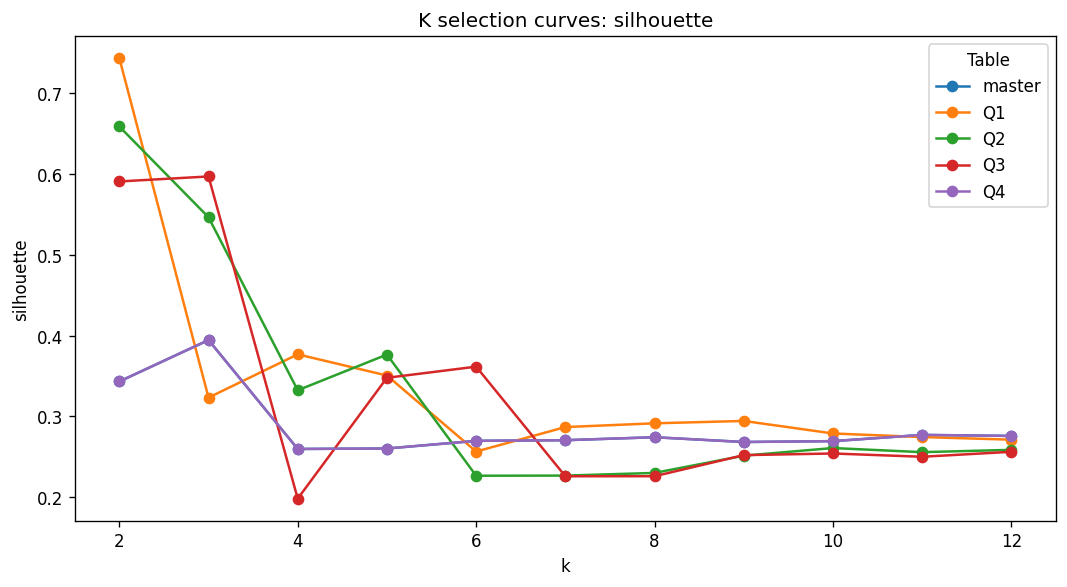

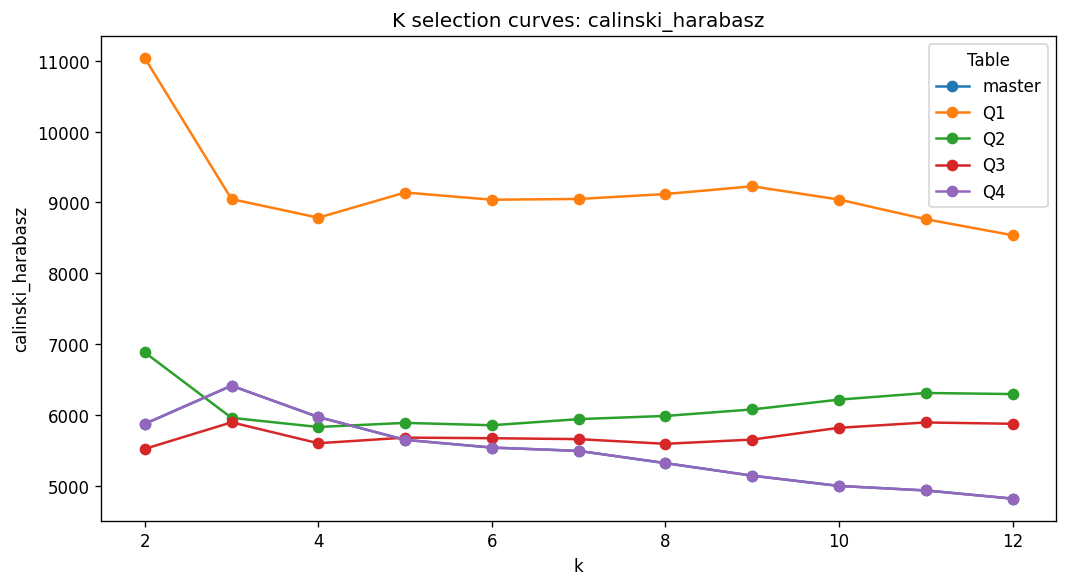

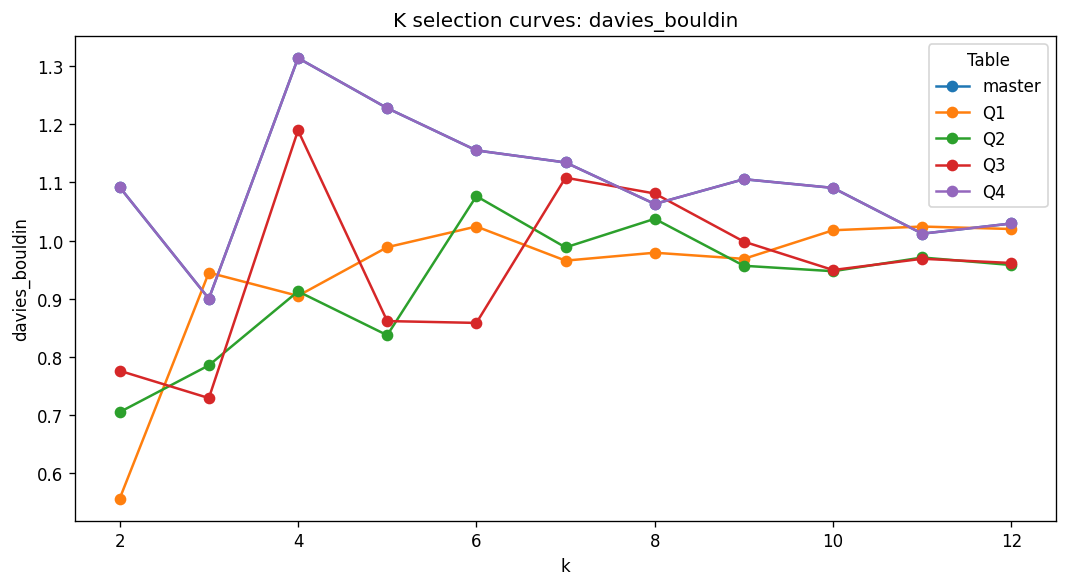

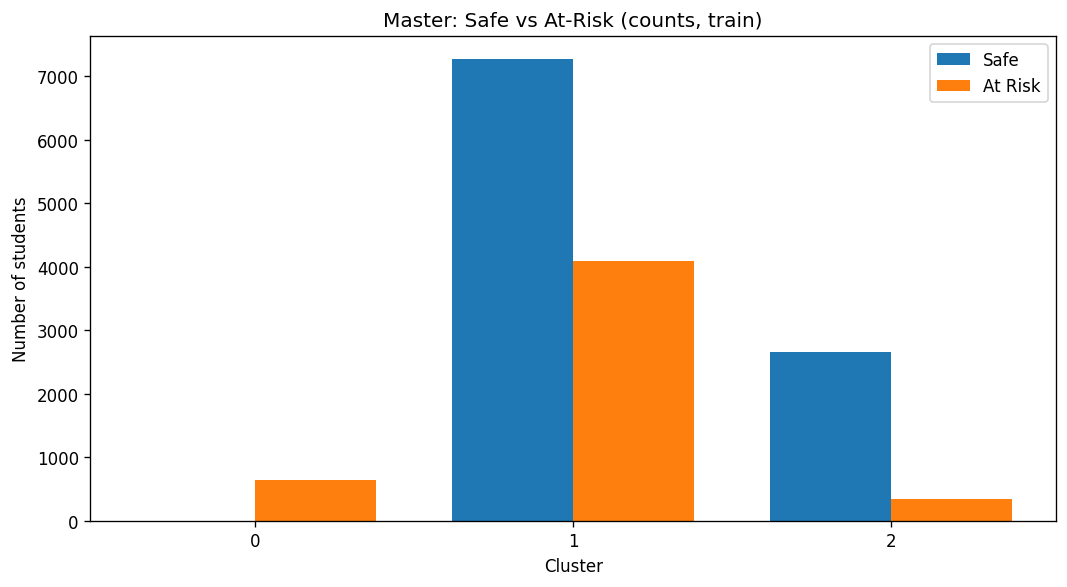

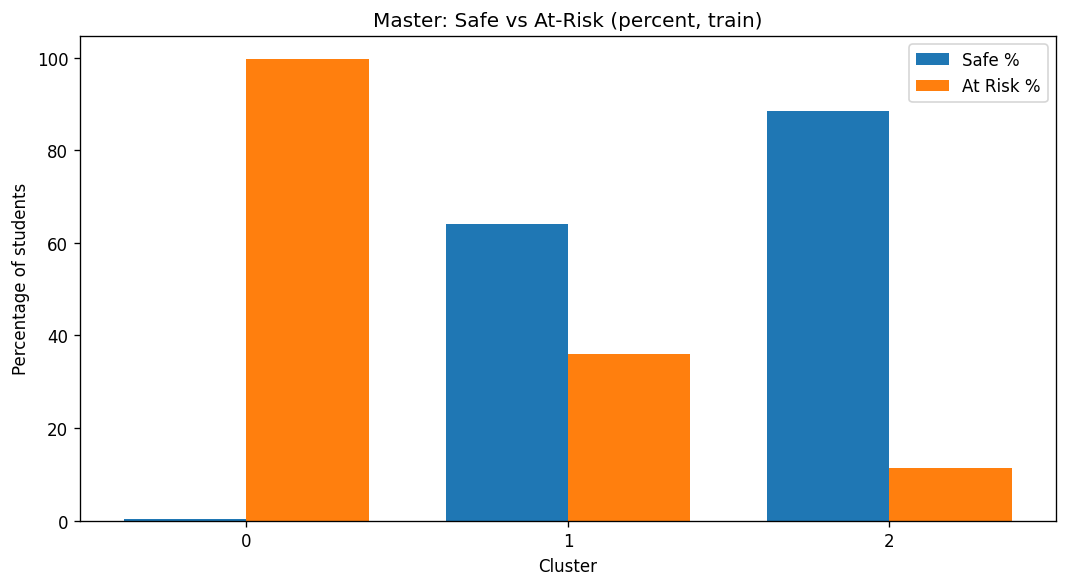

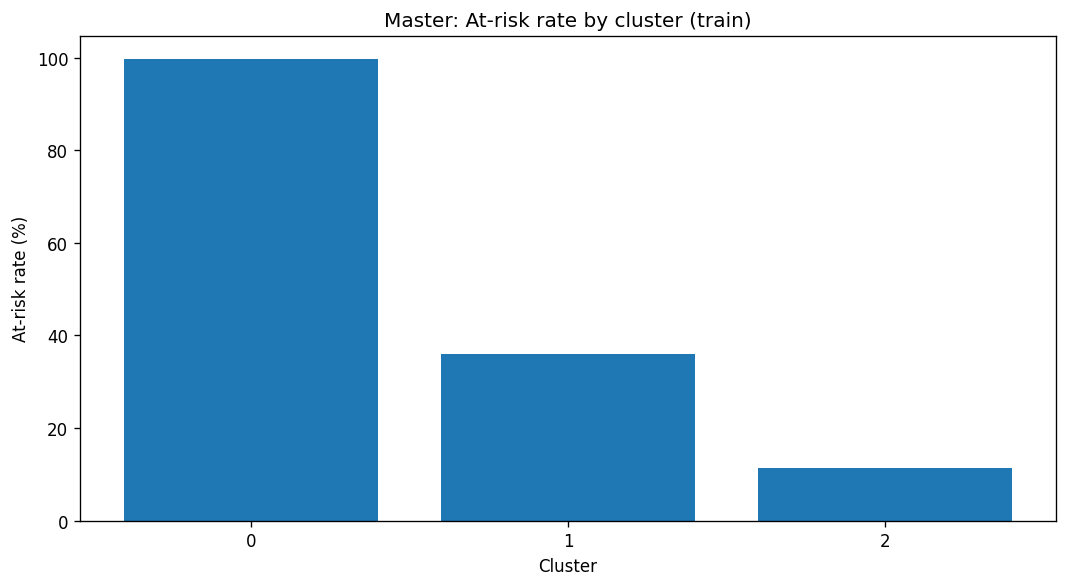

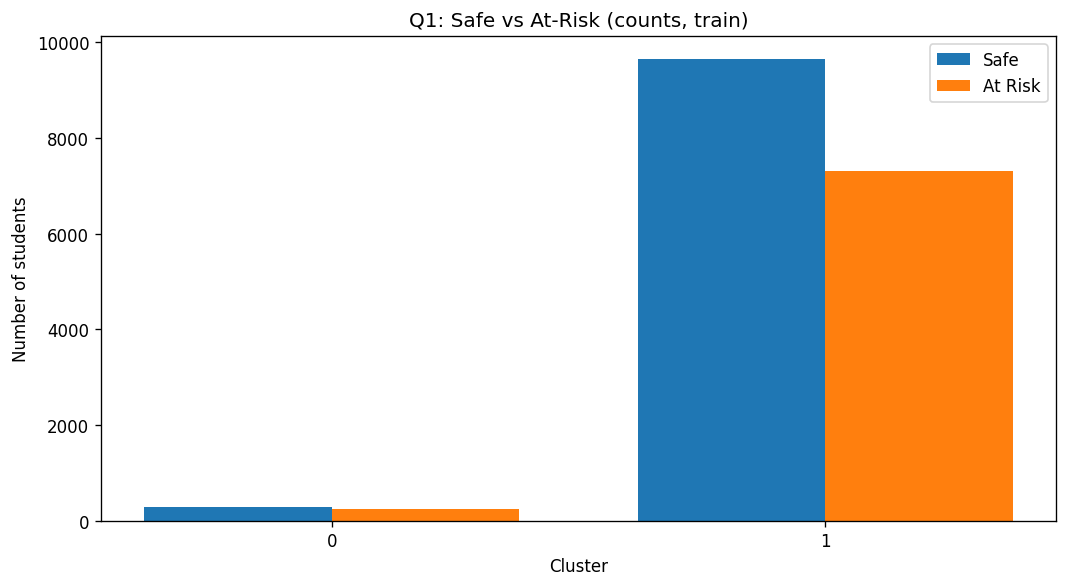

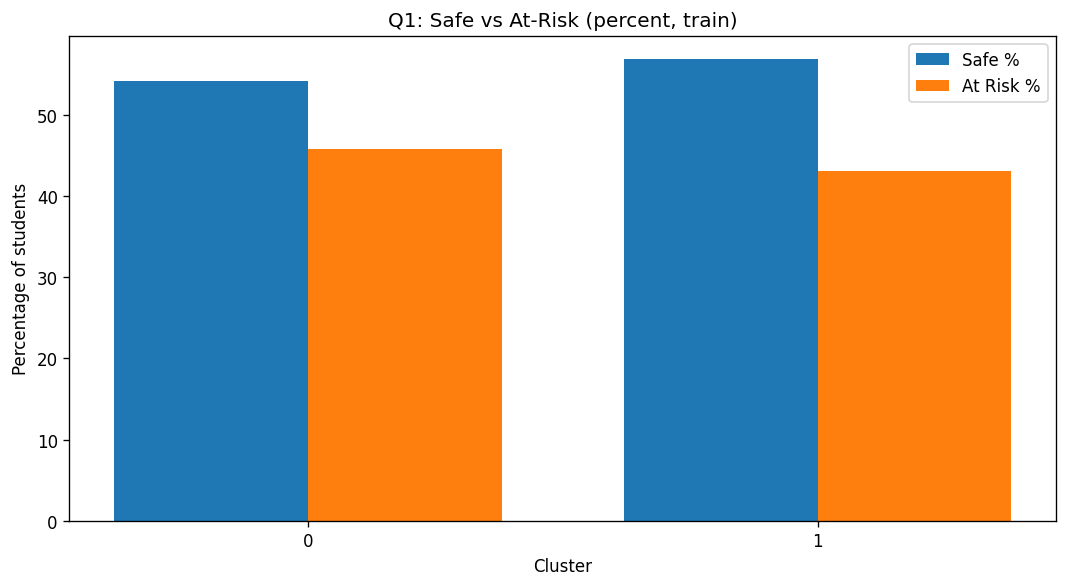

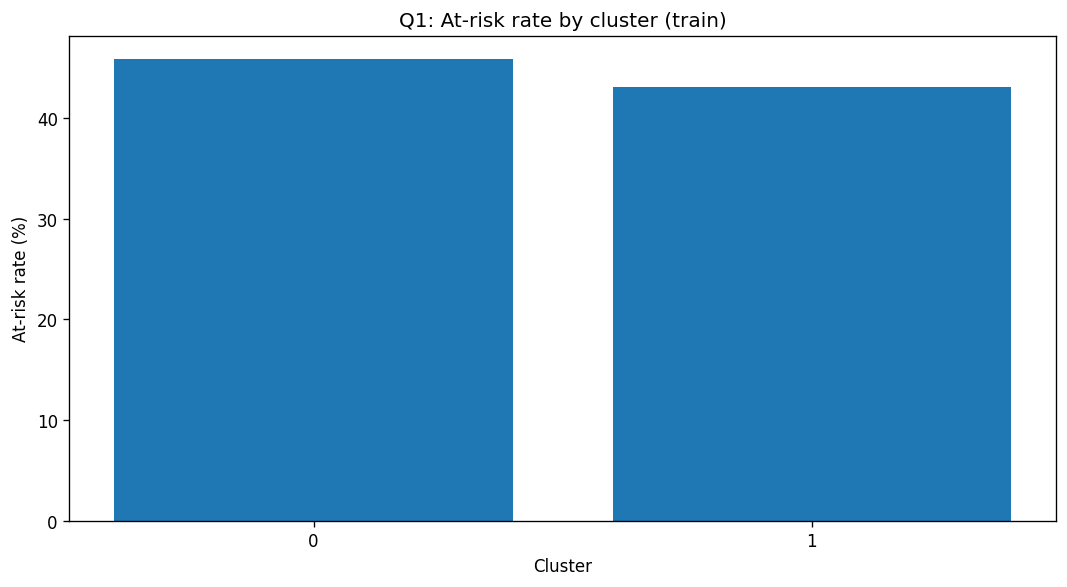

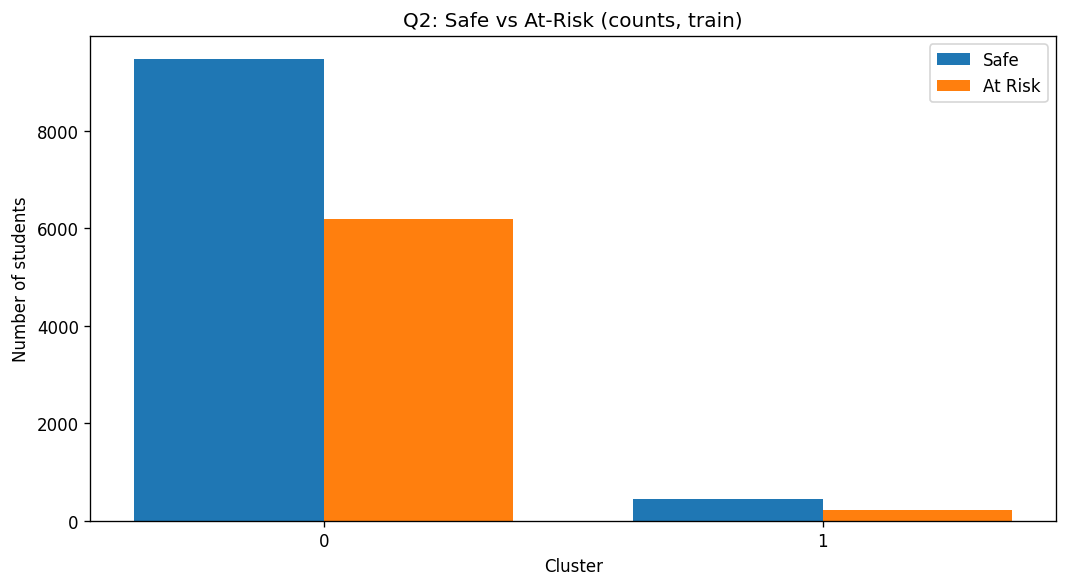

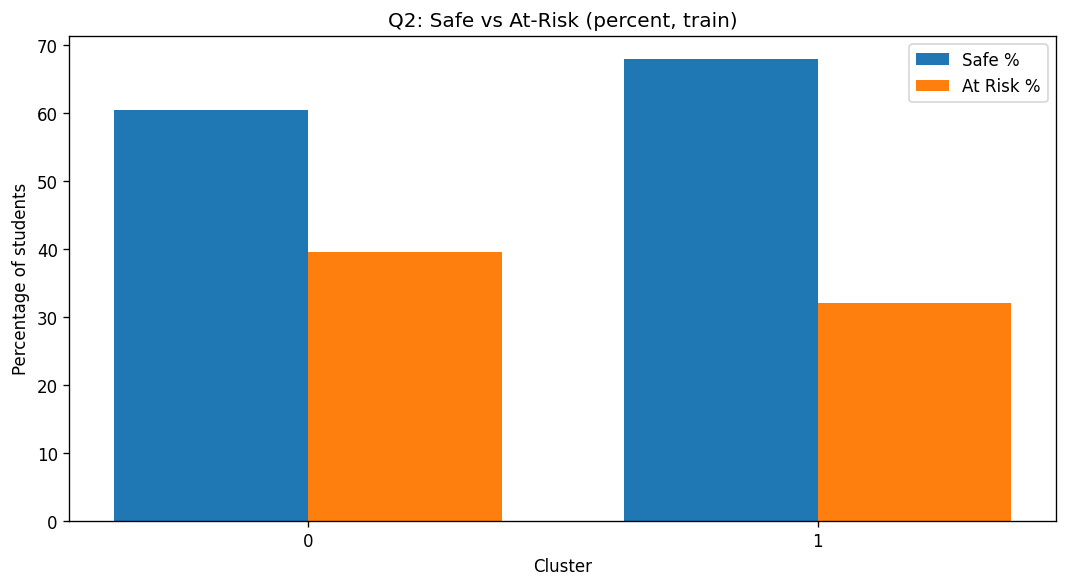

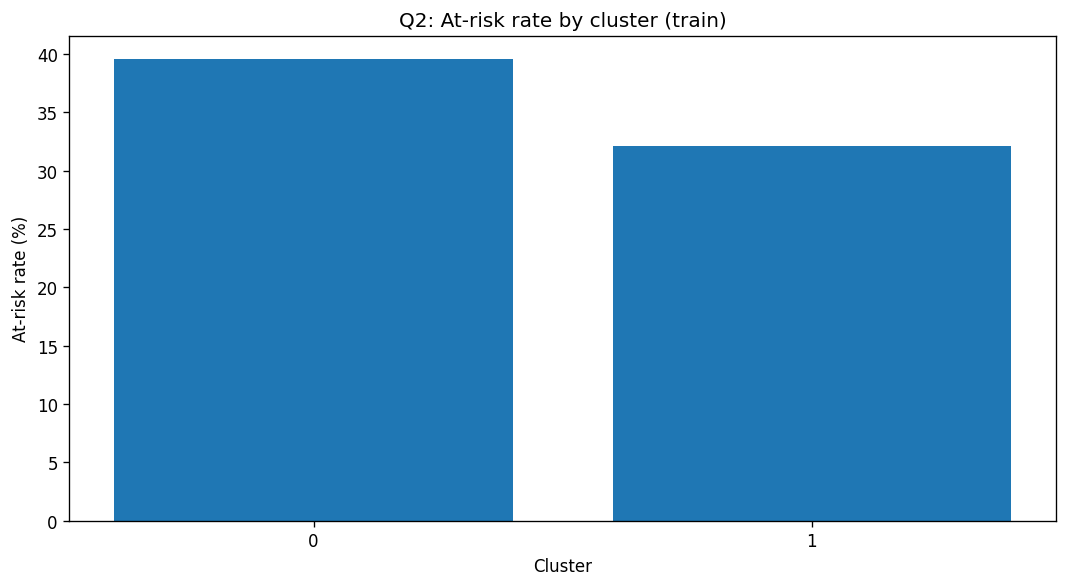

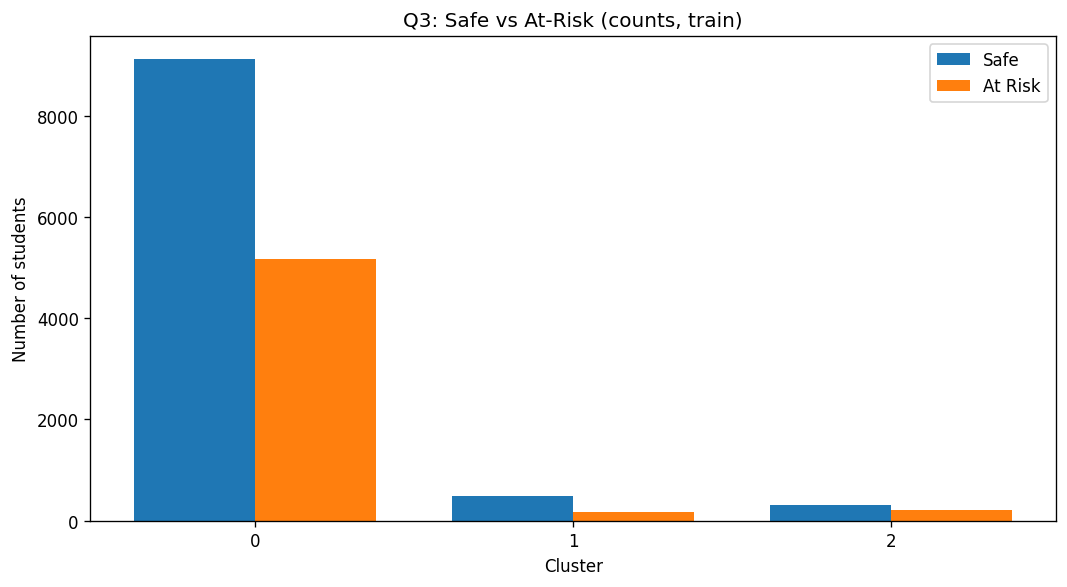

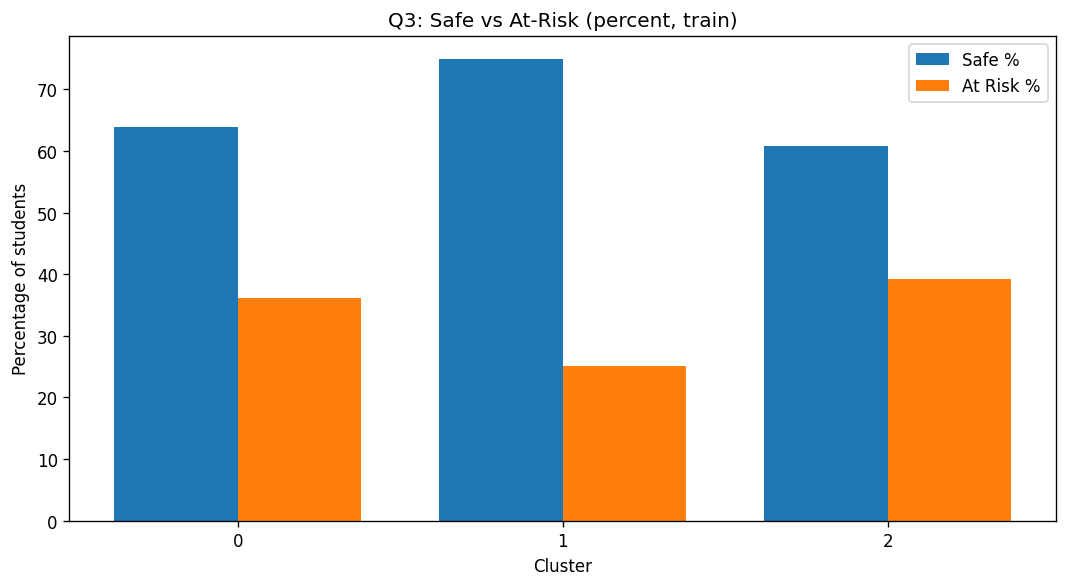

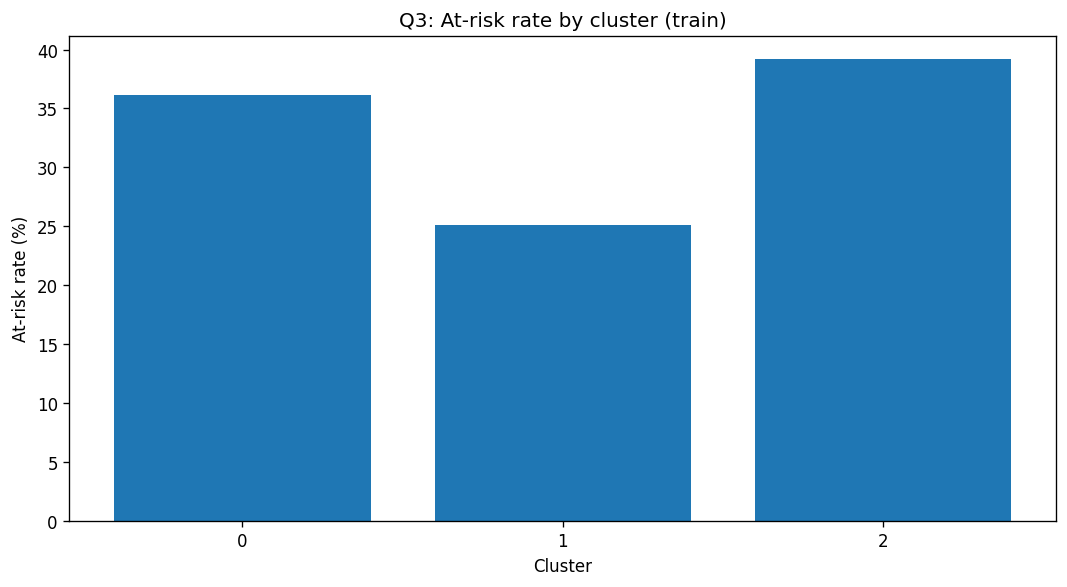

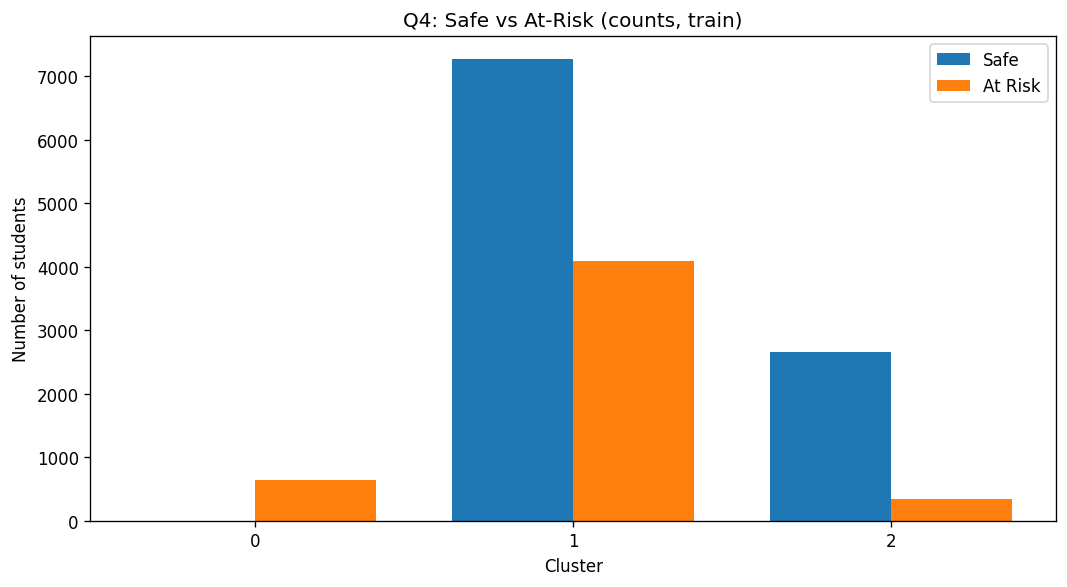

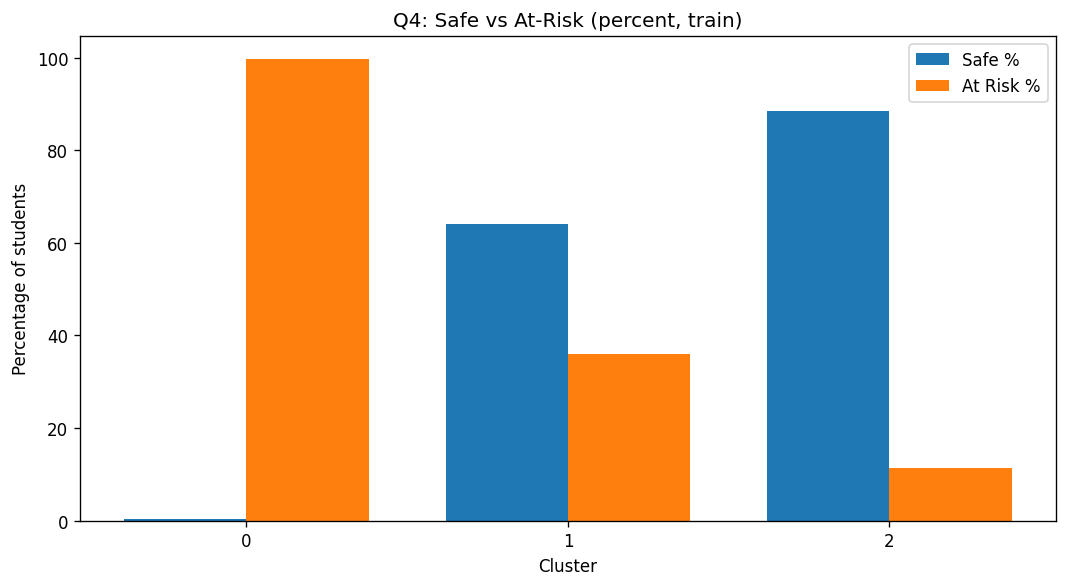

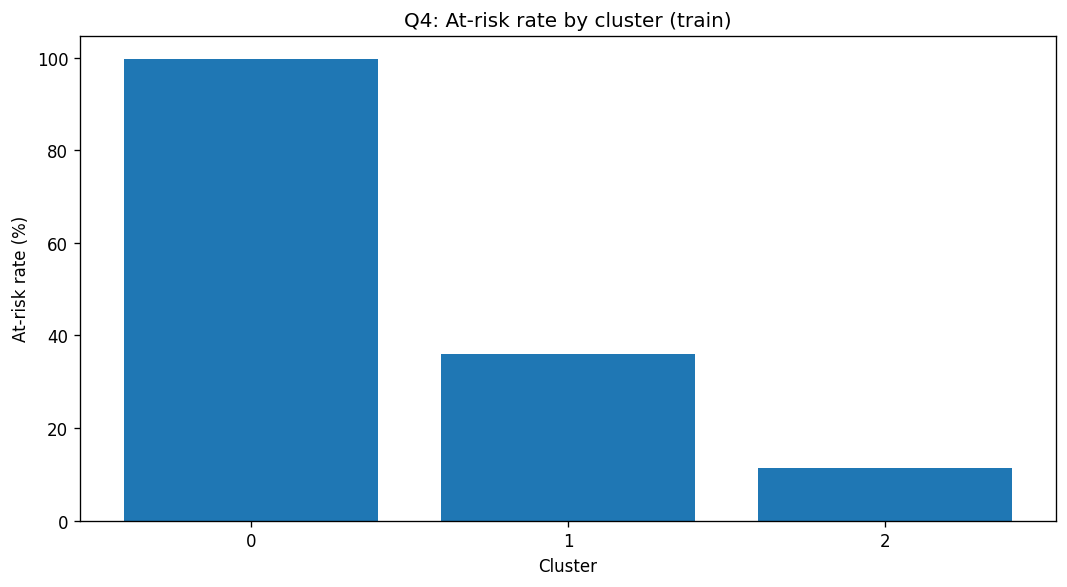

In [36]:
# Visualizatons for clustering

def _cluster_metrics_from_models(cluster_models: dict):
    rows = []
    for name, bundle in cluster_models.items():
        m = bundle.get("metrics", None)
        if m is None or len(m) == 0:
            continue
        m = m.copy()
        m["table"] = name
        rows.append(m)
    if not rows:
        return pd.DataFrame()
    out = pd.concat(rows, ignore_index=True)
    return out[["table","k","silhouette","calinski_harabasz","davies_bouldin"]]


def plot_k_selection_curves(cluster_models, tables=("master","Q1","Q2","Q3","Q4")):
    metrics_df = _cluster_metrics_from_models(cluster_models)
    if metrics_df.empty:
        print("No metrics found in cluster_models (bundle['metrics'] missing).")
        return

    for metric in ["silhouette", "calinski_harabasz", "davies_bouldin"]:
        plt.figure(figsize=(9,5))
        for t in tables:
            d = metrics_df[metrics_df["table"] == t].sort_values("k")
            if d.empty:
                continue
            plt.plot(d["k"], d[metric], marker="o", label=str(t))
        plt.title(f"K selection curves: {metric}")
        plt.xlabel("k")
        plt.ylabel(metric)
        plt.legend(title="Table")
        plt.tight_layout()
        plt.show()

def cluster_profiles_table(df, cluster_col, feature_cols, outcome_col="target_at_risk"):
    feats = safe_cols(df, feature_cols)
    base_cols = [cluster_col] + feats + ([outcome_col] if outcome_col in df.columns else [])
    base = df[base_cols].copy()

    for c in feats:
        base[c] = pd.to_numeric(base[c], errors="coerce").fillna(0.0)

    prof = base.groupby(cluster_col)[feats].mean()
    n = base.groupby(cluster_col).size().rename("n_students")
    out = prof.merge(n, left_index=True, right_index=True)

    if outcome_col in base.columns:
        at_risk = base.groupby(cluster_col)[outcome_col].mean().rename("at_risk_%") * 100.0
        out = out.merge(at_risk, left_index=True, right_index=True)

    return out.sort_index()



def plot_cluster_heatmap_with_values(df, cluster_col, feature_cols, title):
    
    profile = (
        df.groupby(cluster_col)[feature_cols]
        .mean()
        .sort_index()
    )

    plt.figure(figsize=(10,5))
    sns.heatmap(
        profile,
        annot=True,         
        fmt=".2f",          
        cmap="coolwarm",
        linewidths=0.5
    )

    plt.title(title)
    plt.xlabel("Features")
    plt.ylabel("Cluster")
    plt.tight_layout()
    plt.show()

def plot_safe_risk_side_by_side(df, cluster_col, title, outcome_col="target_at_risk"):
    dist = (
        df.groupby([cluster_col, outcome_col])
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )
    if 0 not in dist.columns: dist[0] = 0
    if 1 not in dist.columns: dist[1] = 0
    dist = dist[[0,1]]
    dist.columns = ["Safe", "At_Risk"]

    clusters = dist.index.astype(str).tolist()
    x = np.arange(len(clusters))
    w = 0.38

    plt.figure(figsize=(9,5))
    plt.bar(x - w/2, dist["Safe"].to_numpy(), w, label="Safe")
    plt.bar(x + w/2, dist["At_Risk"].to_numpy(), w, label="At Risk")
    plt.xticks(x, clusters)
    plt.xlabel("Cluster")
    plt.ylabel("Number of students")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_safe_risk_side_by_side_pct(df, cluster_col, title, outcome_col="target_at_risk"):
    dist = (
        df.groupby([cluster_col, outcome_col])
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )
    if 0 not in dist.columns: dist[0] = 0
    if 1 not in dist.columns: dist[1] = 0
    dist = dist[[0,1]]
    dist = dist.div(dist.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0) * 100.0
    dist.columns = ["Safe_%", "At_Risk_%"]

    clusters = dist.index.astype(str).tolist()
    x = np.arange(len(clusters))
    w = 0.38

    plt.figure(figsize=(9,5))
    plt.bar(x - w/2, dist["Safe_%"].to_numpy(), w, label="Safe %")
    plt.bar(x + w/2, dist["At_Risk_%"].to_numpy(), w, label="At Risk %")
    plt.xticks(x, clusters)
    plt.xlabel("Cluster")
    plt.ylabel("Percentage of students")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_risk_rate_by_cluster(df, cluster_col, title, outcome_col="target_at_risk"):
    rate = df.groupby(cluster_col)[outcome_col].mean().sort_index() * 100.0
    clusters = rate.index.astype(str).tolist()
    x = np.arange(len(clusters))

    plt.figure(figsize=(9,5))
    plt.bar(x, rate.to_numpy())
    plt.xticks(x, clusters)
    plt.xlabel("Cluster")
    plt.ylabel("At-risk rate (%)")
    plt.title(title)
    plt.tight_layout()
    plt.show()


def visualize_all(ml_master_train, ml_Q1_train, ml_Q2_train, ml_Q3_train, ml_Q4_train,
                  CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
                  cluster_models=None):

    if cluster_models is not None:
        plot_k_selection_curves(cluster_models, tables=("master","Q1","Q2","Q3","Q4"))

    plot_safe_risk_side_by_side(
        ml_master_train, "cluster_master_id",
        "Master: Safe vs At-Risk (counts, train)"
    )
    plot_safe_risk_side_by_side_pct(
        ml_master_train, "cluster_master_id",
        "Master: Safe vs At-Risk (percent, train)"
    )
    plot_risk_rate_by_cluster(
        ml_master_train, "cluster_master_id",
        "Master: At-risk rate by cluster (train)"
    )

    quarter_map = {
        "Q1": (ml_Q1_train, "cluster_Q1_id"),
        "Q2": (ml_Q2_train, "cluster_Q2_id"),
        "Q3": (ml_Q3_train, "cluster_Q3_id"),
        "Q4": (ml_Q4_train, "cluster_Q4_id"),
    }
    for q, (df, ccol) in quarter_map.items():
        plot_safe_risk_side_by_side(
            df, ccol,
            f"{q}: Safe vs At-Risk (counts, train)"
        )
        plot_safe_risk_side_by_side_pct(
            df, ccol,
            f"{q}: Safe vs At-Risk (percent, train)"
        )
        plot_risk_rate_by_cluster(
            df, ccol,
            f"{q}: At-risk rate by cluster (train)"
        )


visualize_all(
    ml_master_train, ml_Q1_train, ml_Q2_train, ml_Q3_train, ml_Q4_train,
    CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
    cluster_models=cluster_models 
)

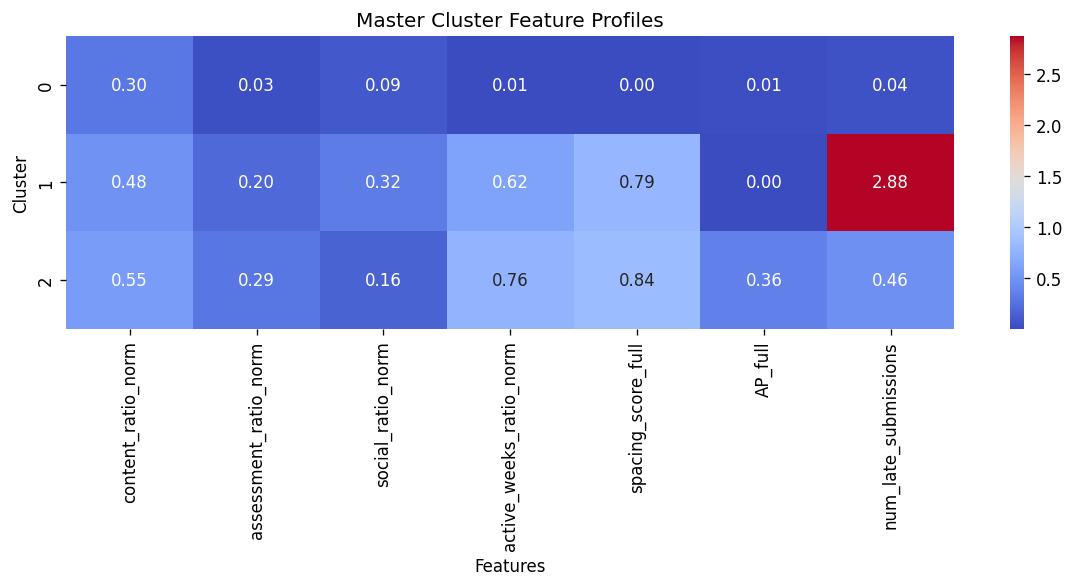

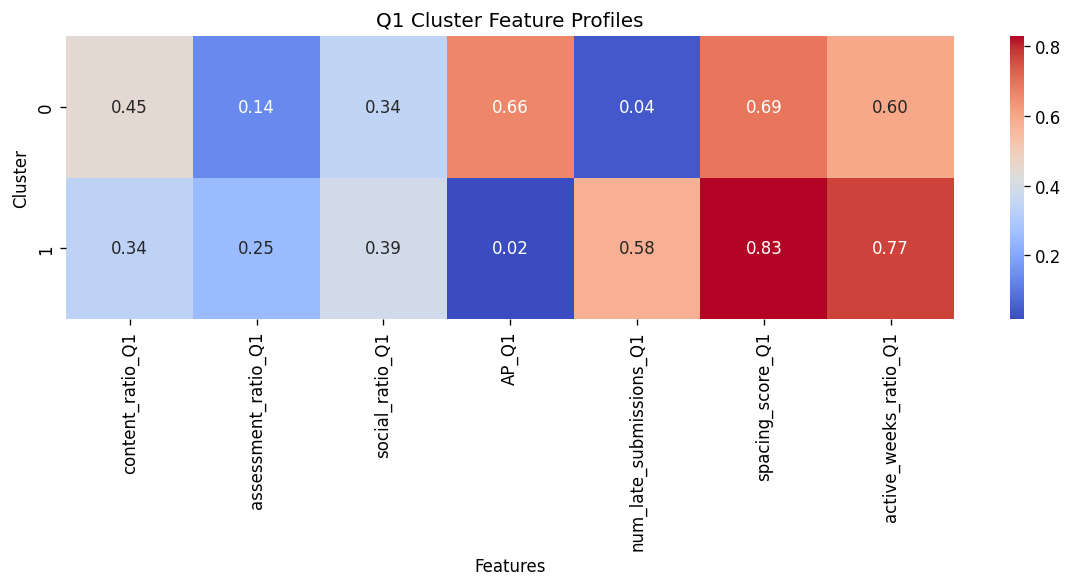

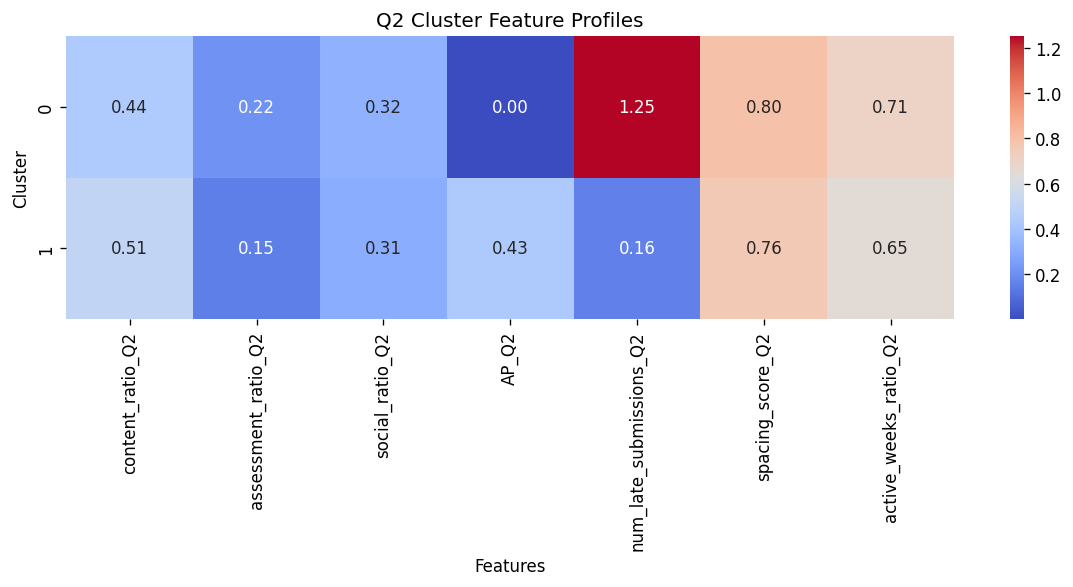

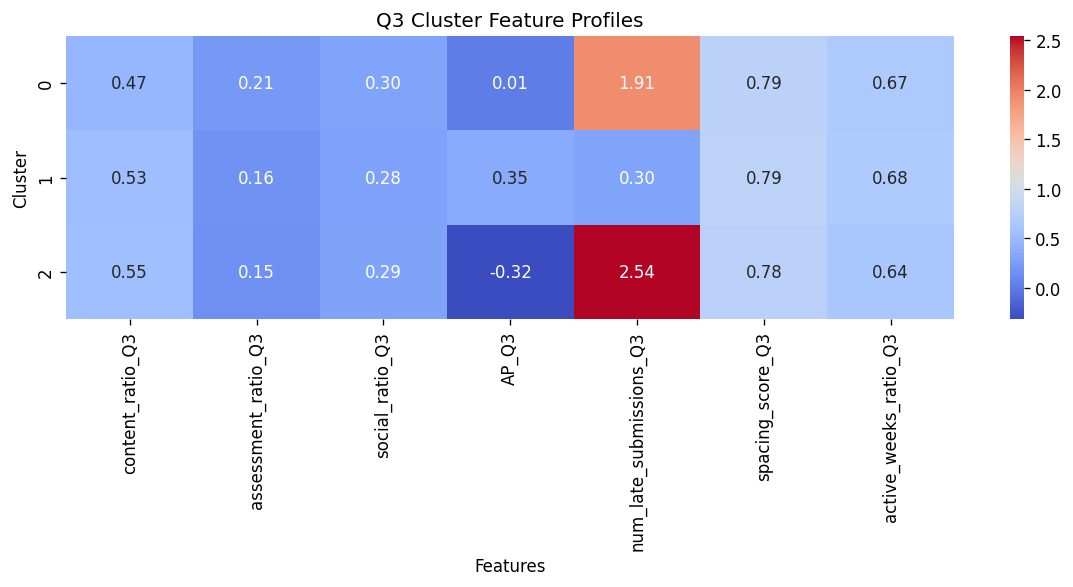

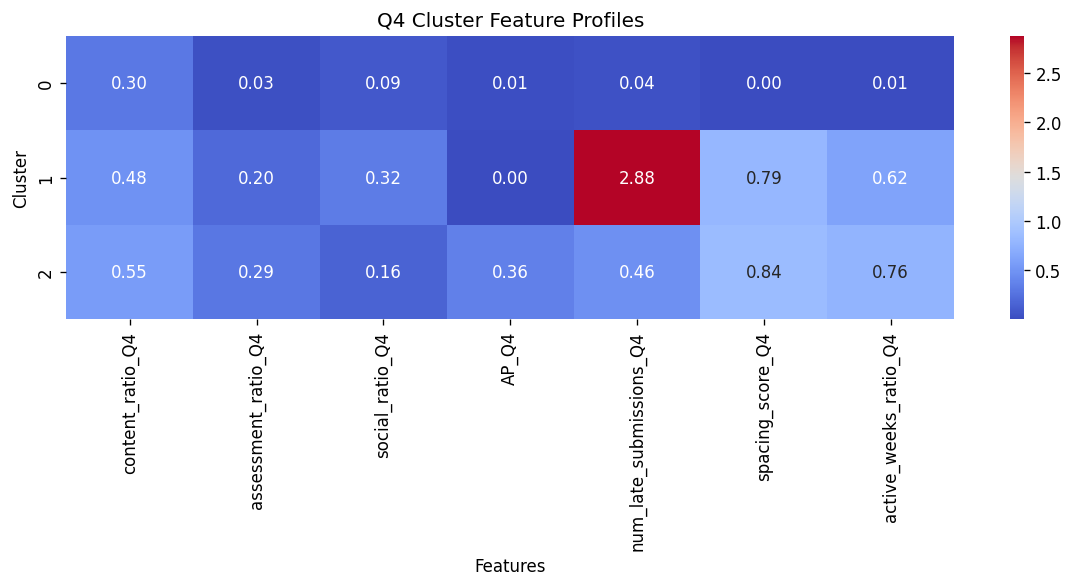

In [37]:
# Visualizations for clusters 
def plot_cluster_heatmap(df, cluster_col, feature_cols, title):
    profile = (
        df.groupby(cluster_col)[feature_cols]
        .mean()
    )

    plt.figure(figsize=(10,5))
    sns.heatmap(profile, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel("Features")
    plt.ylabel("Cluster")
    plt.tight_layout()
    plt.show()

plot_cluster_heatmap(
    df=ml_master_train,
    cluster_col="cluster_master_id",
    feature_cols=CLUSTERING_FEATURES,
    title="Master Cluster Feature Profiles"
)

plot_cluster_heatmap(
    ml_Q1_train,
    cluster_col="cluster_Q1_id",
    feature_cols=CLUSTER_FEATURES_Q["Q1"],
    title="Q1 Cluster Feature Profiles"
)

plot_cluster_heatmap(
    ml_Q2_train,
    cluster_col="cluster_Q2_id",
    feature_cols=CLUSTER_FEATURES_Q["Q2"],
    title="Q2 Cluster Feature Profiles"
)

plot_cluster_heatmap(
    ml_Q3_train,
    cluster_col="cluster_Q3_id",
    feature_cols=CLUSTER_FEATURES_Q["Q3"],
    title="Q3 Cluster Feature Profiles"
)

plot_cluster_heatmap(
    ml_Q4_train,
    cluster_col="cluster_Q4_id",
    feature_cols=CLUSTER_FEATURES_Q["Q4"],
    title="Q4 Cluster Feature Profiles"
)

## Integration preflight — cluster and enrollment contracts

In [38]:
# INTEGRATION PREFLIGHT — validate training-fitted clusters and actionable student populations.
# Runs before recommendation logic; deliberately does not retrain any prediction model.
required_2026 = ["enrollment_lookup", "FULL_TEST_WINDOWS", "ENROLLED_WINDOWS",
                 "TRAIN_ENGAGEMENT_REFERENCE", "cluster_models", "CLUSTERING_FEATURES",
                 "CLUSTER_FEATURES_Q", "ml_master_train", "ml_master_test"]
missing_globals = [name for name in required_2026 if name not in globals()]
if missing_globals:
    raise RuntimeError(f"Updated clustering dependencies missing: {missing_globals}. Run earlier cells in order.")
for window in ["master", "Q1", "Q2", "Q3", "Q4"]:
    name = "master" if window == "master" else window
    train_df = globals()[f"ml_{name}_train"]
    live_df = globals()[f"ml_{name}_test"]
    cluster_col = "cluster_master_id" if name == "master" else f"cluster_{name}_id"
    feature_cols = CLUSTERING_FEATURES if name == "master" else CLUSTER_FEATURES_Q[name]
    assert name in cluster_models, f"Missing fitted training-only cluster model for {name}"
    for label, df in [("train",train_df), ("test",live_df)]:
        assert not df.duplicated(KEYS).any(), f"{name} {label}: duplicate student keys"
        missing = [col for col in [cluster_col, *feature_cols] if col not in df.columns]
        assert not missing, f"{name} {label}: missing cluster fields {missing}"
        assert df[cluster_col].notna().all(), f"{name} {label}: unassigned clusters"
        assert pd.to_numeric(df[cluster_col], errors="coerce").notna().all(), f"{name} {label}: nonnumeric cluster IDs"
    overlap = train_df[KEYS].merge(live_df[KEYS], on=KEYS, how="inner")
    assert overlap.empty, f"{name}: training/test student keys overlap"
    if name != "master":
        eligible = enrolled_only_dataset(live_df, name, enrollment_lookup, KEYS)
        assert len(eligible) == len(live_df), f"{name}: ineligible test students remain"
    print(f"{name:6}: train={len(train_df):6,} test={len(live_df):6,} "
          f"clusters={train_df[cluster_col].nunique():2} features={len(feature_cols):2}")
print("PASS: latest feature engineering, enrollment and fitted clustering are connected.")


master: train=15,001 test= 7,521 clusters= 3 features= 7
Q1    : train=17,462 test= 8,703 clusters= 2 features= 7
Q2    : train=16,343 test= 8,121 clusters= 2 features= 7
Q3    : train=15,456 test= 7,623 clusters= 3 features= 7
Q4    : train=15,001 test= 7,521 clusters= 3 features= 7
PASS: latest feature engineering, enrollment and fitted clustering are connected.


## Recommendation layer — preserved from the newer recommendation notebook

### Recommendation 

### Final-outcome leakage safeguard (Point 2)

**Operational student inputs are stripped of final-result labels and model predictions.** Only the historical *training* outcomes may define successful-peer benchmarks. Held-out outcomes are retained separately for retrospective evaluation and are not passed to the recommendation function. The Q2 Table 9.5 export rejects stale summaries and requires outcome-flip, outcome-removal, and prediction-independence tests.

Re-execute the function-definition cells, Q2 evaluation, all-quarter evaluation, validation and Table 9.5 export after this update. Saved results from older runs are intentionally cleared; classification models do not need retraining.


In [39]:
# Intervention catalogue

import numpy as np
import pandas as pd
from scipy.stats import pointbiserialr, f_oneway

# A1 — Intervention catalogue

INTERVENTION_CATALOGUE = {

    #  Assessment behaviour 
    "AP_full": {
        "title":     "Submit Assessments Earlier",
        "detail":    (
            "Your submission timing score is {student_val:.2f} vs {peer_val:.2f} for "
            "passing students in your cluster. Submitting earlier gives you time to "
            "review feedback before the next task."
        ),
        "category":  "assessment",
        "tier":      1,
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "num_late_submissions": {
        "title":     "Reduce Late Submissions",
        "detail":    (
            "You have {student_val:.0f} late submission(s); successful peers average "
            "{peer_val:.1f}. Submitting even one day early reduces stress and "
            "protects your grade."
        ),
        "category":  "assessment",
        "tier":      1,
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "assessment_ratio_norm": {
        "title":     "Practise More Assessment Activities",
        "detail":    (
            "Assessment activities make up {student_pct:.0f}% of your engagement "
            "vs {peer_pct:.0f}% for peers who passed. Regular quiz and self-test "
            "practice strengthens recall and identifies gaps early."
        ),
        "category":  "assessment",
        "tier":      1,
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },

    # Content engagement 
    "content_ratio_norm": {
        "title":     "Engage More With Course Content",
        "detail":    (
            "Only {student_pct:.0f}% of your activity is on course materials vs "
            "{peer_pct:.0f}% for passing students. Prioritise readings and core "
            "resources before attempting assessments."
        ),
        "category":  "content",
        "tier":      1,
        "vle_types": ["oucontent", "resource", "url", "page", "subpage",
                      "homepage", "folder", "glossary", "htmlactivity"],
    },

    #  Consistency / self-regulation 
    "active_weeks_ratio_norm": {
        "title":     "Study More Consistently",
        "detail":    (
            "You were active in {student_pct:.0f}% of course weeks. Passing students "
            "in your group averaged {peer_pct:.0f}%. Logging in regularly — even for "
            "short sessions — outperforms occasional long ones."
        ),
        "category":  "consistency",
        "tier":      1,
        "vle_types": [],
    },
    "spacing_score_full": {
        "title":     "Spread Your Study Sessions",
        "detail":    (
            "Your spacing score is {student_val:.2f} vs {peer_val:.2f} for successful "
            "peers. Clustering all activity into a few days reduces retention. Aim for "
            "shorter, evenly distributed sessions each week."
        ),
        "category":  "consistency",
        "tier":      1,
        "vle_types": [],
    },

    # Social engagement 
    "social_ratio_norm": {
        "title":     "Participate in Discussions",
        "detail":    (
            "Forum and collaborative tool usage is {student_pct:.0f}% of your activity "
            "vs {peer_pct:.0f}% for peers who passed. Posting a question or reply "
            "once a week consistently improves learning outcomes."
        ),
        "category":  "social",
        "tier":      1,
        "vle_types": ["forumng", "ouwiki", "oucollaborate", "ouelluminate",
                      "dataplus", "sharedsubpage"],
    },
}

#  Quarter variants — generated programmatically 
_Q_TEMPLATES = {
    "AP": {
        "title_tpl":  "Submit Earlier ({q})",
        "detail_tpl": (
            "Your submission timing this quarter ({student_val:.2f}) is below "
            "the peer average ({peer_val:.2f}). Earlier submissions give you time "
            "to act on feedback before the next quarter."
        ),
        "category":  "assessment",
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "num_late_submissions": {
        "title_tpl":  "Reduce Late Submissions ({q})",
        "detail_tpl": (
            "You have {student_val:.0f} late submission(s) this quarter; peers "
            "who passed averaged {peer_val:.1f}."
        ),
        "category":  "assessment",
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "active_weeks_ratio": {
        "title_tpl":  "Study More Consistently ({q})",
        "detail_tpl": (
            "You were active in {student_pct:.0f}% of weeks this quarter. "
            "Passing students averaged {peer_pct:.0f}%. Short regular sessions "
            "beat occasional long ones."
        ),
        "category":  "consistency",
        "vle_types": [],
    },
    "spacing_score": {
        "title_tpl":  "Spread Your Sessions ({q})",
        "detail_tpl": (
            "Your spacing score this quarter is {student_val:.2f} vs "
            "{peer_val:.2f}. Distribute study time more evenly across the weeks."
        ),
        "category":  "consistency",
        "vle_types": [],
    },
    "content_ratio": {
        "title_tpl":  "Engage With Course Content ({q})",
        "detail_tpl": (
            "{student_pct:.0f}% of your activity this quarter is on course "
            "content vs {peer_pct:.0f}% for passing students."
        ),
        "category":  "content",
        "vle_types": ["oucontent", "resource", "url", "page", "subpage",
                      "homepage", "folder", "glossary", "htmlactivity"],
    },
    "assessment_ratio": {
        "title_tpl":  "Practise Assessments ({q})",
        "detail_tpl": (
            "Assessment activity is {student_pct:.0f}% of your engagement this "
            "quarter vs {peer_pct:.0f}% for peers who passed."
        ),
        "category":  "assessment",
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "social_ratio": {
        "title_tpl":  "Join the Discussion ({q})",
        "detail_tpl": (
            "Forum and collaborative usage is {student_pct:.0f}% of your activity "
            "this quarter vs {peer_pct:.0f}% for peers who passed."
        ),
        "category":  "social",
        "vle_types": ["forumng", "ouwiki", "oucollaborate"],
    },
}

for _base, _cfg in _Q_TEMPLATES.items():
    for _q in ["Q1", "Q2", "Q3", "Q4"]:
        INTERVENTION_CATALOGUE[f"{_base}_{_q}"] = {
            "title":     _cfg["title_tpl"].format(q=_q),
            "detail":    _cfg["detail_tpl"],
            "category":  _cfg["category"],
            "tier":      1,
            "vle_types": _cfg["vle_types"],
        }

_GENERIC_ENTRY = {
    "title":     "Improve {feature}",
    "detail":    (
        "Your value ({student_val:.2f}) is below the peer benchmark ({peer_val:.2f}). "
        "Closing this gap is associated with better outcomes in your learning group."
    ),
    "category":  "general",
    "tier":      1,
    "vle_types": [],
}

# A2 — Feature direction sets

HIGHER_IS_BETTER = {
    "active_weeks_ratio_norm", "spacing_score_full", "AP_full",
    "content_ratio_norm", "assessment_ratio_norm", "social_ratio_norm",
    *{f"active_weeks_ratio_{q}" for q in ["Q1","Q2","Q3","Q4"]},
    *{f"spacing_score_{q}"      for q in ["Q1","Q2","Q3","Q4"]},
    *{f"AP_{q}"                 for q in ["Q1","Q2","Q3","Q4"]},
    *{f"content_ratio_{q}"      for q in ["Q1","Q2","Q3","Q4"]},
    *{f"social_ratio_{q}"       for q in ["Q1","Q2","Q3","Q4"]},
    *{f"assessment_ratio_{q}"   for q in ["Q1","Q2","Q3","Q4"]},
}

LOWER_IS_BETTER = {
    "num_late_submissions",
    *{f"num_late_submissions_{q}" for q in ["Q1","Q2","Q3","Q4"]},
}

# A3 — VLE category - activity_type mapping (for hybrid resource layer)

CATEGORY_TO_VLE = {
    "assessment":  {"quiz", "externalquiz", "questionnaire"},
    "content":     {"oucontent", "resource", "url", "page", "subpage",
                    "homepage", "folder", "glossary", "htmlactivity"},
    "social":      {"forumng", "ouwiki", "oucollaborate", "ouelluminate",
                    "dataplus", "sharedsubpage"},
    "consistency": set(),   # behavioural — no specific resource type
}

VLE_DISPLAY_NAMES = {
    "quiz":          "Practice Quiz",
    "externalquiz":  "External Quiz",
    "questionnaire": "Questionnaire",
    "oucontent":     "Course Content",
    "resource":      "Resource Document",
    "url":           "External Link",
    "page":          "Course Page",
    "subpage":       "Sub-page",
    "forumng":       "Discussion Forum",
    "ouwiki":        "Collaborative Wiki",
    "oucollaborate": "Collaboration Tool",
    "htmlactivity":  "Interactive Activity",
    "folder":        "Resource Folder",
    "glossary":      "Glossary",
}

# ---------------------------------------------
# Operational / evaluation label isolation
# ---------------------------------------------
# These are retrospective labels or prediction outputs, NOT checkpoint-observable
# student behaviours. Training labels may still be used to learn historical
# successful-peer benchmarks and feature weights, but are never retained on
# the live student row passed to recommendation functions.
RECOMMENDATION_LOGIC_VERSION = "outcome_blind_checkpoint_v2"
_RECOMMENDATION_NONOPERATIONAL_FIELDS = frozenset({
    "target_at_risk", "at_risk", "final_result", "final_outcome",
    "y_true", "predicted_class", "predicted_label", "risk_probability",
    "prediction_available", "model_risk_score",
})


def _operational_student_view(student_row):
    """Return a new Series with all held-out outcome/prediction fields removed."""
    if not isinstance(student_row, pd.Series):
        raise TypeError("Recommendation input must be one student's pandas Series")
    return student_row.drop(
        labels=[c for c in _RECOMMENDATION_NONOPERATIONAL_FIELDS if c in student_row.index]
    ).copy()


# A4 — Intervention intensity (operational; no future outcome label)
#
# IMPORTANT:
#   This function deliberately does NOT use the live/test student's target_at_risk.
#   Intervention intensity is based only on observable behavioural-gap severity,
#   the number of meaningful gaps, and the current course stage.
#
#  Tier 1: Self-guided support      — no/mild behavioural gaps
#  Tier 2: Targeted support         — severe or multiple behavioural gaps
#  Tier 3: Instructor follow-up     — persistent/severe gaps at a later stage

def assign_intervention_tier(
    n_gaps,
    max_gap_severity,
    mean_gap_severity,
    quarter,
):
    """
    Assign operational intervention intensity without reading the student's
    eventual outcome label.

    Tier 0 = no additional action
    Tier 1 = self-guided support
    Tier 2 = targeted support
    Tier 3 = instructor follow-up
    """
    n_gaps = int(n_gaps)
    max_gap_severity = float(max_gap_severity or 0.0)
    mean_gap_severity = float(mean_gap_severity or 0.0)

    late_quarter = quarter in ("Q3", "Q4", "master")
    severe_gap = max_gap_severity >= 1.50
    multiple_gaps = n_gaps >= 3
    sustained_gap_load = n_gaps >= 2 and mean_gap_severity >= 1.00

    if n_gaps == 0:
        return (
            0,
            "No Additional Action",
            "No behavioural gap currently exceeds the recommendation threshold.",
        )

    if late_quarter and severe_gap and n_gaps >= 2:
        return (
            3,
            "Instructor Follow-up",
            "Multiple behavioural gaps remain and at least one is severe at a later course stage. "
            "A direct educator check-in is appropriate.",
        )

    if severe_gap or multiple_gaps or sustained_gap_load:
        return (
            2,
            "Targeted Support",
            "The learner shows a severe or repeated behavioural gap. "
            "A targeted support action is appropriate.",
        )

    return (
        1,
        "Self-Guided Support",
        "A small number of meaningful behavioural gaps can be addressed with self-guided prompts.",
    )


# A5 — Quarter context descriptors

QUARTER_CONTEXT = {
    "Q1": {
        "label":      "Quarter 1 — Early Course",
        "focus":      "Habit formation and initial engagement.",
        "guidance":   "High uncertainty — use low-cost nudges only.",
        "confidence": "low",
    },
    "Q2": {
        "label":      "Quarter 2 — Primary Checkpoint ★",
        "focus":      "Main intervention window.",
        "guidance":   "Best balance of evidence and time to act. Recommended deployment point.",
        "confidence": "medium",
    },
    "Q3": {
        "label":      "Quarter 3 — Refinement Checkpoint",
        "focus":      "Escalate if weak patterns from Q2 persist.",
        "guidance":   "Escalation is appropriate for unresolved gaps.",
        "confidence": "high",
    },
    "Q4": {
        "label":      "Quarter 4 — Late Course",
        "focus":      "Diagnostic and support continuation.",
        "guidance":   "Limited recovery time — escalate persistent cases.",
        "confidence": "high",
    },
    "master": {
        "label":      "Full Course View",
        "focus":      "Complete behavioural profile across all weeks.",
        "guidance":   "Use for retrospective analysis and full-course support.",
        "confidence": "high",
    },
}


In [40]:
# Compute feature importance weights

def _compute_risk_correlation_weights(df, feature_cols, target_col="target_at_risk"):
    """
    Point-biserial |correlation| of each feature with the binary risk label.
    Answers: does this behaviour actually relate to academic risk?
    Returns {feature: normalised_weight}.
    """
    weights = {}
    y = df[target_col].values
    for feat in feature_cols:
        x = pd.to_numeric(df[feat], errors="coerce").fillna(0.0).values
        if x.std() < 1e-9:
            weights[feat] = 0.0
            continue
        corr, _        = pointbiserialr(y, x)
        weights[feat]  = abs(corr)
    total = sum(weights.values()) + 1e-9
    return {k: v / total for k, v in weights.items()}


def _compute_cluster_separability_weights(df, feature_cols, cluster_col):
    """
    ANOVA F-statistic of each feature across clusters.
    Answers: does this behaviour define how students are grouped?
    Returns {feature: normalised_weight}.
    """
    weights = {}
    for feat in feature_cols:
        groups = [grp[feat].dropna().values for _, grp in df.groupby(cluster_col)]
        groups = [g for g in groups if len(g) > 1]
        if len(groups) < 2:
            weights[feat] = 0.0
            continue
        f_stat, _      = f_oneway(*groups)
        weights[feat]  = max(float(f_stat), 0.0)
    total = sum(weights.values()) + 1e-9
    return {k: v / total for k, v in weights.items()}


def _apply_redundancy_penalty(weights, df, feature_cols, threshold=0.75):
    """
    Damp the weight of any feature that is highly correlated with a
    higher-weighted feature. Prevents near-identical behaviours from
    producing duplicate recommendations at the top of the list.
    Applied AFTER compositing, not before.
    """
    available   = [f for f in feature_cols if f in df.columns]
    corr_matrix = df[available].corr().abs()
    penalised   = weights.copy()
    seen        = set()

    for feat, _ in sorted(weights.items(), key=lambda x: x[1], reverse=True):
        if feat in seen:
            continue
        seen.add(feat)
        for other in available:
            if other == feat or other in seen:
                continue
            if corr_matrix.loc[feat, other] > threshold:
                penalised[other] *= (1.0 - corr_matrix.loc[feat, other])
                seen.add(other)

    total = sum(penalised.values()) + 1e-9
    return {k: v / total for k, v in penalised.items()}


def compute_feature_weights(
    df,
    feature_cols,
    cluster_col,
    target_col           = "target_at_risk",
    alpha                = 0.50,   # risk correlation    → relevance
    beta                 = 0.30,   # cluster separability → structural signal
    gamma                = 0.20,   # uniform baseline     → interpretability floor
    redundancy_threshold = 0.75,
):
    """
    Composite feature importance weights.  No supervised model required.

    Formula
    -------
    w_raw = alpha  * |corr(feature, risk_label)|
          + beta   * norm(ANOVA_F(feature | cluster))
          + gamma  * 1/n_features          ← prevents any weight reaching zero

    Redundancy penalty is applied AFTER normalisation.

    Returns
    -------
    weights   : dict {feature: float}  (sum ≈ 1)
    weight_df : pd.DataFrame  — full breakdown for inspection / reporting
    """
    feature_cols = [f for f in feature_cols if f in df.columns]
    n = len(feature_cols)
    if n == 0:
        return {}, pd.DataFrame()

    w_risk    = _compute_risk_correlation_weights(df, feature_cols, target_col)
    w_cluster = _compute_cluster_separability_weights(df, feature_cols, cluster_col)
    w_uniform = {f: 1.0 / n for f in feature_cols}

    composite = {
        f: (
              alpha  * w_risk.get(f, 0.0)
            + beta   * w_cluster.get(f, 0.0)
            + gamma  * w_uniform.get(f, 0.0)
        )
        for f in feature_cols
    }
    total     = sum(composite.values()) + 1e-9
    composite = {k: v / total for k, v in composite.items()}
    composite = _apply_redundancy_penalty(composite, df, feature_cols, redundancy_threshold)

    weight_df = pd.DataFrame({
        "feature":              feature_cols,
        "risk_correlation":     [round(w_risk.get(f, 0.0), 4)    for f in feature_cols],
        "cluster_separability": [round(w_cluster.get(f, 0.0), 4) for f in feature_cols],
        "composite_weight":     [round(composite.get(f, 0.0), 4) for f in feature_cols],
    }).sort_values("composite_weight", ascending=False).reset_index(drop=True)

    return composite, weight_df

#### 1. Core recommendation logic

### Recommendation safeguards and dashboard-ready enhancements

This recommendation layer now:

1. keeps the live/test learner's `target_at_risk` out of operational decisions;
2. separates behavioural support status from intervention intensity;
3. uses successful-peer median/IQR severity instead of one raw-gap threshold;
4. suppresses structurally undefined AP and spacing indicators;
5. caps Student recommendations at three;
6. uses a stricter recommendation trigger so mild variation can appear in behaviour cards without becoming an intervention;
7. diversifies recommendations across behavioural categories;
8. uses a context-aware successful-peer hierarchy;
9. generates human-readable learning-pattern labels from the existing clusters;
10. separates display behaviours from clustering features and adds peer-relative behaviour cards;
11. adds strengths, opportunities, learning mix, and Q1–Q4 behaviour trends;
12. scopes resource suggestions to the learner's course and avoids unsupported peer-usage claims;
13. adds Instructor cohort teaching opportunities and Admin aggregate behavioural/profile views;
14. accepts optional `prediction_data` later without coupling prediction to behavioural explanation;
15. exports precomputed recommendation outputs for fast dashboard loading.

No prediction model or clustering model is retrained by these changes.


In [41]:
# Render interventions and compare students with peer benchmarks

# C1 — Template renderer

def _render_intervention(feature, student_val, peer_val):
    """
    Inject values into the technical catalogue entry for a given feature.
    Student-facing wording is handled separately in the translation layer.
    """
    entry = INTERVENTION_CATALOGUE.get(feature)
    if entry is None:
        entry = {
            **_GENERIC_ENTRY,
            "title": _GENERIC_ENTRY["title"].format(feature=feature),
        }
    fmt = dict(
        student_val=student_val,
        peer_val=peer_val,
        student_pct=student_val * 100,
        peer_pct=peer_val * 100,
        feature=feature,
    )
    try:
        title = entry["title"].format(**fmt)
        detail = entry["detail"].format(**fmt)
    except (KeyError, ValueError):
        title = entry.get("title", feature)
        detail = f"Current value {student_val:.2f}; historical peer benchmark {peer_val:.2f}."
    return title, detail, entry.get("category", "general"), entry.get("vle_types", [])


# C2 — Course-resource suggestion layer
# Kept under the original function name for backwards compatibility.
# This is intentionally content-based: it recommends resources that exist in the
# learner's course and match the detected support area. It does NOT claim that
# successful peers used those exact resources unless such usage is explicitly measured.

_QUARTER_RESOURCE_CUTOFF = {
    "Q1": 10,
    "Q2": 19,
    "Q3": 29,
    "Q4": None,
    "master": None,
}

def build_hybrid_resource_recommendations(
    weak_categories,
    cluster_id,
    ml_train_df,
    vle_df,
    cluster_col,
    top_n=3,
    code_module=None,
    code_presentation=None,
    quarter="master",
):
    if vle_df is None or len(vle_df) == 0 or not weak_categories:
        return []

    target_types = set()
    for cat in weak_categories:
        target_types |= CATEGORY_TO_VLE.get(cat, set())
    if not target_types:
        return []

    resource_df = vle_df.copy()

    # Scope suggestions to the learner's course/presentation whenever metadata exists.
    if code_module is not None and "code_module" in resource_df.columns:
        resource_df = resource_df[resource_df["code_module"] == code_module]
    if code_presentation is not None and "code_presentation" in resource_df.columns:
        resource_df = resource_df[resource_df["code_presentation"] == code_presentation]

    # Avoid recommending clearly future resources when week_from metadata is available.
    cutoff = _QUARTER_RESOURCE_CUTOFF.get(quarter)
    if cutoff is not None and "week_from" in resource_df.columns:
        wf = pd.to_numeric(resource_df["week_from"], errors="coerce")
        resource_df = resource_df[wf.isna() | (wf <= cutoff)]

    required = [c for c in ["id_site", "activity_type"] if c in resource_df.columns]
    if len(required) < 2:
        return []

    vle_meta = resource_df[["id_site", "activity_type"]].drop_duplicates()
    type_counts = (
        vle_meta[vle_meta["activity_type"].isin(target_types)]
        .groupby("activity_type")["id_site"]
        .nunique()
        .reset_index()
        .rename(columns={"id_site": "n_available"})
        .sort_values(["n_available", "activity_type"], ascending=[False, True])
    )
    if type_counts.empty:
        return []

    recs = []
    for _, row in type_counts.head(top_n).iterrows():
        act_type = row["activity_type"]
        n_avail = int(row["n_available"])
        display = VLE_DISPLAY_NAMES.get(act_type, str(act_type).title())
        source_cat = next(
            (c for c, types in CATEGORY_TO_VLE.items() if act_type in types),
            "general",
        )
        recs.append({
            "activity_type": act_type,
            "display_name": display,
            "category": source_cat,
            "n_available": n_avail,
            "rationale": (
                f"{n_avail} {display.lower()} item(s) are available in this course "
                f"and match the current support area."
            ),
            "source_scope": "course_resources",
        })
    return recs


# C3 — Behaviour validity, peer benchmarks, gap severity and ranking

def _feature_observation_is_defined(row, feature):
    """Return True only when a feature represents an observed behaviour.

    AP and spacing scores can be filled with 0 upstream when unavailable.
    Structural zeros must not be interpreted as poor behaviour.
    """
    value = pd.to_numeric(pd.Series([row.get(feature, np.nan)]), errors="coerce").iloc[0]
    if pd.isna(value):
        return False

    if feature == "AP_full":
        if "AP_full_missing" in row.index and int(row.get("AP_full_missing", 1)) != 0:
            return False
        if "n_submissions" in row.index and float(row.get("n_submissions", 0) or 0) <= 0:
            return False

    elif feature.startswith("AP_Q"):
        q = feature.split("_")[-1]
        missing_col = f"{feature}_missing"
        n_sub_col = f"n_submissions_{q}"
        if missing_col in row.index and int(row.get(missing_col, 1)) != 0:
            return False
        if n_sub_col in row.index and float(row.get(n_sub_col, 0) or 0) <= 0:
            return False

    elif feature == "spacing_score_full":
        if "spacing_defined_full" in row.index and int(row.get("spacing_defined_full", 0)) != 1:
            return False

    elif feature.startswith("spacing_score_Q"):
        q = feature.split("_")[-1]
        defined_col = f"spacing_defined_{q}"
        if defined_col in row.index and int(row.get(defined_col, 0)) != 1:
            return False

    return True


def _defined_peer_values(peers, feature):
    """Numeric peer values after excluding structurally undefined AP/spacing rows."""
    if feature not in peers.columns:
        return pd.Series(dtype=float)

    mask = pd.Series(True, index=peers.index)

    if feature == "AP_full":
        if "AP_full_missing" in peers.columns:
            mask &= pd.to_numeric(peers["AP_full_missing"], errors="coerce").fillna(1).eq(0)
        if "n_submissions" in peers.columns:
            mask &= pd.to_numeric(peers["n_submissions"], errors="coerce").fillna(0).gt(0)

    elif feature.startswith("AP_Q"):
        q = feature.split("_")[-1]
        missing_col = f"{feature}_missing"
        n_sub_col = f"n_submissions_{q}"
        if missing_col in peers.columns:
            mask &= pd.to_numeric(peers[missing_col], errors="coerce").fillna(1).eq(0)
        if n_sub_col in peers.columns:
            mask &= pd.to_numeric(peers[n_sub_col], errors="coerce").fillna(0).gt(0)

    elif feature == "spacing_score_full":
        if "spacing_defined_full" in peers.columns:
            mask &= pd.to_numeric(peers["spacing_defined_full"], errors="coerce").fillna(0).eq(1)

    elif feature.startswith("spacing_score_Q"):
        q = feature.split("_")[-1]
        defined_col = f"spacing_defined_{q}"
        if defined_col in peers.columns:
            mask &= pd.to_numeric(peers[defined_col], errors="coerce").fillna(0).eq(1)

    return pd.to_numeric(peers.loc[mask, feature], errors="coerce").dropna()


def _peer_benchmark_stats(peers, feature):
    """Robust successful-peer benchmark using median and IQR."""
    values = _defined_peer_values(peers, feature)
    if values.empty:
        return None

    median = float(values.median())
    q1 = float(values.quantile(0.25))
    q3 = float(values.quantile(0.75))
    iqr = max(q3 - q1, 0.0)
    std = float(values.std(ddof=0)) if len(values) > 1 else 0.0

    # Scale floors depend on feature semantics.
    # - count features: one submission is the smallest meaningful unit
    # - learner-mix/behaviour scores (0-1): 0.05 prevents tiny IQR explosions
    # - course-share normalised engagement (norm_*): values are naturally very
    #   small, so use an adaptive scale rather than a fixed 0.05/0.10 floor
    if feature in LOWER_IS_BETTER:
        fallback = 1.0
    elif str(feature).startswith("norm_"):
        fallback = max(std * 0.25, abs(median) * 0.10, 1e-6)
    else:
        fallback = 0.05
    scale = max(iqr, fallback)

    return {
        "median": median,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "std": std,
        "scale": float(scale),
        "n_peers": int(len(values)),
    }


def _select_successful_peers(
    student_row,
    ml_train_df,
    cluster_col,
    min_peers=20,
):
    """Select the most context-specific successful historical peer group available.

    Hierarchy:
      1) same cluster + same module
      2) same cluster
      3) same module
      4) all successful historical learners

    The live/test learner's true outcome is never read here.
    """
    if "target_at_risk" in ml_train_df.columns:
        successful = ml_train_df[ml_train_df["target_at_risk"] == 0]
    else:
        # Defensive fallback for deployment exports that omit historical labels.
        successful = ml_train_df

    cluster_id = int(student_row[cluster_col])
    module = student_row.get("code_module", None)

    same_cluster = successful[successful[cluster_col] == cluster_id]
    if module is not None and "code_module" in successful.columns:
        same_cluster_module = same_cluster[same_cluster["code_module"] == module]
        if len(same_cluster_module) >= min_peers:
            return same_cluster_module, "same_cluster_same_module", False

    if len(same_cluster) >= min_peers:
        return same_cluster, "same_cluster", False

    if module is not None and "code_module" in successful.columns:
        same_module = successful[successful["code_module"] == module]
        if len(same_module) >= min_peers:
            return same_module, "same_module", True

    return successful, "all_successful", True


def _select_diverse_gaps(gaps, top_n, max_per_category=2):
    """Keep highest-value gaps while avoiding repetitive recommendations."""
    top_n = max(int(top_n), 0)
    if top_n == 0 or not gaps:
        return []

    if max_per_category is None:
        return gaps[:top_n]

    chosen = []
    counts = {}
    for gap in gaps:
        cat = gap.get("category", "general")
        if counts.get(cat, 0) >= int(max_per_category):
            continue
        chosen.append(gap)
        counts[cat] = counts.get(cat, 0) + 1
        if len(chosen) >= top_n:
            break
    return chosen


def generate_recommendations(
    student_row,
    ml_train_df,
    feature_cols,
    cluster_col,
    weights,
    quarter="master",
    top_n=5,
    min_severity_threshold=1.00,
    min_weighted_severity=0.05,
    max_per_category=2,
    peer_min_count=20,
    vle_df=None,
):
    """Generate behaviour-based interventions from successful historical peers.

    Operational decisions deliberately do not read the live/test student's
    target_at_risk. Recommendations are surfaced only when a gap is both
    meaningfully large relative to successful peers and sufficiently important.
    """
    # Strong boundary: downstream logic cannot accidentally read true outcomes
    # or model predictions from the current learner, even if a caller supplies them.
    student_row = _operational_student_view(student_row)
    forbidden_features = set(feature_cols) & _RECOMMENDATION_NONOPERATIONAL_FIELDS
    if forbidden_features:
        raise ValueError(
            "Recommendation features contain forbidden outcome/prediction columns: "
            f"{sorted(forbidden_features)}"
        )
    feature_cols = [
        f for f in feature_cols
        if f in ml_train_df.columns and f in student_row.index
    ]
    cluster_id = int(student_row[cluster_col])

    peers, peer_scope, peer_fallback = _select_successful_peers(
        student_row=student_row,
        ml_train_df=ml_train_df,
        cluster_col=cluster_col,
        min_peers=peer_min_count,
    )

    gaps = []
    peer_profile = {}

    for feat in feature_cols:
        if not _feature_observation_is_defined(student_row, feat):
            continue

        student_val = float(student_row[feat])
        stats = _peer_benchmark_stats(peers, feat)
        if stats is None:
            continue

        peer_val = stats["median"]
        scale = stats["scale"]
        peer_profile[feat] = round(peer_val, 3)
        w = weights.get(feat, 1.0 / max(len(feature_cols), 1))

        if feat in HIGHER_IS_BETTER:
            raw_gap = peer_val - student_val
        elif feat in LOWER_IS_BETTER:
            raw_gap = student_val - peer_val
        else:
            raw_gap = abs(peer_val - student_val)

        # No corrective recommendation when the learner meets/exceeds the benchmark.
        if raw_gap <= 0:
            continue

        gap_severity = raw_gap / max(scale, 1e-9)
        weighted_severity = gap_severity * w

        # Selectivity guard: mild or low-importance deviations remain visible in
        # behaviour tiles, but do not automatically become corrective recommendations.
        if gap_severity < float(min_severity_threshold):
            continue
        if weighted_severity < float(min_weighted_severity):
            continue

        title, detail, category, _ = _render_intervention(feat, student_val, peer_val)

        gaps.append({
            "feature": feat,
            "title": title,
            "detail": detail,
            "category": category,
            "student_val": round(student_val, 3),
            "peer_val": round(peer_val, 3),
            "peer_q1": round(stats["q1"], 3),
            "peer_q3": round(stats["q3"], 3),
            "peer_iqr": round(stats["iqr"], 3),
            "peer_scale": round(scale, 3),
            "n_defined_peers": stats["n_peers"],
            "peer_scope": peer_scope,
            "raw_gap": round(raw_gap, 3),
            "gap_severity": round(gap_severity, 3),
            "weight": round(w, 4),
            "weighted_severity": round(weighted_severity, 4),
            "weighted_gap": round(weighted_severity, 4),  # compatibility alias
            "priority": 0,
        })

    gaps.sort(key=lambda x: (x["weighted_severity"], x["gap_severity"]), reverse=True)
    top_gaps = _select_diverse_gaps(
        gaps,
        top_n=top_n,
        max_per_category=max_per_category,
    )
    for rank, g in enumerate(top_gaps, start=1):
        g["priority"] = rank

    # Descriptive cluster metadata. Historical outcome association is retained for
    # research/evaluation but never used to decide this learner's intervention.
    cluster_mask = ml_train_df[cluster_col] == cluster_id
    cluster_all = ml_train_df[cluster_mask]
    historical_risk_rate = (
        round(float(cluster_all["target_at_risk"].mean()) * 100, 1)
        if "target_at_risk" in cluster_all.columns and len(cluster_all) > 0
        else None
    )

    cluster_meta = {
        "cluster_id": cluster_id,
        "cluster_size": len(cluster_all),
        "n_peers_used": len(peers),
        "peer_scope": peer_scope,
        "cluster_historical_risk_rate": historical_risk_rate,
        "cluster_risk_rate": historical_risk_rate,  # compatibility alias
        "peer_fallback_used": peer_fallback,
    }

    severities = [g["gap_severity"] for g in top_gaps]
    max_severity = max(severities) if severities else 0.0
    mean_severity = float(np.mean(severities)) if severities else 0.0

    tier, tier_label, tier_rationale = assign_intervention_tier(
        n_gaps=len(top_gaps),
        max_gap_severity=max_severity,
        mean_gap_severity=mean_severity,
        quarter=quarter,
    )
    for g in top_gaps:
        g["tier"] = tier

    tier_info = {
        "tier": tier,
        "tier_label": tier_label,
        "tier_rationale": tier_rationale,
        "max_gap_severity": round(max_severity, 3),
        "mean_gap_severity": round(mean_severity, 3),
        "quarter_ctx": QUARTER_CONTEXT.get(quarter, QUARTER_CONTEXT["master"]),
    }

    weak_categories = list(dict.fromkeys(g["category"] for g in top_gaps))
    resource_recs = build_hybrid_resource_recommendations(
        weak_categories=weak_categories,
        cluster_id=cluster_id,
        ml_train_df=ml_train_df,
        vle_df=vle_df,
        cluster_col=cluster_col,
        top_n=3,
        code_module=student_row.get("code_module"),
        code_presentation=student_row.get("code_presentation"),
        quarter=quarter,
    )

    return top_gaps, peer_profile, cluster_meta, resource_recs, tier_info


# C4 — End-to-end operational report builder

def build_recommendation_report(
    student_id,
    code_module,
    code_presentation,
    ml_train_df,
    ml_live_df,
    feature_cols,
    cluster_col,
    weights,
    quarter="master",
    top_n=5,
    vle_df=None,
    min_severity_threshold=1.00,
    min_weighted_severity=0.05,
):
    mask = (
        (ml_live_df["id_student"] == student_id) &
        (ml_live_df["code_module"] == code_module) &
        (ml_live_df["code_presentation"] == code_presentation)
    )
    matches = ml_live_df[mask]
    if matches.empty:
        return {
            "error": (
                f"Student {student_id} not found in "
                f"{code_module} / {code_presentation}."
            )
        }

    student_row = _operational_student_view(matches.iloc[0])

    recs, peer_profile, cluster_meta, resource_recs, tier_info = generate_recommendations(
        student_row=student_row,
        ml_train_df=ml_train_df,
        feature_cols=feature_cols,
        cluster_col=cluster_col,
        weights=weights,
        quarter=quarter,
        top_n=top_n,
        vle_df=vle_df,
        min_severity_threshold=min_severity_threshold,
        min_weighted_severity=min_weighted_severity,
    )

    return {
        "student_id": student_id,
        "code_module": code_module,
        "code_presentation": code_presentation,
        "cluster_meta": cluster_meta,
        "peer_profile": peer_profile,
        "recommendations": recs,
        "resource_recs": resource_recs,
        "tier_info": tier_info,
        "n_recs": len(recs),
    }


# QUARTER — FEATURE/CLUSTER MAPPING (shared by all wrappers)

QUARTER_MAP = {
    "master": {
        "train_attr": "ml_master_train",
        "test_attr": "ml_master_test",
        "feats_attr": "CLUSTERING_FEATURES",
        "cluster_col": "cluster_master_id",
    },
    "Q1": {"train_attr": "ml_Q1_train", "test_attr": "ml_Q1_test",
           "feats_attr": "Q1", "cluster_col": "cluster_Q1_id"},
    "Q2": {"train_attr": "ml_Q2_train", "test_attr": "ml_Q2_test",
           "feats_attr": "Q2", "cluster_col": "cluster_Q2_id"},
    "Q3": {"train_attr": "ml_Q3_train", "test_attr": "ml_Q3_test",
           "feats_attr": "Q3", "cluster_col": "cluster_Q3_id"},
    "Q4": {"train_attr": "ml_Q4_train", "test_attr": "ml_Q4_test",
           "feats_attr": "Q4", "cluster_col": "cluster_Q4_id"},
}


def _resolve_quarter_tables(
    quarter,
    ml_master_train, ml_master_test,
    ml_Q1_train, ml_Q1_test,
    ml_Q2_train, ml_Q2_test,
    ml_Q3_train, ml_Q3_test,
    ml_Q4_train, ml_Q4_test,
    CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
):
    tables = {
        "master": (ml_master_train, ml_master_test, CLUSTERING_FEATURES, "cluster_master_id"),
        "Q1": (ml_Q1_train, ml_Q1_test, CLUSTER_FEATURES_Q["Q1"], "cluster_Q1_id"),
        "Q2": (ml_Q2_train, ml_Q2_test, CLUSTER_FEATURES_Q["Q2"], "cluster_Q2_id"),
        "Q3": (ml_Q3_train, ml_Q3_test, CLUSTER_FEATURES_Q["Q3"], "cluster_Q3_id"),
        "Q4": (ml_Q4_train, ml_Q4_test, CLUSTER_FEATURES_Q["Q4"], "cluster_Q4_id"),
    }
    if quarter not in tables:
        raise ValueError(f"quarter must be one of {list(tables.keys())}, got '{quarter}'")
    return tables[quarter]


#### 2. Translation and dashboard layer

In [42]:
# Translate internal labels into role-appropriate plain English

# TRANSLATION + BEHAVIOUR INTERPRETATION LAYER
# This is the single source of truth for user-facing terminology.
# Technical feature names remain available for research/debugging, but Student
# pages receive supportive labels and Instructor pages receive operational labels.

import numpy as np
import pandas as pd
from pathlib import Path

FEATURE_TO_ISSUE = {
    # Assessment timing / AP
    "AP_full": "Assessment timing opportunity",
    "AP_Q1": "Assessment timing opportunity",
    "AP_Q2": "Assessment timing opportunity",
    "AP_Q3": "Assessment timing opportunity",
    "AP_Q4": "Assessment timing opportunity",

    # Deadline adherence
    "num_late_submissions": "Deadline planning opportunity",
    "num_late_submissions_Q1": "Deadline planning opportunity",
    "num_late_submissions_Q2": "Deadline planning opportunity",
    "num_late_submissions_Q3": "Deadline planning opportunity",
    "num_late_submissions_Q4": "Deadline planning opportunity",

    # Assessment engagement
    "assessment_ratio_norm": "Assessment practice opportunity",
    "assessment_ratio_Q1": "Assessment practice opportunity",
    "assessment_ratio_Q2": "Assessment practice opportunity",
    "assessment_ratio_Q3": "Assessment practice opportunity",
    "assessment_ratio_Q4": "Assessment practice opportunity",
    "norm_assessment_Q1": "Assessment practice opportunity",
    "norm_assessment_Q2": "Assessment practice opportunity",
    "norm_assessment_Q3": "Assessment practice opportunity",
    "norm_assessment_Q4": "Assessment practice opportunity",

    # Content engagement
    "content_ratio_norm": "Course material engagement opportunity",
    "content_ratio_Q1": "Course material engagement opportunity",
    "content_ratio_Q2": "Course material engagement opportunity",
    "content_ratio_Q3": "Course material engagement opportunity",
    "content_ratio_Q4": "Course material engagement opportunity",
    "norm_content_Q1": "Course material engagement opportunity",
    "norm_content_Q2": "Course material engagement opportunity",
    "norm_content_Q3": "Course material engagement opportunity",
    "norm_content_Q4": "Course material engagement opportunity",

    # Consistency / spacing
    "spacing_score_full": "Study spacing opportunity",
    "spacing_score_Q1": "Study spacing opportunity",
    "spacing_score_Q2": "Study spacing opportunity",
    "spacing_score_Q3": "Study spacing opportunity",
    "spacing_score_Q4": "Study spacing opportunity",
    "active_weeks_ratio_norm": "Study consistency opportunity",
    "active_weeks_ratio_Q1": "Study consistency opportunity",
    "active_weeks_ratio_Q2": "Study consistency opportunity",
    "active_weeks_ratio_Q3": "Study consistency opportunity",
    "active_weeks_ratio_Q4": "Study consistency opportunity",

    # Social
    "social_ratio_norm": "Peer learning opportunity",
    "social_ratio_Q1": "Peer learning opportunity",
    "social_ratio_Q2": "Peer learning opportunity",
    "social_ratio_Q3": "Peer learning opportunity",
    "social_ratio_Q4": "Peer learning opportunity",
    "norm_social_Q1": "Peer learning opportunity",
    "norm_social_Q2": "Peer learning opportunity",
    "norm_social_Q3": "Peer learning opportunity",
    "norm_social_Q4": "Peer learning opportunity",
}

ISSUE_TO_AREA = {
    "Assessment timing opportunity": "Assessment behaviour",
    "Deadline planning opportunity": "Assessment behaviour",
    "Assessment practice opportunity": "Assessment behaviour",
    "Course material engagement opportunity": "Course materials",
    "Study spacing opportunity": "Study regularity",
    "Study consistency opportunity": "Study consistency",
    "Peer learning opportunity": "Participation",
}

# Student wording intentionally avoids "risk", "failure", "low performer", or
# causal promises. Recommendations describe observed patterns and manageable actions.
ISSUE_TO_REC_CARD = {
    "Assessment timing opportunity": {
        "title": "Give yourself an earlier start",
        "explanation": (
            "Your recent assessment work has tended to happen closer to the deadline "
            "than the historical successful-peer benchmark."
        ),
        "why_it_matters": (
            "Starting earlier can create more time to review instructions, ask questions, "
            "and respond to feedback before the next task."
        ),
        "action": (
            "Choose one upcoming assessment and set a personal start date several days "
            "before you would normally begin."
        ),
    },
    "Deadline planning opportunity": {
        "title": "Plan around upcoming deadlines",
        "explanation": (
            "Some recent submissions have gone beyond the scheduled deadline."
        ),
        "why_it_matters": (
            "A simple deadline plan can reduce last-minute pressure and make study time "
            "easier to distribute."
        ),
        "action": (
            "Add the next assessment deadline to your calendar and set a personal reminder "
            "one or two days earlier."
        ),
    },
    "Assessment practice opportunity": {
        "title": "Use more practice and self-check activities",
        "explanation": (
            "Your current pattern shows less assessment-related practice than the "
            "historical successful-peer benchmark."
        ),
        "why_it_matters": (
            "Practice activities can help you check understanding and identify topics "
            "that may need another look."
        ),
        "action": (
            "Choose one available quiz or self-check activity to complete this week."
        ),
    },
    "Course material engagement opportunity": {
        "title": "Reconnect with key course materials",
        "explanation": (
            "Your current use of course materials is below the historical successful-peer "
            "benchmark for this learning context."
        ),
        "why_it_matters": (
            "Revisiting core materials can support understanding before you move on to "
            "practice or assessed work."
        ),
        "action": (
            "Review the main resource linked to your next topic or assessment before your "
            "next study session."
        ),
    },
    "Study spacing opportunity": {
        "title": "Spread your study across the week",
        "explanation": (
            "Your recent learning activity is more concentrated into short bursts than "
            "the successful-peer benchmark."
        ),
        "why_it_matters": (
            "Shorter sessions spread across the week can make the workload feel more "
            "manageable and keep course ideas active."
        ),
        "action": (
            "Plan two or three shorter sessions on different days instead of relying on "
            "one long session."
        ),
    },
    "Study consistency opportunity": {
        "title": "Build a steadier weekly routine",
        "explanation": (
            "You have been active in fewer course weeks than the historical successful-peer "
            "benchmark for this learning context."
        ),
        "why_it_matters": (
            "Regular check-ins can make it easier to notice new tasks and prevent work "
            "from accumulating."
        ),
        "action": (
            "Choose three small study windows this week, even if each is only 15–30 minutes."
        ),
    },
    "Peer learning opportunity": {
        "title": "Connect with your learning community",
        "explanation": (
            "Your recent use of discussion and collaborative activities is below the "
            "historical successful-peer benchmark."
        ),
        "why_it_matters": (
            "Discussion can give you another way to test ideas, compare approaches, and "
            "ask for clarification."
        ),
        "action": (
            "Read the current discussion thread and add one question, reply, or useful comment."
        ),
    },
}

_GENERIC_REC_CARD = {
    "title": "Strengthen this learning habit",
    "explanation": (
        "This part of your current learning pattern is below a historical successful-peer benchmark."
    ),
    "why_it_matters": (
        "Small changes in learning habits can provide additional structure and support."
    ),
    "action": "Choose one manageable action in this area to try during the coming week.",
}

INTERVENTION_LEVELS = {
    0: {
        "short": "No Additional Action",
        "colour_key": "neutral",
        "instructor_note": "No additional intervention is indicated by the behavioural recommender.",
        "admin_label": "No additional action",
    },
    1: {
        "short": "Self-Guided Support",
        "colour_key": "green",
        "instructor_note": "Self-guided resources or an automated nudge are appropriate.",
        "admin_label": "Self-guided support",
    },
    2: {
        "short": "Targeted Support",
        "colour_key": "amber",
        "instructor_note": "A targeted personal message, study guide, or resource prompt is appropriate.",
        "admin_label": "Targeted support",
    },
    3: {
        "short": "Instructor Follow-up",
        "colour_key": "red",
        "instructor_note": "A direct educator check-in or one-to-one follow-up is appropriate.",
        "admin_label": "Instructor follow-up",
    },
}

# Behaviour-only status; independent of prediction and intervention intensity.
SUPPORT_STATUS_LABELS = {
    "steady": {
        "short": "Going Well",
        "instructor_short": "On Track",
        "colour_key": "green",
        "student_message": (
            "Your current learning pattern looks steady. Keep the habits that are working "
            "and use any suggestions below as optional ways to strengthen your routine."
        ),
    },
    "attention": {
        "short": "Build Some Momentum",
        "instructor_short": "Needs Attention",
        "colour_key": "amber",
        "student_message": (
            "A few learning habits could use some attention. The suggestions below focus "
            "on small, manageable actions you can try next."
        ),
    },
    "support": {
        "short": "Some Extra Support Could Help",
        "instructor_short": "Priority Support",
        "colour_key": "red",
        "student_message": (
            "A few parts of your recent learning pattern could benefit from extra support. "
            "Start with the first suggestion and reach out to your tutor if that would help."
        ),
    },
}

QUARTER_CONTEXT = {
    "Q1": {
        "label": "Early Stage (Q1)",
        "note": "Early behavioural evidence is still developing; use light-touch support.",
        "guidance": (
            "Focus on building a workable routine and noticing which learning habits are "
            "easy to sustain."
        ),
        "confidence": "low",
    },
    "Q2": {
        "label": "Main Checkpoint (Q2)",
        "note": "Primary intervention stage: enough behaviour is visible while time remains to act.",
        "guidance": (
            "This is a useful point to strengthen learning habits while there is still "
            "substantial course time remaining."
        ),
        "confidence": "medium",
    },
    "Q3": {
        "label": "Refinement Stage (Q3)",
        "note": "Use this stage to review whether earlier behavioural gaps are improving or persisting.",
        "guidance": (
            "Prioritise unresolved habits and consider a direct check-in when difficulties persist."
        ),
        "confidence": "high",
    },
    "Q4": {
        "label": "Late Stage (Q4)",
        "note": "Late-stage monitoring with less remaining time for behavioural change.",
        "guidance": (
            "Focus on the smallest number of high-priority actions that are still practical."
        ),
        "confidence": "high",
    },
    "master": {
        "label": "Full Course View",
        "note": "Retrospective full-course behavioural summary.",
        "guidance": "Use this view for reflection, reporting, and research evaluation.",
        "confidence": "high",
    },
}

ISSUE_TO_INSTRUCTOR_ACTION = {
    "Assessment timing opportunity": (
        "Send an assessment-planning reminder and encourage an earlier start on the next task."
    ),
    "Deadline planning opportunity": (
        "Share upcoming deadlines and offer a simple deadline-planning template."
    ),
    "Assessment practice opportunity": (
        "Highlight an appropriate practice quiz or self-check activity."
    ),
    "Course material engagement opportunity": (
        "Point learners to the core resources most relevant to the current topic."
    ),
    "Study spacing opportunity": (
        "Share a pacing guide that encourages shorter study sessions across several days."
    ),
    "Study consistency opportunity": (
        "Send a supportive re-engagement message and suggest a manageable weekly routine."
    ),
    "Peer learning opportunity": (
        "Use a focused discussion prompt or invite learners to a peer-learning activity."
    ),
}

STUDENT_FEATURE_LABELS = {
    "AP": "Study Timing",
    "late": "Deadline Adherence",
    "assessment": "Practice & Assessments",
    "content": "Course Materials",
    "social": "Learning With Others",
    "spacing": "Study Spacing",
    "consistency": "Study Consistency",
    "overall": "Overall Engagement",
    "balance": "Learning Balance",
}

INSTRUCTOR_FEATURE_LABELS = {
    "AP": "Assessment Timing",
    "late": "Deadline Adherence",
    "assessment": "Assessment Engagement",
    "content": "Content Engagement",
    "social": "Social Engagement",
    "spacing": "Temporal Spacing",
    "consistency": "Engagement Consistency",
    "overall": "Overall Engagement",
    "balance": "Engagement Diversity",
}

RESOURCE_DISPLAY = {
    "quiz": {"label": "Practice Quiz", "icon": "quiz"},
    "externalquiz": {"label": "External Quiz", "icon": "quiz"},
    "questionnaire": {"label": "Self-assessment", "icon": "checklist"},
    "oucontent": {"label": "Course Content", "icon": "book"},
    "resource": {"label": "Resource Document", "icon": "document"},
    "url": {"label": "External Link", "icon": "link"},
    "page": {"label": "Course Page", "icon": "book"},
    "subpage": {"label": "Course Section", "icon": "book"},
    "forumng": {"label": "Discussion Forum", "icon": "chat"},
    "ouwiki": {"label": "Collaborative Wiki", "icon": "edit"},
    "oucollaborate": {"label": "Collaboration Tool", "icon": "people"},
    "htmlactivity": {"label": "Interactive Activity", "icon": "screen"},
    "folder": {"label": "Resource Folder", "icon": "folder"},
    "glossary": {"label": "Glossary", "icon": "book"},
}

# Behaviour display is intentionally separate from clustering features.
# Absolute normalised engagement is preferred for "how much" tiles, while ratios are
# retained as fallback and are shown separately as the learning mix.
DISPLAY_BEHAVIOUR_CONFIG = [
    {
        "key": "study_consistency",
        "family": "consistency",
        "label": "Study Consistency",
        "higher_better": True,
        "quarter_templates": ["active_weeks_ratio_{q}"],
        "master_candidates": ["active_weeks_ratio_norm"],
    },
    {
        "key": "study_spacing",
        "family": "spacing",
        "label": "Study Spacing",
        "higher_better": True,
        "quarter_templates": ["spacing_score_{q}", "week_entropy_norm_{q}"],
        "master_candidates": ["spacing_score_full", "engagement_week_entropy_norm_norm"],
    },
    {
        "key": "study_timing",
        "family": "AP",
        "label": "Study Timing",
        "higher_better": True,
        "quarter_templates": ["AP_{q}"],
        "master_candidates": ["AP_full"],
    },
    {
        "key": "course_materials",
        "family": "content",
        "label": "Course Materials",
        "higher_better": True,
        "quarter_templates": ["norm_content_{q}", "content_ratio_{q}"],
        "master_candidates": ["content_ratio_norm"],
    },
    {
        "key": "assessment_engagement",
        "family": "assessment",
        "label": "Practice & Assessments",
        "higher_better": True,
        "quarter_templates": ["norm_assessment_{q}", "assessment_ratio_{q}"],
        "master_candidates": ["assessment_ratio_norm"],
    },
    {
        "key": "social_engagement",
        "family": "social",
        "label": "Learning With Others",
        "higher_better": True,
        "quarter_templates": ["norm_social_{q}", "social_ratio_{q}"],
        "master_candidates": ["social_ratio_norm"],
    },
    {
        "key": "overall_engagement",
        "family": "overall",
        "label": "Overall Engagement",
        "higher_better": True,
        "quarter_templates": ["norm_total_{q}"],
        "master_candidates": [],
    },
    {
        "key": "learning_balance",
        "family": "balance",
        "label": "Learning Balance",
        "higher_better": True,
        "quarter_templates": ["dim_entropy_norm_{q}"],
        "master_candidates": [],
    },
    {
        "key": "deadline_adherence",
        "family": "late",
        "label": "Deadline Adherence",
        "higher_better": False,
        "quarter_templates": ["num_late_submissions_{q}"],
        "master_candidates": ["num_late_submissions"],
    },
]

STATUS_RANK = {"Opportunity": 0, "Building": 1, "Steady": 2, "Strong": 3}


def _issue_label(feature):
    return FEATURE_TO_ISSUE.get(feature, feature.replace("_", " ").title())


def _rec_card(issue):
    return ISSUE_TO_REC_CARD.get(issue, _GENERIC_REC_CARD)


def _intervention_level(tier):
    return INTERVENTION_LEVELS.get(int(tier), INTERVENTION_LEVELS[0])


def _severity_band(value):
    value = float(value or 0.0)
    if value >= 2.0:
        return "High"
    if value >= 1.5:
        return "Elevated"
    if value >= 1.0:
        return "Meaningful"
    return "Mild"


def _derive_support_status(recommendations):
    """Behaviour-only status, independent of prediction and intervention intensity."""
    if not recommendations:
        return "steady"

    severities = [float(r.get("gap_severity", 0.0) or 0.0) for r in recommendations]
    max_severity = max(severities) if severities else 0.0
    n_gaps = len(recommendations)

    if max_severity < 1.50 and n_gaps <= 1:
        return "steady"
    if max_severity < 2.00 and n_gaps <= 2:
        return "attention"
    return "support"


def _support_status(status_key):
    return SUPPORT_STATUS_LABELS.get(status_key, SUPPORT_STATUS_LABELS["steady"])


def _resolve_display_feature(student_row, ml_train_df, cfg, quarter):
    candidates = []
    if quarter == "master":
        candidates.extend(cfg.get("master_candidates", []))
    else:
        candidates.extend([t.format(q=quarter) for t in cfg.get("quarter_templates", [])])

    for feature in candidates:
        if feature in student_row.index and feature in ml_train_df.columns:
            if _feature_observation_is_defined(student_row, feature):
                return feature
    return None


def _relative_status(value, benchmark, scale, higher_better=True):
    """Translate peer-relative position into supportive student-facing status."""
    if scale is None or scale <= 0:
        return "Steady", 0.0

    direction = 1.0 if higher_better else -1.0
    relative = direction * (float(value) - float(benchmark)) / float(scale)

    if relative >= 0.50:
        return "Strong", relative
    if relative >= -0.50:
        return "Steady", relative
    if relative >= -1.00:
        return "Building", relative
    return "Opportunity", relative


def _build_behaviour_tiles(student_row, ml_train_df, cluster_col, quarter):
    """Build peer-relative behaviour cards independent of clustering feature selection."""
    peers, peer_scope, _ = _select_successful_peers(
        student_row=student_row,
        ml_train_df=ml_train_df,
        cluster_col=cluster_col,
    )

    tiles = []
    for cfg in DISPLAY_BEHAVIOUR_CONFIG:
        feature = _resolve_display_feature(student_row, ml_train_df, cfg, quarter)
        if feature is None:
            continue

        stats = _peer_benchmark_stats(peers, feature)
        if stats is None:
            continue

        value = float(student_row[feature])
        status, relative = _relative_status(
            value=value,
            benchmark=stats["median"],
            scale=stats["scale"],
            higher_better=cfg["higher_better"],
        )

        tiles.append({
            "key": cfg["key"],
            "family": cfg["family"],
            "label": cfg["label"],
            "status": status,
            "value": round(value, 3),
            "peer_benchmark": round(stats["median"], 3),
            "relative_position": round(relative, 3),
            "peer_scope": peer_scope,
            "technical_feature": feature,
            "higher_better": cfg["higher_better"],
        })
    return tiles


def _build_learning_mix(student_row, quarter):
    """Return content/assessment/social shares only when ratio features exist."""
    suffix = "_norm" if quarter == "master" else f"_{quarter}"
    candidates = {
        "Course Materials": f"content_ratio{suffix}",
        "Practice & Assessments": f"assessment_ratio{suffix}",
        "Learning With Others": f"social_ratio{suffix}",
    }
    out = []
    vals = {}
    for label, col in candidates.items():
        if col in student_row.index:
            v = pd.to_numeric(pd.Series([student_row.get(col)]), errors="coerce").iloc[0]
            if pd.notna(v):
                vals[label] = max(float(v), 0.0)

    total = sum(vals.values())
    if total <= 0:
        return []

    for label, value in vals.items():
        out.append({
            "label": label,
            "share": round(value / total, 3),
            "pct": round(100 * value / total, 1),
        })
    return out


def _summarise_strengths_and_opportunities(tiles, recommendations):
    strengths = []
    for tile in sorted(tiles, key=lambda x: x.get("relative_position", 0), reverse=True):
        if tile["status"] == "Strong":
            strengths.append({
                "key": tile["key"],
                "label": tile["label"],
                "message": f"{tile['label']} is currently one of your stronger learning habits.",
            })
        if len(strengths) >= 2:
            break

    if not strengths:
        for tile in sorted(tiles, key=lambda x: x.get("relative_position", 0), reverse=True):
            if tile["status"] == "Steady":
                strengths.append({
                    "key": tile["key"],
                    "label": tile["label"],
                    "message": f"{tile['label']} is currently holding steady.",
                })
            if len(strengths) >= 2:
                break

    # Keep opportunity summaries actionable.  Previously this object retained only
    # issue/area/title/priority, which caused dashboard views to fall back to labels
    # such as "Assessment timing opportunity" without explaining what to do.
    opportunities = []
    seen = set()
    for rec in recommendations:
        area = rec.get("area", "Study behaviour")
        if area in seen:
            continue
        seen.add(area)
        opportunities.append({
            "issue": rec.get("issue_label"),
            "area": area,
            "title": rec.get("title"),
            "explanation": rec.get("explanation"),
            "why_it_matters": rec.get("why_it_matters"),
            "action": rec.get("action"),
            "priority": rec.get("priority"),
        })
        if len(opportunities) >= 3:
            break

    return strengths, opportunities


def _robust_relative_to_frame(values, value, higher_better=True):
    values = pd.to_numeric(values, errors="coerce").dropna()
    if values.empty:
        return 0.0
    med = float(values.median())
    q1 = float(values.quantile(0.25))
    q3 = float(values.quantile(0.75))
    scale = max(q3 - q1, 0.10)
    direction = 1.0 if higher_better else -1.0
    return direction * (float(value) - med) / scale


def build_cluster_profile_map(ml_train_df, cluster_col, quarter):
    """Create human-readable learning-pattern labels from existing cluster profiles.

    No clustering is rerun. Labels are descriptive summaries of the already-fitted
    clusters and should not be treated as fixed learner identities.
    """
    profiles = {}
    if cluster_col not in ml_train_df.columns:
        return profiles

    for cluster_id, grp in ml_train_df.groupby(cluster_col):
        family_scores = {}

        # Use cluster median versus wider historical training distribution.
        for cfg in DISPLAY_BEHAVIOUR_CONFIG:
            feature = None
            probe = grp.iloc[0]
            if quarter == "master":
                candidates = cfg.get("master_candidates", [])
            else:
                candidates = [t.format(q=quarter) for t in cfg.get("quarter_templates", [])]

            for cand in candidates:
                if cand in grp.columns:
                    feature = cand
                    break
            if feature is None:
                continue

            vals_cluster = _defined_peer_values(grp, feature)
            vals_all = _defined_peer_values(ml_train_df, feature)
            if vals_cluster.empty or vals_all.empty:
                continue

            cmed = float(vals_cluster.median())
            family_scores[cfg["family"]] = _robust_relative_to_frame(
                vals_all, cmed, cfg["higher_better"]
            )

        consistency = family_scores.get("consistency", 0.0)
        spacing = family_scores.get("spacing", 0.0)
        timing = family_scores.get("AP", 0.0)
        content = family_scores.get("content", 0.0)
        assessment = family_scores.get("assessment", 0.0)
        social = family_scores.get("social", 0.0)
        overall = family_scores.get("overall", 0.0)

        engagement_dims = {
            "Course Materials": content,
            "Practice & Assessments": assessment,
            "Learning With Others": social,
        }
        dominant_name, dominant_val = max(engagement_dims.items(), key=lambda kv: kv[1])

        if consistency <= -0.75 and spacing <= -0.75:
            label = "Irregular Engagement Pattern"
        elif timing <= -0.75 and (consistency < 0 or spacing < 0):
            label = "Deadline-Concentrated Pattern"
        elif consistency >= 0.50 and min(content, assessment) >= -0.25:
            label = "Consistent Balanced Engager"
        elif dominant_val >= 0.50 and dominant_name == "Practice & Assessments":
            label = "Assessment-Focused Learner"
        elif dominant_val >= 0.50 and dominant_name == "Course Materials":
            label = "Content-Focused Learner"
        elif dominant_val >= 0.50 and dominant_name == "Learning With Others":
            label = "Collaborative Learner"
        elif overall <= -0.75 and consistency <= -0.50:
            label = "Lower-Engagement Pattern"
        else:
            label = "Mixed Learning Pattern"

        strengths = [
            name for name, score in sorted(
                {
                    "Study Consistency": consistency,
                    "Study Spacing": spacing,
                    "Study Timing": timing,
                    **engagement_dims,
                }.items(),
                key=lambda kv: kv[1],
                reverse=True,
            )
            if score >= 0.50
        ][:2]

        opportunities = [
            name for name, score in sorted(
                {
                    "Study Consistency": consistency,
                    "Study Spacing": spacing,
                    "Study Timing": timing,
                    **engagement_dims,
                }.items(),
                key=lambda kv: kv[1],
            )
            if score <= -0.50
        ][:2]

        summary_bits = []
        if strengths:
            summary_bits.append("relative strengths in " + " and ".join(strengths))
        if opportunities:
            summary_bits.append("more room to build " + " and ".join(opportunities))
        summary = (
            "This historical behavioural cluster shows " + "; ".join(summary_bits) + "."
            if summary_bits else
            "This historical behavioural cluster shows a mixed learning pattern without one dominant behaviour."
        )

        profiles[int(cluster_id)] = {
            "cluster_id": int(cluster_id),
            "label": label,
            "summary": summary,
            "strengths": strengths,
            "opportunities": opportunities,
            "n_historical_learners": int(len(grp)),
        }

    return profiles



PREDICTION_KEYS = ["id_student", "code_module", "code_presentation", "quarter"]
PREDICTION_VALUE_COLS = [
    "risk_probability",
    "predicted_class",
    "threshold",
    "model_name",
]


def _canonical_prediction_quarter(value):
    """
    Canonical checkpoint label used only for matching prediction exports.

    Q1-Q4 remain distinct. The full-course prediction export is represented as
    ``master`` and is NOT silently treated as Q4.
    """
    text = str(value).strip()
    upper = text.upper()
    if upper in {"Q1", "Q2", "Q3", "Q4"}:
        return upper
    if upper in {"MASTER", "FULL", "FULL COURSE", "FULL_COURSE"}:
        return "master"
    return text


def load_prediction_data(path=None):
    """
    Load and validate the saved deployment prediction output.

    Expected default location:
        ../oulad_dashboard/data/dashboard_student_predictions.csv

    This function does not retrain a model and does not alter recommendation
    generation. It only makes model outputs available as operational context.
    """
    if path is None:
        path = Path("../oulad_dashboard/data/dashboard_student_predictions.csv")
    else:
        path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            "Prediction export not found. Expected the completed prediction file at: "
            f"{path.resolve()}"
        )

    df = pd.read_csv(path)

    required = set(PREDICTION_KEYS + PREDICTION_VALUE_COLS)
    missing = sorted(required.difference(df.columns))
    if missing:
        raise ValueError(
            "Prediction export is missing required column(s): " + ", ".join(missing)
        )

    out = df.copy()
    out["id_student"] = pd.to_numeric(out["id_student"], errors="raise").astype("Int64")
    out["code_module"] = out["code_module"].astype(str).str.strip()
    out["code_presentation"] = out["code_presentation"].astype(str).str.strip()
    out["quarter"] = out["quarter"].map(_canonical_prediction_quarter)

    out["risk_probability"] = pd.to_numeric(
        out["risk_probability"], errors="raise"
    )
    out["predicted_class"] = pd.to_numeric(
        out["predicted_class"], errors="raise"
    ).astype("Int64")
    out["threshold"] = pd.to_numeric(out["threshold"], errors="raise")
    out["model_name"] = out["model_name"].astype(str)

    invalid_prob = ~out["risk_probability"].between(0, 1, inclusive="both")
    invalid_thr = ~out["threshold"].between(0, 1, inclusive="both")
    invalid_cls = ~out["predicted_class"].isin([0, 1])

    if invalid_prob.any():
        raise ValueError(
            f"Prediction export contains {int(invalid_prob.sum())} risk_probability "
            "value(s) outside [0, 1]."
        )
    if invalid_thr.any():
        raise ValueError(
            f"Prediction export contains {int(invalid_thr.sum())} threshold "
            "value(s) outside [0, 1]."
        )
    if invalid_cls.any():
        raise ValueError(
            f"Prediction export contains {int(invalid_cls.sum())} predicted_class "
            "value(s) outside {0, 1}."
        )

    dup = out.duplicated(PREDICTION_KEYS, keep=False)
    if dup.any():
        sample = out.loc[dup, PREDICTION_KEYS].head(10)
        raise ValueError(
            "Prediction export must contain one row per learner/module/presentation/"
            "checkpoint. Duplicate prediction keys were found, for example:\n"
            + sample.to_string(index=False)
        )

    out["prediction_status"] = out["predicted_class"].map(
        {1: "Flagged for Attention", 0: "Not Flagged"}
    )

    return (
        out.sort_values(PREDICTION_KEYS)
        .reset_index(drop=True)
    )


def _prediction_slice(prediction_data, quarter):
    """Return the prediction rows for exactly one canonical checkpoint."""
    if prediction_data is None or len(prediction_data) == 0:
        return pd.DataFrame()

    q = _canonical_prediction_quarter(quarter)
    df = prediction_data.copy()

    required = ["id_student", "code_module", "code_presentation", "quarter"]
    if not all(c in df.columns for c in required):
        return pd.DataFrame()

    df["quarter"] = df["quarter"].map(_canonical_prediction_quarter)
    return df[df["quarter"].eq(q)].copy()


def _lookup_prediction(prediction_data, student_id, code_module, code_presentation, quarter):
    """
    Return saved model output for one learner at one checkpoint.

    Prediction remains contextual metadata; it never changes the behavioural
    gap calculation or creates a recommendation by itself.
    """
    df = _prediction_slice(prediction_data, quarter)
    if df.empty:
        return None

    sid = pd.to_numeric(pd.Series([student_id]), errors="coerce").iloc[0]
    if pd.isna(sid):
        return None

    mask = (
        pd.to_numeric(df["id_student"], errors="coerce").eq(int(sid)) &
        df["code_module"].astype(str).eq(str(code_module)) &
        df["code_presentation"].astype(str).eq(str(code_presentation))
    )

    match = df[mask]
    if match.empty:
        return None
    if len(match) > 1:
        raise ValueError(
            "More than one prediction row matched "
            f"{student_id} / {code_module} / {code_presentation} / {quarter}."
        )

    row = match.iloc[0]
    result = {}
    for key in [
        "risk_probability", "predicted_class", "model_name",
        "threshold", "prediction_confidence", "confidence",
    ]:
        if key in row.index and pd.notna(row[key]):
            value = row[key]
            if isinstance(value, (np.generic,)):
                value = value.item()
            result[key] = value

    if "predicted_class" in result:
        result["prediction_status"] = (
            "Flagged for Attention"
            if int(result["predicted_class"]) == 1
            else "Not Flagged"
        )
    result["checkpoint"] = _canonical_prediction_quarter(quarter)
    return result or None


def _attach_predictions_to_outputs(summary_df, gap_df, prediction_data, quarter):
    """
    Enrich recommendation outputs with saved prediction context.

    The join uses learner + module + presentation within the requested checkpoint.
    Recommendation/support fields are left untouched.
    """
    summary = summary_df.copy()
    gaps = gap_df.copy()

    pred = _prediction_slice(prediction_data, quarter)

    output_cols = [
        "risk_probability",
        "predicted_class",
        "prediction_status",
        "prediction_threshold",
        "prediction_model",
        "prediction_available",
    ]

    # Make the schema predictable even at checkpoints without prediction output.
    if pred.empty:
        for frame in [summary, gaps]:
            for col in output_cols:
                if col not in frame.columns:
                    frame[col] = pd.NA
            if "prediction_available" in frame.columns:
                frame["prediction_available"] = False
        return summary, gaps

    keep = [
        "id_student", "code_module", "code_presentation",
        "risk_probability", "predicted_class", "threshold", "model_name",
    ]
    if "prediction_status" in pred.columns:
        keep.append("prediction_status")

    pred = pred[keep].copy()
    if "prediction_status" not in pred.columns:
        pred["prediction_status"] = pred["predicted_class"].map(
            {1: "Flagged for Attention", 0: "Not Flagged"}
        )

    pred = pred.rename(columns={
        "threshold": "prediction_threshold",
        "model_name": "prediction_model",
    })
    pred["prediction_available"] = True

    join_keys = ["id_student", "code_module", "code_presentation"]

    for frame in [summary, gaps]:
        for col in output_cols:
            if col in frame.columns:
                frame.drop(columns=col, inplace=True)

    if not summary.empty:
        summary = summary.merge(
            pred,
            on=join_keys,
            how="left",
            validate="many_to_one",
        )
        summary["prediction_available"] = (
            summary["prediction_available"].fillna(False).astype(bool)
        )

    if not gaps.empty:
        gaps = gaps.merge(
            pred,
            on=join_keys,
            how="left",
            validate="many_to_one",
        )
        gaps["prediction_available"] = (
            gaps["prediction_available"].fillna(False).astype(bool)
        )
    else:
        for col in output_cols:
            if col not in gaps.columns:
                gaps[col] = pd.Series(dtype="object")

    return summary, gaps


def build_prediction_recommendation_alignment(summary_df):
    """
    Summarise agreement/disagreement between model flags and behavioural support.

    This is a diagnostic/interpretation table only; it does not feed back into
    prediction or recommendation generation.
    """
    if summary_df is None or summary_df.empty:
        return {
            "coverage": {},
            "matrix": pd.DataFrame(),
            "disagreements": pd.DataFrame(),
        }

    df = summary_df.copy()
    available = df.get(
        "prediction_available",
        pd.Series(False, index=df.index),
    ).fillna(False).astype(bool)

    covered = df[available].copy()

    coverage = {
        "n_students": int(len(df)),
        "n_with_prediction": int(available.sum()),
        "prediction_coverage_pct": round(100 * float(available.mean()), 1)
        if len(df) else 0.0,
    }

    if covered.empty or "predicted_class" not in covered.columns:
        return {
            "coverage": coverage,
            "matrix": pd.DataFrame(),
            "disagreements": pd.DataFrame(),
        }

    covered["prediction_status"] = pd.to_numeric(
        covered["predicted_class"], errors="coerce"
    ).map({1: "Flagged for Attention", 0: "Not Flagged"})

    matrix = pd.crosstab(
        covered["prediction_status"],
        covered["instructor_support_status"],
        margins=True,
        margins_name="Total",
    )

    # Two useful disagreement types:
    # 1) model flag but no material behavioural gap;
    # 2) no model flag but behavioural support is warranted.
    disagreement_mask = (
        (
            pd.to_numeric(covered["predicted_class"], errors="coerce").eq(1) &
            covered["support_status_key"].eq("steady")
        )
        |
        (
            pd.to_numeric(covered["predicted_class"], errors="coerce").eq(0) &
            covered["support_status_key"].isin(["attention", "support"])
        )
    )

    show_cols = [
        "id_student", "code_module", "code_presentation", "quarter",
        "risk_probability", "predicted_class", "prediction_status",
        "instructor_support_status", "intervention_level",
        "max_gap_severity", "top1_issue",
    ]
    show_cols = [c for c in show_cols if c in covered.columns]

    disagreements = (
        covered.loc[disagreement_mask, show_cols]
        .sort_values(
            ["risk_probability", "max_gap_severity"],
            ascending=[False, False],
            na_position="last",
        )
        .reset_index(drop=True)
    )

    return {
        "coverage": coverage,
        "matrix": matrix,
        "disagreements": disagreements,
    }

def _build_behaviour_trends(
    student_id,
    code_module,
    code_presentation,
    quarter_train_map,
    quarter_live_map,
    cluster_col_map,
):
    """Track behaviour-card status across Q1–Q4 using each quarter's own peer benchmark."""
    if not quarter_train_map or not quarter_live_map:
        return []

    by_key = {}
    for q in ["Q1", "Q2", "Q3", "Q4"]:
        train_df = quarter_train_map.get(q)
        live_df = quarter_live_map.get(q)
        cluster_col = cluster_col_map.get(q) if cluster_col_map else None
        if train_df is None or live_df is None or cluster_col is None:
            continue

        mask = (
            (live_df["id_student"] == student_id) &
            (live_df["code_module"] == code_module) &
            (live_df["code_presentation"] == code_presentation)
        )
        match = live_df[mask]
        if match.empty:
            continue

        tiles = _build_behaviour_tiles(match.iloc[0], train_df, cluster_col, q)
        for tile in tiles:
            by_key.setdefault(tile["key"], {
                "key": tile["key"],
                "label": tile["label"],
                "history": [],
            })
            by_key[tile["key"]]["history"].append({
                "quarter": q,
                "status": tile["status"],
                "value": tile["value"],
                "peer_benchmark": tile["peer_benchmark"],
                "relative_position": tile["relative_position"],
            })

    trends = []
    for item in by_key.values():
        hist = item["history"]
        direction = "No prior checkpoint"
        if len(hist) >= 2:
            prev = STATUS_RANK.get(hist[-2]["status"], 0)
            curr = STATUS_RANK.get(hist[-1]["status"], 0)
            direction = "Improving" if curr > prev else "Steady" if curr == prev else "Needs focus"
        item["direction"] = direction
        trends.append(item)

    return trends


### Load saved prediction outputs for recommendation integration

The recommender remains behaviour-driven. The saved prediction output is loaded here only to enrich student, instructor, administrator, evaluation, and export payloads with model risk context.


In [43]:
# Load saved deployment predictions once for all recommendation/dashboard outputs

PREDICTION_PATH = Path("../oulad_dashboard/data/dashboard_student_predictions.csv")

prediction_data = load_prediction_data(PREDICTION_PATH)

print("✅ Prediction output loaded for recommendation integration")
print(f"Rows: {len(prediction_data):,}")
print("Checkpoints:", prediction_data["quarter"].value_counts().sort_index().to_dict())
print("Models:", sorted(prediction_data["model_name"].dropna().astype(str).unique().tolist()))

prediction_validation = pd.DataFrame({
    "check": [
        "required_schema",
        "unique_student_module_presentation_checkpoint",
        "risk_probability_in_0_1",
        "threshold_in_0_1",
        "binary_predicted_class",
    ],
    "passed": [
        set(PREDICTION_KEYS + PREDICTION_VALUE_COLS).issubset(prediction_data.columns),
        not prediction_data.duplicated(PREDICTION_KEYS).any(),
        prediction_data["risk_probability"].between(0, 1, inclusive="both").all(),
        prediction_data["threshold"].between(0, 1, inclusive="both").all(),
        prediction_data["predicted_class"].isin([0, 1]).all(),
    ],
})

display(prediction_validation)
display(
    prediction_data[
        PREDICTION_KEYS + [
            "risk_probability",
            "predicted_class",
            "prediction_status",
            "threshold",
            "model_name",
        ]
    ].head(10)
)


✅ Prediction output loaded for recommendation integration
Rows: 41,460
Checkpoints: {'Q1': 10365, 'Q2': 10365, 'Q3': 10365, 'master': 10365}
Models: ['HybridBiLSTM_CAF', 'MLP_CAF']


,check,passed
0,required_schema,True
1,unique_student_module_presentation_checkpoint,True
2,risk_probability_in_0_1,True
3,threshold_in_0_1,True
4,binary_predicted_class,True


,id_student,code_module,code_presentation,quarter,risk_probability,predicted_class,prediction_status,threshold,model_name
0,6516,AAA,2014J,Q1,0.061544,0,Not Flagged,0.40,HybridBiLSTM_CAF
1,6516,AAA,2014J,Q2,0.038432,0,Not Flagged,0.38,HybridBiLSTM_CAF
2,6516,AAA,2014J,Q3,0.001200,0,Not Flagged,0.44,MLP_CAF
3,6516,AAA,2014J,master,0.010219,0,Not Flagged,0.52,HybridBiLSTM_CAF
4,8462,DDD,2014J,Q1,0.948063,1,Flagged for Attention,0.40,HybridBiLSTM_CAF
5,8462,DDD,2014J,Q2,0.927191,1,Flagged for Attention,0.38,HybridBiLSTM_CAF
6,8462,DDD,2014J,Q3,0.999119,1,Flagged for Attention,0.44,MLP_CAF
7,8462,DDD,2014J,master,0.997200,1,Flagged for Attention,0.52,HybridBiLSTM_CAF
8,23698,CCC,2014J,Q1,0.476378,1,Flagged for Attention,0.40,HybridBiLSTM_CAF
9,23698,CCC,2014J,Q2,0.189303,0,Not Flagged,0.38,HybridBiLSTM_CAF


In [44]:
# Prediction-join contract: saved probabilities are from a *separate full-model run*.
# These checks catch stale/incompatible exports before expensive recommendation evaluation.
_pkey = ["id_student", "code_module", "code_presentation"]
for _q in ["Q1", "Q2", "Q3", "master"]:
    _live = ml_master_test if _q == "master" else globals()[f"ml_{_q}_test"]
    _pred = _prediction_slice(prediction_data, _q)
    _matched = _live[_pkey].drop_duplicates().merge(
        _pred[_pkey].drop_duplicates().assign(_found=True),
        on=_pkey, how="left", validate="one_to_one"
    )
    _missing_count = int(_matched["_found"].isna().sum())
    print(f"Prediction alignment {_q:6}: matched={len(_matched)-_missing_count:,}/{len(_matched):,}")
    if _missing_count:
        raise ValueError(
            f"{_q}: {_missing_count} checkpoint-eligible students have no prediction. "
            "Regenerate dashboard_student_predictions.csv from the current full pipeline "
            "or confirm it uses the same split and checkpoint eligibility."
        )
print("PASS: saved predictions cover the updated recommendation test population.")


Prediction alignment Q1    : matched=8,703/8,703
Prediction alignment Q2    : matched=8,121/8,121
Prediction alignment Q3    : matched=7,623/7,623
Prediction alignment master: matched=7,521/7,521
PASS: saved predictions cover the updated recommendation test population.


In [45]:
# Build student dashboard data

# STUDENT DASHBOARD DATA

def get_student_dashboard_data(
    student_id,
    code_module,
    code_presentation,
    ml_train_df,
    ml_live_df,
    feature_cols,
    cluster_col,
    weights,
    quarter="Q2",
    top_n=5,
    vle_df=None,
    all_quarter_summaries=None,
    quarter_train_map=None,
    quarter_live_map=None,
    cluster_col_map=None,
    prediction_data=None,
    min_severity_threshold=1.00,
    min_weighted_severity=0.05,
):
    """
    Returns a student-friendly behavioural support payload.

    Important:
      * Student recommendations are capped at three.
      * The live/test student's target_at_risk is never used.
      * Prediction output is optional and is returned separately from the
        behavioural explanation/recommendation layer.
    """
    mask = (
        (ml_live_df["id_student"] == student_id) &
        (ml_live_df["code_module"] == code_module) &
        (ml_live_df["code_presentation"] == code_presentation)
    )
    match = ml_live_df[mask]
    if match.empty:
        return {
            "found": False,
            "error": f"Student {student_id} was not found in {code_module} / {code_presentation}.",
        }

    student_row = _operational_student_view(match.iloc[0])

    # Student UI: maximum three, one per broad support category.
    student_top_n = min(max(int(top_n), 0), 3)

    recs_raw, _, cluster_meta, resource_recs_raw, tier_info = generate_recommendations(
        student_row=student_row,
        ml_train_df=ml_train_df,
        feature_cols=feature_cols,
        cluster_col=cluster_col,
        weights=weights,
        quarter=quarter,
        top_n=student_top_n,
        vle_df=vle_df,
        min_severity_threshold=min_severity_threshold,
        min_weighted_severity=min_weighted_severity,
        max_per_category=1,
    )

    tier = tier_info["tier"]
    intervention = _intervention_level(tier)
    status_key = _derive_support_status(recs_raw)
    support = _support_status(status_key)
    quarter_ctx = QUARTER_CONTEXT.get(quarter, QUARTER_CONTEXT["master"])

    recommendations = []
    for r in recs_raw:
        issue = _issue_label(r["feature"])
        card = _rec_card(issue)
        recommendations.append({
            "priority": r["priority"],
            "issue_label": issue,
            "area": ISSUE_TO_AREA.get(issue, "Study behaviour"),
            "title": card["title"],
            "explanation": card["explanation"],
            "why_it_matters": card["why_it_matters"],
            "action": card["action"],
            "severity_score": r.get("gap_severity"),
            "severity_band": _severity_band(r.get("gap_severity", 0.0)),
            "peer_benchmark": r.get("peer_val"),
            "peer_scope": r.get("peer_scope", cluster_meta.get("peer_scope")),
            "technical_feature": r.get("feature"),
        })

    behaviour_tiles = _build_behaviour_tiles(
        student_row=student_row,
        ml_train_df=ml_train_df,
        cluster_col=cluster_col,
        quarter=quarter,
    )
    learning_mix = _build_learning_mix(student_row, quarter)
    strengths, opportunities = _summarise_strengths_and_opportunities(
        behaviour_tiles,
        recommendations,
    )

    profile_map = build_cluster_profile_map(
        ml_train_df=ml_train_df,
        cluster_col=cluster_col,
        quarter=quarter,
    )
    cluster_id = int(student_row[cluster_col])
    learning_pattern = profile_map.get(
        cluster_id,
        {
            "cluster_id": cluster_id,
            "label": "Mixed Learning Pattern",
            "summary": "Your current activity shows a mixed behavioural pattern.",
            "strengths": [],
            "opportunities": [],
            "n_historical_learners": 0,
        },
    )

    # Student-facing profile does not need to expose the raw cluster ID.
    student_pattern = {
        "label": learning_pattern["label"],
        "summary": learning_pattern["summary"],
        "profile_strengths": learning_pattern.get("strengths", []),
        "profile_opportunities": learning_pattern.get("opportunities", []),
    }

    behaviour_trend = _build_behaviour_trends(
        student_id=student_id,
        code_module=code_module,
        code_presentation=code_presentation,
        quarter_train_map=quarter_train_map,
        quarter_live_map=quarter_live_map,
        cluster_col_map=cluster_col_map,
    )

    # Preserve older quarter support trend if supplied, but keep it separate from
    # behaviour trend so the UI can choose which to show.
    support_trend = []
    if all_quarter_summaries:
        for q in ["Q1", "Q2", "Q3", "Q4", "master"]:
            q_sum = all_quarter_summaries.get(q)
            if q_sum is None:
                continue
            q_mask = (
                (q_sum["id_student"] == student_id) &
                (q_sum["code_module"] == code_module) &
                (q_sum["code_presentation"] == code_presentation)
            )
            q_row = q_sum[q_mask]
            if q_row.empty:
                continue
            q_row = q_row.iloc[0]

            q_status_key = q_row.get("support_status_key", "steady")
            q_sup = _support_status(q_status_key)
            support_trend.append({
                "quarter": q,
                "label": QUARTER_CONTEXT[q]["label"],
                "support_status": q_sup["short"],
                "instructor_status": q_sup.get("instructor_short", q_sup["short"]),
                "colour_key": q_sup["colour_key"],
                "n_issues": int(q_row.get("n_recs", 0)),
            })

    resource_suggestions = []
    for r in resource_recs_raw:
        meta = RESOURCE_DISPLAY.get(r["activity_type"], {})
        resource_suggestions.append({
            "label": meta.get("label", r["display_name"]),
            "icon": meta.get("icon", "book"),
            "n_items": r["n_available"],
            "note": r.get(
                "rationale",
                f"{r['n_available']} item(s) of this type are available in this course.",
            ),
            "category": r.get("category"),
        })

    prediction = _lookup_prediction(
        prediction_data=prediction_data,
        student_id=student_id,
        code_module=code_module,
        code_presentation=code_presentation,
        quarter=quarter,
    )

    return {
        "found": True,
        "error": None,
        "student_id": student_id,
        "code_module": code_module,
        "code_presentation": code_presentation,
        "quarter_ctx": quarter_ctx,

        # Behavioural support message
        "support_status_key": status_key,
        "support_status": support,
        "support_level": support,  # compatibility alias
        "status_message": support["student_message"],

        # Operational intensity (separate concept)
        "intervention_tier": tier,
        "intervention_level": intervention,

        # Behaviour understanding
        "learning_pattern": student_pattern,
        "strengths": strengths,
        "opportunities": opportunities,
        "behaviour_tiles": behaviour_tiles,
        "learning_mix": learning_mix,
        "behaviour_trend": behaviour_trend,
        "quarter_trend": support_trend,  # compatibility alias for old UI

        # Action layer
        "recommendations": recommendations,
        "resource_suggestions": resource_suggestions,

        # Saved prediction model output. It is intentionally separate from
        # behaviour explanations so a behavioural gap is never presented as a causal
        # explanation of a model probability.
        "prediction": prediction,

        # Technical metadata for instructor/research debugging; student UI can ignore.
        "peer_reference": {
            "scope": cluster_meta.get("peer_scope"),
            "n_peers": cluster_meta.get("n_peers_used"),
        },
    }


In [46]:
# Build instructor dashboard data

# INSTRUCTOR DASHBOARD DATA

def get_instructor_dashboard_data(
    code_module,
    code_presentation,
    ml_train_df,
    ml_live_df,
    feature_cols,
    cluster_col,
    weights,
    quarter="Q2",
    top_n=5,
    vle_df=None,
    precomputed=None,
    prediction_data=None,
    min_severity_threshold=1.00,
    min_weighted_severity=0.05,
):
    """
    Returns an action-oriented cohort payload for instructors.

    The action queue is driven by behavioural recommendation severity and
    intervention intensity. Saved model predictions are attached as context without
    changing the recommendation logic.
    """
    quarter_ctx = QUARTER_CONTEXT.get(quarter, QUARTER_CONTEXT["master"])

    live_mask = (
        (ml_live_df["code_module"] == code_module) &
        (ml_live_df["code_presentation"] == code_presentation)
    )
    cohort_df = ml_live_df[live_mask]
    if cohort_df.empty:
        return {
            "found": False,
            "error": f"No students found for {code_module} / {code_presentation}.",
        }

    if precomputed is not None:
        summary_df, gap_df = precomputed
        summary_df = summary_df[
            (summary_df["code_module"] == code_module) &
            (summary_df["code_presentation"] == code_presentation)
        ].copy()
        gap_df = gap_df[gap_df["id_student"].isin(summary_df["id_student"])].copy()
    else:
        summary_df, gap_df = _evaluate_cohort(
            ml_train_df=ml_train_df,
            ml_live_df=cohort_df,
            feature_cols=feature_cols,
            cluster_col=cluster_col,
            weights=weights,
            quarter=quarter,
            top_n=top_n,
            vle_df=vle_df,
            min_severity_threshold=min_severity_threshold,
            min_weighted_severity=min_weighted_severity,
            prediction_data=prediction_data,
        )

    # Ensure precomputed and on-demand cohort paths expose the same prediction schema.
    summary_df, gap_df = _attach_predictions_to_outputs(
        summary_df=summary_df,
        gap_df=gap_df,
        prediction_data=prediction_data,
        quarter=quarter,
    )

    if summary_df.empty:
        return {"found": False, "error": "No data could be generated for this cohort."}

    n = len(summary_df)
    n_on_track = int((summary_df["support_status_key"] == "steady").sum())
    n_attention = int((summary_df["support_status_key"] == "attention").sum())
    n_priority = int((summary_df["support_status_key"] == "support").sum())
    top_issue = (
        gap_df["issue_label"].mode().iloc[0]
        if not gap_df.empty else "No major behavioural opportunity detected"
    )

    summary_cards = {
        "n_students": n,
        "n_on_track": n_on_track,
        "n_attention": n_attention,
        "n_priority": n_priority,
        "n_urgent": n_priority,  # compatibility alias
        "pct_on_track": round(100 * n_on_track / max(n, 1), 1),
        "pct_attention": round(100 * n_attention / max(n, 1), 1),
        "pct_priority": round(100 * n_priority / max(n, 1), 1),
        "pct_urgent": round(100 * n_priority / max(n, 1), 1),  # compatibility alias
        "top_issue": top_issue,
        "stage_note": quarter_ctx["note"],
        "stage_guidance": quarter_ctx["guidance"],
    }

    # Prediction context is reported separately from behavioural support status.
    if "prediction_available" in summary_df.columns:
        pred_available = summary_df["prediction_available"].fillna(False).astype(bool)
    else:
        pred_available = pd.Series(False, index=summary_df.index)

    covered = summary_df[pred_available]
    summary_cards.update({
        "n_predictions": int(pred_available.sum()),
        "prediction_coverage_pct": round(100 * float(pred_available.mean()), 1)
        if len(summary_df) else 0.0,
        "n_model_flagged": int(
            pd.to_numeric(covered.get("predicted_class"), errors="coerce").eq(1).sum()
        ) if len(covered) else 0,
        "pct_model_flagged": round(
            100 * float(
                pd.to_numeric(covered.get("predicted_class"), errors="coerce").eq(1).mean()
            ), 1
        ) if len(covered) else None,
        "mean_risk_probability": round(
            float(pd.to_numeric(covered.get("risk_probability"), errors="coerce").mean()),
            4,
        ) if len(covered) else None,
    })

    support_distribution = [
        {
            "support_level": "On Track",
            "count": n_on_track,
            "pct": round(100 * n_on_track / max(n, 1), 1),
            "colour_key": "green",
        },
        {
            "support_level": "Needs Attention",
            "count": n_attention,
            "pct": round(100 * n_attention / max(n, 1), 1),
            "colour_key": "amber",
        },
        {
            "support_level": "Priority Support",
            "count": n_priority,
            "pct": round(100 * n_priority / max(n, 1), 1),
            "colour_key": "red",
        },
    ]

    common_issues = []
    if not gap_df.empty:
        ic = (
            gap_df.groupby("issue_label")
            .agg(
                n_students=("id_student", "nunique"),
                avg_priority=("priority", "mean"),
                avg_severity=("gap_severity", "mean"),
            )
            .reset_index()
            .sort_values(["n_students", "avg_severity"], ascending=[False, False])
            .reset_index(drop=True)
        )
        for _, row in ic.iterrows():
            pct = round(100 * row["n_students"] / max(n, 1), 1)
            delivery_scope = (
                "Cohort-wide opportunity" if pct >= 25
                else "Targeted group opportunity" if pct >= 10
                else "Primarily individual"
            )
            common_issues.append({
                "issue": row["issue_label"],
                "area": ISSUE_TO_AREA.get(row["issue_label"], "Study behaviour"),
                "n_students": int(row["n_students"]),
                "pct": pct,
                "avg_severity": round(float(row["avg_severity"]), 2),
                "urgency": (
                    "High" if row["avg_severity"] >= 1.75
                    else "Medium" if row["avg_severity"] >= 1.25
                    else "Low"
                ),
                "delivery_scope": delivery_scope,
            })

    profile_map = build_cluster_profile_map(
        ml_train_df=ml_train_df,
        cluster_col=cluster_col,
        quarter=quarter,
    )

    action_rows = []

    # Queue ordering can use prediction to decide who is reviewed first, while the
    # recommendation itself remains entirely behaviour-driven.
    ordered = summary_df.copy()
    ordered["_prediction_sort_flag"] = (
        pd.to_numeric(ordered.get("predicted_class"), errors="coerce")
        .fillna(-1)
    )
    ordered["_prediction_sort_probability"] = (
        pd.to_numeric(ordered.get("risk_probability"), errors="coerce")
        .fillna(-1.0)
    )
    ordered = ordered.sort_values(
        [
            "_prediction_sort_flag",
            "_prediction_sort_probability",
            "intervention_tier",
            "max_gap_severity",
            "n_recs",
        ],
        ascending=[False, False, False, False, False],
    )

    for _, row in ordered.iterrows():
        sg = gap_df[gap_df["id_student"] == row["id_student"]]
        issues = sg.sort_values(["priority", "gap_severity"], ascending=[True, False])["issue_label"].tolist()
        main = issues[0] if len(issues) > 0 else "None identified"
        second = issues[1] if len(issues) > 1 else "—"

        cluster_id = row.get("cluster_id")
        profile = profile_map.get(
            int(cluster_id) if pd.notna(cluster_id) else -1,
            {"label": "Mixed Learning Pattern"},
        )

        support_cfg = _support_status(row.get("support_status_key", "steady"))

        pred = _lookup_prediction(
            prediction_data=prediction_data,
            student_id=row["id_student"],
            code_module=row["code_module"],
            code_presentation=row["code_presentation"],
            quarter=quarter,
        )

        action_row = {
            "student_id": row["id_student"],
            "support_status": support_cfg.get("instructor_short", support_cfg["short"]),
            "support_level": support_cfg.get("instructor_short", support_cfg["short"]),
            "intervention_level": row["intervention_level"],
            "learning_pattern": profile["label"],
            "main_opportunity": main,
            "second_opportunity": second,
            "max_gap_severity": row.get("max_gap_severity", 0.0),
            "n_recommendations": row.get("n_recs", 0),
            "peer_scope": row.get("peer_scope"),
            "suggested_action": ISSUE_TO_INSTRUCTOR_ACTION.get(
                main,
                "Review the learner's recent behavioural pattern and decide whether support is needed.",
            ),
            "recommended_contact": _intervention_level(
                int(row["intervention_tier"])
            )["instructor_note"],
        }

        if pred:
            action_row["risk_probability"] = pred.get("risk_probability")
            action_row["predicted_class"] = pred.get("predicted_class")
            action_row["prediction_status"] = pred.get("prediction_status")
            action_row["prediction_threshold"] = pred.get("threshold")
            action_row["prediction_model"] = pred.get("model_name")
            action_row["prediction_available"] = True
        else:
            action_row["risk_probability"] = None
            action_row["predicted_class"] = None
            action_row["prediction_status"] = "Prediction unavailable"
            action_row["prediction_threshold"] = None
            action_row["prediction_model"] = None
            action_row["prediction_available"] = False

        action_rows.append(action_row)

    student_action_table = pd.DataFrame(action_rows)

    teaching_actions = []
    for item in common_issues[:5]:
        issue = item["issue"]
        if item["pct"] < 10:
            continue
        teaching_actions.append({
            "issue": issue,
            "area": item["area"],
            "n_students": item["n_students"],
            "pct": item["pct"],
            "urgency": item["urgency"],
            "delivery_scope": item["delivery_scope"],
            "action": ISSUE_TO_INSTRUCTOR_ACTION.get(
                issue,
                "Review engagement in this area.",
            ),
        })

    return {
        "found": True,
        "error": None,
        "code_module": code_module,
        "code_presentation": code_presentation,
        "quarter_ctx": quarter_ctx,
        "summary_cards": summary_cards,
        "support_distribution": support_distribution,
        "common_issues": common_issues,
        "student_action_table": student_action_table,
        "teaching_actions": teaching_actions,
        "summary_df": summary_df,
        "gap_df": gap_df,
    }



In [47]:
# Evaluate recommendations across a cohort

# COHORT EVALUATION LOOP (internal)
# Runs generate_recommendations over every learner in ml_live_df.
# The true target_at_risk is copied ONLY into retrospective evaluation output.
# It is never passed into operational recommendation or intervention decisions.

def _evaluate_cohort(
    ml_train_df,
    ml_live_df,
    feature_cols,
    cluster_col,
    weights,
    quarter,
    top_n,
    vle_df=None,
    min_severity_threshold=1.00,
    min_weighted_severity=0.05,
    max_per_category=2,
    prediction_data=None,
):
    rows, gaps = [], []

    profile_map = build_cluster_profile_map(
        ml_train_df=ml_train_df,
        cluster_col=cluster_col,
        quarter=quarter,
    )

    for _, evaluation_row in ml_live_df.iterrows():
        # Keep the held-out final outcome ONLY for retrospective scoring; the
        # operational learner row supplied below contains no outcome label.
        at_risk = int(evaluation_row.get("target_at_risk", -1))
        student_row = _operational_student_view(evaluation_row)
        recs, _, cluster_meta, _, tier_info = generate_recommendations(
            student_row=student_row,
            ml_train_df=ml_train_df,
            feature_cols=feature_cols,
            cluster_col=cluster_col,
            weights=weights,
            quarter=quarter,
            top_n=top_n,
            vle_df=vle_df,
            min_severity_threshold=min_severity_threshold,
            min_weighted_severity=min_weighted_severity,
            max_per_category=max_per_category,
        )

        # 'at_risk' was saved separately from evaluation_row BEFORE inference;
        # the recommendation function never sees it.

        tier = tier_info["tier"]
        intervention = _intervention_level(tier)
        status_key = _derive_support_status(recs)
        support = _support_status(status_key)

        top1_feat = recs[0]["feature"] if recs else None
        top1_issue = _issue_label(top1_feat) if top1_feat else None
        max_severity = max(
            [float(r.get("gap_severity", 0.0) or 0.0) for r in recs],
            default=0.0,
        )
        mean_severity = (
            float(np.mean([float(r.get("gap_severity", 0.0) or 0.0) for r in recs]))
            if recs else 0.0
        )
        categories = sorted({r.get("category", "general") for r in recs})

        cluster_id = int(student_row[cluster_col])
        profile = profile_map.get(
            cluster_id,
            {"label": "Mixed Learning Pattern"},
        )

        rows.append({
            "id_student": student_row["id_student"],
            "code_module": student_row["code_module"],
            "code_presentation": student_row["code_presentation"],
            "quarter": _canonical_prediction_quarter(quarter),
            "at_risk": at_risk,  # evaluation only
            "cluster_id": cluster_id,
            "learning_pattern": profile["label"],
            "peer_scope": cluster_meta.get("peer_scope"),
            "peer_fallback": cluster_meta.get("peer_fallback_used", False),

            "support_status_key": status_key,
            "support_status": support["short"],
            "instructor_support_status": support.get("instructor_short", support["short"]),
            "support_level": support["short"],  # compatibility alias
            "support_colour_key": support["colour_key"],

            "tier": tier,  # compatibility alias
            "intervention_tier": tier,
            "intervention_level": intervention["short"],
            "intervention_colour": intervention["colour_key"],

            "n_recs": len(recs),
            "n_categories": len(categories),
            "recommendation_categories": "|".join(categories),
            "max_gap_severity": round(max_severity, 3),
            "mean_gap_severity": round(mean_severity, 3),
            "top1_issue": top1_issue,
            "top1_area": ISSUE_TO_AREA.get(top1_issue, "") if top1_issue else "",
        })

        for r in recs:
            issue = _issue_label(r["feature"])
            gaps.append({
                "id_student": student_row["id_student"],
                "code_module": student_row["code_module"],
                "code_presentation": student_row["code_presentation"],
                "quarter": _canonical_prediction_quarter(quarter),
                "at_risk": at_risk,  # evaluation only
                "cluster_id": cluster_id,
                "learning_pattern": profile["label"],
                "peer_scope": r.get("peer_scope", cluster_meta.get("peer_scope")),
                "issue_label": issue,
                "area": ISSUE_TO_AREA.get(issue, "Study behaviour"),
                "category": r.get("category", "general"),
                "priority": r["priority"],
                "raw_gap": r.get("raw_gap"),
                "gap_severity": r.get("gap_severity"),
                "weighted_severity": r.get("weighted_severity"),
                "weighted_gap": r.get("weighted_gap"),  # compatibility alias
                "student_val": r.get("student_val"),
                "peer_val": r.get("peer_val"),
                "peer_iqr": r.get("peer_iqr"),
                "n_defined_peers": r.get("n_defined_peers"),
            })

    summary_df = pd.DataFrame(rows)
    gap_df = pd.DataFrame(gaps)

    # Prediction is attached after all behavioural decisions are complete.
    # Therefore model output can be displayed and used for queue ordering without
    # affecting gap detection, recommendation selection, or intervention tier.
    summary_df, gap_df = _attach_predictions_to_outputs(
        summary_df=summary_df,
        gap_df=gap_df,
        prediction_data=prediction_data,
        quarter=quarter,
    )

    # Table 9.5 must only use freshly generated outcome-blind recommendations.
    # The report checks this tag and refuses stale cached data.
    summary_df.attrs["recommendation_logic_version"] = RECOMMENDATION_LOGIC_VERSION
    gap_df.attrs["recommendation_logic_version"] = RECOMMENDATION_LOGIC_VERSION
    return summary_df, gap_df



In [48]:
# Build administrator dashboard data

# ADMINISTRATOR DASHBOARD DATA

def get_admin_dashboard_data(
    ml_train_df,
    ml_live_df,
    feature_cols,
    cluster_col,
    weights,
    quarter="Q2",
    top_n=5,
    vle_df=None,
    precomputed=None,
    quarter_trend_data=None,
    prediction_data=None,
    min_severity_threshold=1.00,
    min_weighted_severity=0.05,
):
    """
    Returns aggregate behavioural support and workload analytics for administrators.
    Individual future outcomes are not used for operational prioritisation.
    """
    quarter_ctx = QUARTER_CONTEXT.get(quarter, QUARTER_CONTEXT["master"])

    if precomputed is not None:
        summary_df, gap_df = precomputed
    else:
        summary_df, gap_df = _evaluate_cohort(
            ml_train_df=ml_train_df,
            ml_live_df=ml_live_df,
            feature_cols=feature_cols,
            cluster_col=cluster_col,
            weights=weights,
            quarter=quarter,
            top_n=top_n,
            vle_df=vle_df,
            min_severity_threshold=min_severity_threshold,
            min_weighted_severity=min_weighted_severity,
            prediction_data=prediction_data,
        )

    # Keep Admin aggregates aligned to the exact operational cohort rather than
    # summarising every row present in the raw prediction CSV.
    summary_df, gap_df = _attach_predictions_to_outputs(
        summary_df=summary_df,
        gap_df=gap_df,
        prediction_data=prediction_data,
        quarter=quarter,
    )

    if summary_df.empty:
        return {"found": False, "error": "No data available."}

    n = len(summary_df)
    n_on_track = int((summary_df["support_status_key"] == "steady").sum())
    n_attention = int((summary_df["support_status_key"] == "attention").sum())
    n_priority = int((summary_df["support_status_key"] == "support").sum())

    portfolio_overview = {
        "total_students": n,
        "n_on_track": n_on_track,
        "n_attention": n_attention,
        "n_priority": n_priority,
        "n_urgent": n_priority,  # compatibility alias
        "pct_on_track": round(100 * n_on_track / max(n, 1), 1),
        "pct_attention": round(100 * n_attention / max(n, 1), 1),
        "pct_priority": round(100 * n_priority / max(n, 1), 1),
        "pct_urgent": round(100 * n_priority / max(n, 1), 1),
        "n_modules": summary_df["code_module"].nunique(),
        "n_presentations": summary_df["code_presentation"].nunique(),
        "pct_with_recommendations": round(100 * (summary_df["n_recs"] > 0).mean(), 1),
        "avg_recommendations": round(float(summary_df["n_recs"].mean()), 2),
        "stage_note": quarter_ctx["note"],
    }

    pred_available = (
        summary_df["prediction_available"].fillna(False).astype(bool)
        if "prediction_available" in summary_df.columns
        else pd.Series(False, index=summary_df.index)
    )
    pred_covered = summary_df[pred_available]
    pred_classes = pd.to_numeric(
        pred_covered.get("predicted_class"), errors="coerce"
    ) if len(pred_covered) else pd.Series(dtype=float)
    pred_probs = pd.to_numeric(
        pred_covered.get("risk_probability"), errors="coerce"
    ) if len(pred_covered) else pd.Series(dtype=float)

    portfolio_overview.update({
        "n_predictions": int(pred_available.sum()),
        "prediction_coverage_pct": round(100 * float(pred_available.mean()), 1)
        if len(summary_df) else 0.0,
        "n_model_flagged": int(pred_classes.eq(1).sum()) if len(pred_classes) else 0,
        "pct_model_flagged": round(100 * float(pred_classes.eq(1).mean()), 1)
        if len(pred_classes) else None,
        "mean_risk_probability": round(float(pred_probs.mean()), 4)
        if len(pred_probs.dropna()) else None,
    })

    mod_rows = []
    for (mod, pres), grp in summary_df.groupby(["code_module", "code_presentation"]):
        ng = len(grp)
        t1 = int((grp["support_status_key"] == "steady").sum())
        t2 = int((grp["support_status_key"] == "attention").sum())
        t3 = int((grp["support_status_key"] == "support").sum())

        g_sub = gap_df[
            (gap_df["code_module"] == mod) &
            (gap_df["code_presentation"] == pres)
        ] if not gap_df.empty else pd.DataFrame()

        dom_issue = g_sub["issue_label"].mode().iloc[0] if not g_sub.empty else "—"
        priority_pct = round(100 * t3 / max(ng, 1), 1)
        attn_pct = round(100 * t2 / max(ng, 1), 1)

        priority = (
            "High" if priority_pct >= 20
            else "Medium" if priority_pct >= 10 or attn_pct >= 25
            else "Monitor" if attn_pct >= 10
            else "Low"
        )

        grp_pred_available = (
            grp["prediction_available"].fillna(False).astype(bool)
            if "prediction_available" in grp.columns
            else pd.Series(False, index=grp.index)
        )
        grp_pred = grp[grp_pred_available]
        grp_classes = pd.to_numeric(
            grp_pred.get("predicted_class"), errors="coerce"
        ) if len(grp_pred) else pd.Series(dtype=float)
        grp_probs = pd.to_numeric(
            grp_pred.get("risk_probability"), errors="coerce"
        ) if len(grp_pred) else pd.Series(dtype=float)

        mod_rows.append({
            "module": mod,
            "presentation": pres,
            "students": ng,
            "prediction_coverage_pct": round(
                100 * float(grp_pred_available.mean()), 1
            ) if ng else 0.0,
            "model_flagged_pct": round(
                100 * float(grp_classes.eq(1).mean()), 1
            ) if len(grp_classes) else None,
            "avg_risk_probability": round(
                float(grp_probs.mean()), 4
            ) if len(grp_probs.dropna()) else None,
            "on_track_pct": round(100 * t1 / max(ng, 1), 1),
            "attention_pct": attn_pct,
            "priority_pct": priority_pct,
            "urgent_pct": priority_pct,  # compatibility alias
            "n_priority": t3,
            "n_urgent": t3,  # compatibility alias
            "n_attention": t2,
            "dominant_issue": dom_issue,
            "dominant_area": ISSUE_TO_AREA.get(dom_issue, "Study behaviour"),
            "support_priority": priority,
        })

    module_ranking = (
        pd.DataFrame(mod_rows)
        .sort_values(["priority_pct", "attention_pct"], ascending=False)
        .reset_index(drop=True)
    )

    if not gap_df.empty:
        issue_by_module = (
            gap_df.groupby(["code_module", "area"])
            .agg(n_students=("id_student", "nunique"))
            .reset_index()
            .pivot_table(
                index="code_module",
                columns="area",
                values="n_students",
                fill_value=0,
            )
            .reset_index()
        )

        common_behavioural_opportunities = (
            gap_df.groupby(["issue_label", "area"])
            .agg(
                n_students=("id_student", "nunique"),
                avg_severity=("gap_severity", "mean"),
            )
            .reset_index()
            .sort_values(["n_students", "avg_severity"], ascending=[False, False])
            .reset_index(drop=True)
        )
        common_behavioural_opportunities["pct_students"] = (
            100 * common_behavioural_opportunities["n_students"] / max(n, 1)
        ).round(1)
    else:
        issue_by_module = pd.DataFrame()
        common_behavioural_opportunities = pd.DataFrame()

    profile_distribution = (
        summary_df.groupby("learning_pattern")
        .agg(n_students=("id_student", "count"))
        .reset_index()
        .sort_values("n_students", ascending=False)
        .reset_index(drop=True)
    )
    profile_distribution["pct_students"] = (
        100 * profile_distribution["n_students"] / max(n, 1)
    ).round(1)

    wl_rows = []
    for (mod, pres), grp in summary_df.groupby(["code_module", "code_presentation"]):
        ng = len(grp)
        t0 = int((grp["intervention_tier"] == 0).sum())
        t1 = int((grp["intervention_tier"] == 1).sum())
        t2 = int((grp["intervention_tier"] == 2).sum())
        t3 = int((grp["intervention_tier"] == 3).sum())
        wl_rows.append({
            "module": mod,
            "presentation": pres,
            "students": ng,
            "no_additional_action": t0,
            "self_guided_support": t1,
            "targeted_support": t2,
            "instructor_followup": t3,
            "no_action_pct": round(100 * t0 / max(ng, 1), 1),
            "self_guided_pct": round(100 * t1 / max(ng, 1), 1),
            "targeted_pct": round(100 * t2 / max(ng, 1), 1),
            "followup_pct": round(100 * t3 / max(ng, 1), 1),
            # compatibility aliases
            "light_support": t1,
            "urgent_support": t3,
            "light_pct": round(100 * t1 / max(ng, 1), 1),
            "urgent_pct": round(100 * t3 / max(ng, 1), 1),
        })
    intervention_workload = (
        pd.DataFrame(wl_rows)
        .sort_values(["followup_pct", "targeted_pct"], ascending=False)
        .reset_index(drop=True)
    )

    quarter_trend = []
    if quarter_trend_data:
        for q in ["Q1", "Q2", "Q3", "Q4", "master"]:
            entry = quarter_trend_data.get(q)
            if entry is None:
                continue
            q_sum = entry[0] if isinstance(entry, tuple) else entry
            if q_sum is None or q_sum.empty:
                continue

            qn = len(q_sum)
            qsteady = int((q_sum["support_status_key"] == "steady").sum())
            qattn = int((q_sum["support_status_key"] == "attention").sum())
            qpriority = int((q_sum["support_status_key"] == "support").sum())

            quarter_trend.append({
                "quarter": q,
                "label": QUARTER_CONTEXT[q]["label"],
                "n_students": qn,
                "on_track_pct": round(100 * qsteady / max(qn, 1), 1),
                "attention_pct": round(100 * qattn / max(qn, 1), 1),
                "priority_pct": round(100 * qpriority / max(qn, 1), 1),
                "urgent_pct": round(100 * qpriority / max(qn, 1), 1),
                "pct_with_recommendations": round(100 * (q_sum["n_recs"] > 0).mean(), 1),
            })

    pa_rows = []
    for _, row in module_ranking.iterrows():
        pa_rows.append({
            "module": row["module"],
            "presentation": row["presentation"],
            "priority_students": row["n_priority"],
            "urgent_students": row["n_priority"],  # compatibility alias
            "attention_students": row["n_attention"],
            "dominant_issue": row["dominant_issue"],
            "recommended_action": ISSUE_TO_INSTRUCTOR_ACTION.get(
                row["dominant_issue"],
                "Review behavioural support needs in this module.",
            ),
            "support_priority": row["support_priority"],
        })
    priority_action_table = pd.DataFrame(pa_rows)

    # Aggregate prediction context for this exact operational cohort.
    prediction_overview = {
        "n_predictions": portfolio_overview["n_predictions"],
        "prediction_coverage_pct": portfolio_overview["prediction_coverage_pct"],
        "n_model_flagged": portfolio_overview["n_model_flagged"],
        "pct_predicted_at_risk": portfolio_overview["pct_model_flagged"],
        "mean_risk_probability": portfolio_overview["mean_risk_probability"],
    }

    return {
        "found": True,
        "error": None,
        "quarter_ctx": quarter_ctx,
        "portfolio_overview": portfolio_overview,
        "module_ranking": module_ranking,
        "issue_by_module": issue_by_module,
        "common_behavioural_opportunities": common_behavioural_opportunities,
        "profile_distribution": profile_distribution,
        "intervention_workload": intervention_workload,
        "quarter_trend": quarter_trend,
        "priority_action_table": priority_action_table,
        "prediction_overview": prediction_overview,
        "summary_df": summary_df,
        "gap_df": gap_df,
    }



In [49]:
# Evaluate recommendation quality

# EVALUATION LAYER (paper / technical appendix)
# True target labels are used here only for retrospective quality analysis.

def evaluate_recommendations(
    ml_train_df,
    ml_eval_df,
    feature_cols,
    cluster_col,
    quarter="Q2",
    top_n=5,
    vle_df=None,
    sample_n=None,
    random_state=42,
    alpha=0.50,
    beta=0.30,
    gamma=0.20,
    min_severity_threshold=1.00,
    min_weighted_severity=0.05,
    prediction_data=None,
):
    weights, weight_df = compute_feature_weights(
        df=ml_train_df,
        feature_cols=feature_cols,
        cluster_col=cluster_col,
        alpha=alpha,
        beta=beta,
        gamma=gamma,
    )

    eval_df = ml_eval_df.copy()
    if sample_n is not None:
        eval_df = eval_df.sample(
            min(sample_n, len(eval_df)),
            random_state=random_state,
        )

    print(f"Evaluating {len(eval_df):,} students [{quarter}] ...", end=" ", flush=True)

    summary_df, gap_df = _evaluate_cohort(
        ml_train_df=ml_train_df,
        ml_live_df=eval_df,
        feature_cols=feature_cols,
        cluster_col=cluster_col,
        weights=weights,
        quarter=quarter,
        top_n=top_n,
        vle_df=vle_df,
        min_severity_threshold=min_severity_threshold,
        min_weighted_severity=min_weighted_severity,
        prediction_data=prediction_data,
    )
    print("done.")

    n = len(summary_df)
    risk_mask = summary_df["at_risk"] == 1
    safe_mask = summary_df["at_risk"] == 0

    def _m(s):
        return round(float(s.mean()), 4) if len(s) > 0 else None

    def _median(s):
        return round(float(s.median()), 4) if len(s) > 0 else None

    issue_freq = pd.DataFrame()
    if not gap_df.empty:
        issue_freq = (
            gap_df.groupby(["issue_label", "area", "category"])
            .agg(
                n_students=("id_student", "nunique"),
                avg_severity=("gap_severity", "mean"),
                avg_weighted_severity=("weighted_severity", "mean"),
            )
            .reset_index()
            .sort_values(["n_students", "avg_severity"], ascending=[False, False])
            .reset_index(drop=True)
        )

    support_dist = summary_df["instructor_support_status"].value_counts().to_dict()
    intervention_dist = summary_df["intervention_level"].value_counts().to_dict()
    peer_scope_dist = summary_df["peer_scope"].value_counts(dropna=False).to_dict()

    agg_stats = {
        "quarter": quarter,
        "n_students": n,
        "n_at_risk": int(risk_mask.sum()),
        "n_safe": int(safe_mask.sum()),

        # Selectivity / burden
        "pct_with_recs": round(100 * (summary_df["n_recs"] > 0).mean(), 1),
        "pct_zero_recs": round(100 * (summary_df["n_recs"] == 0).mean(), 1),
        "avg_recs_overall": _m(summary_df["n_recs"]),
        "median_recs_overall": _median(summary_df["n_recs"]),
        "avg_categories_overall": _m(summary_df["n_categories"]),
        "pct_multi_category": round(
            100 * (summary_df["n_categories"] >= 2).mean(), 1
        ),

        # Retrospective comparison only
        "pct_at_risk_with_recs": (
            round(100 * (summary_df.loc[risk_mask, "n_recs"] > 0).mean(), 1)
            if risk_mask.any() else None
        ),
        "pct_safe_with_recs": (
            round(100 * (summary_df.loc[safe_mask, "n_recs"] > 0).mean(), 1)
            if safe_mask.any() else None
        ),
        "avg_recs_at_risk": _m(summary_df.loc[risk_mask, "n_recs"]),
        "avg_recs_safe": _m(summary_df.loc[safe_mask, "n_recs"]),

        # Severity
        "mean_max_gap_severity": _m(summary_df["max_gap_severity"]),
        "median_max_gap_severity": _median(summary_df["max_gap_severity"]),

        # Benchmarking / operational distribution
        "peer_fallback_rate": round(100 * summary_df["peer_fallback"].mean(), 1),
        "peer_scope_distribution": peer_scope_dist,
        "support_distribution": support_dist,
        "intervention_distribution": intervention_dist,
        "top_5_issues": (
            issue_freq.head(5)["issue_label"].tolist()
            if not issue_freq.empty else []
        ),
    }

    # Prediction/recommendation alignment is descriptive only.
    alignment = build_prediction_recommendation_alignment(summary_df)
    agg_stats.update({
        "prediction_coverage_pct": alignment["coverage"].get(
            "prediction_coverage_pct", 0.0
        ),
        "n_predictions": alignment["coverage"].get("n_with_prediction", 0),
    })
    if "prediction_available" in summary_df.columns:
        covered = summary_df[
            summary_df["prediction_available"].fillna(False).astype(bool)
        ]
        if len(covered):
            cls = pd.to_numeric(covered["predicted_class"], errors="coerce")
            probs = pd.to_numeric(covered["risk_probability"], errors="coerce")
            agg_stats["pct_model_flagged"] = round(
                100 * float(cls.eq(1).mean()), 1
            )
            agg_stats["mean_risk_probability"] = round(
                float(probs.mean()), 4
            )
        else:
            agg_stats["pct_model_flagged"] = None
            agg_stats["mean_risk_probability"] = None

    return summary_df, gap_df, agg_stats, weight_df, issue_freq

def compare_quarters(
    ml_master_train, ml_master_test,
    ml_Q1_train, ml_Q1_test,
    ml_Q2_train, ml_Q2_test,
    ml_Q3_train, ml_Q3_test,
    ml_Q4_train, ml_Q4_test,
    CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
    top_n=5,
    vle_df=None,
    sample_n=None,
    min_severity_threshold=1.00,
    min_weighted_severity=0.05,
    prediction_data=None,
):
    configs = [
        ("Q1", ml_Q1_train, ml_Q1_test, CLUSTER_FEATURES_Q["Q1"], "cluster_Q1_id"),
        ("Q2", ml_Q2_train, ml_Q2_test, CLUSTER_FEATURES_Q["Q2"], "cluster_Q2_id"),
        ("Q3", ml_Q3_train, ml_Q3_test, CLUSTER_FEATURES_Q["Q3"], "cluster_Q3_id"),
        ("Q4", ml_Q4_train, ml_Q4_test, CLUSTER_FEATURES_Q["Q4"], "cluster_Q4_id"),
        ("master", ml_master_train, ml_master_test, CLUSTERING_FEATURES, "cluster_master_id"),
    ]

    comp_rows, quarter_results = [], {}

    for q_label, train_df, test_df, feat_cols, cluster_col in configs:
        result = evaluate_recommendations(
            ml_train_df=train_df,
            ml_eval_df=test_df,
            feature_cols=feat_cols,
            cluster_col=cluster_col,
            quarter=q_label,
            top_n=top_n,
            vle_df=vle_df,
            sample_n=sample_n,
            min_severity_threshold=min_severity_threshold,
            min_weighted_severity=min_weighted_severity,
            prediction_data=prediction_data,
        )
        summary_df, _, agg, _, _ = result
        quarter_results[q_label] = result

        support = agg.get("support_distribution", {})
        intervention = agg.get("intervention_distribution", {})
        n = max(agg["n_students"], 1)

        comp_rows.append({
            "quarter": q_label,
            "quarter_label": QUARTER_CONTEXT[q_label]["label"],
            "confidence": QUARTER_CONTEXT[q_label]["confidence"],
            "n_students": agg["n_students"],
            "pct_on_track": round(100 * support.get("On Track", 0) / n, 1),
            "pct_needs_attention": round(100 * support.get("Needs Attention", 0) / n, 1),
            "pct_priority_support": round(100 * support.get("Priority Support", 0) / n, 1),
            "pct_urgent": round(100 * support.get("Priority Support", 0) / n, 1),  # alias
            "pct_with_recs": agg["pct_with_recs"],
            "pct_zero_recs": agg["pct_zero_recs"],
            "avg_recs": agg["avg_recs_overall"],
            "avg_categories": agg["avg_categories_overall"],
            "pct_instructor_followup": round(
                100 * intervention.get("Instructor Follow-up", 0) / n, 1
            ),
            "peer_fallback_rate": agg["peer_fallback_rate"],
            "prediction_coverage_pct": agg.get("prediction_coverage_pct"),
            "pct_model_flagged": agg.get("pct_model_flagged"),
            "mean_risk_probability": agg.get("mean_risk_probability"),
            "top_issue": agg["top_5_issues"][0] if agg["top_5_issues"] else "—",
        })

    return pd.DataFrame(comp_rows), quarter_results



In [50]:
# Unified dashboard entry point

# UNIFIED ENTRY POINT

def get_dashboard_data(
    level,
    quarter,
    cohort="test",
    ml_master_train=None, ml_master_test=None,
    ml_Q1_train=None, ml_Q1_test=None,
    ml_Q2_train=None, ml_Q2_test=None,
    ml_Q3_train=None, ml_Q3_test=None,
    ml_Q4_train=None, ml_Q4_test=None,
    CLUSTERING_FEATURES=None,
    CLUSTER_FEATURES_Q=None,
    vle=None,
    top_n=5,
    student_id=None,
    code_module=None,
    code_presentation=None,
    all_quarter_summaries=None,
    precomputed=None,
    quarter_trend_data=None,
    prediction_data=None,
    alpha=0.50,
    beta=0.30,
    gamma=0.20,
    min_severity_threshold=1.00,
    min_weighted_severity=0.05,
):
    """
    Single recommendation/dashboard API.

    prediction_data enriches dashboard payloads with saved model outputs while
    remaining separate from behavioural recommendation generation.
    """
    train_df, test_df, feat_cols, cluster_col = _resolve_quarter_tables(
        quarter,
        ml_master_train, ml_master_test,
        ml_Q1_train, ml_Q1_test,
        ml_Q2_train, ml_Q2_test,
        ml_Q3_train, ml_Q3_test,
        ml_Q4_train, ml_Q4_test,
        CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
    )
    live_df = test_df if cohort == "test" else train_df

    weights, _ = compute_feature_weights(
        df=train_df,
        feature_cols=feat_cols,
        cluster_col=cluster_col,
        alpha=alpha,
        beta=beta,
        gamma=gamma,
    )

    quarter_train_map = {
        "Q1": ml_Q1_train,
        "Q2": ml_Q2_train,
        "Q3": ml_Q3_train,
        "Q4": ml_Q4_train,
    }
    quarter_live_map = {
        "Q1": ml_Q1_test if cohort == "test" else ml_Q1_train,
        "Q2": ml_Q2_test if cohort == "test" else ml_Q2_train,
        "Q3": ml_Q3_test if cohort == "test" else ml_Q3_train,
        "Q4": ml_Q4_test if cohort == "test" else ml_Q4_train,
    }
    cluster_col_map = {
        "Q1": "cluster_Q1_id",
        "Q2": "cluster_Q2_id",
        "Q3": "cluster_Q3_id",
        "Q4": "cluster_Q4_id",
    }

    if level == "student":
        if any(v is None for v in [student_id, code_module, code_presentation]):
            return {
                "found": False,
                "error": "student_id, code_module, and code_presentation are required.",
            }

        return get_student_dashboard_data(
            student_id=student_id,
            code_module=code_module,
            code_presentation=code_presentation,
            ml_train_df=train_df,
            ml_live_df=live_df,
            feature_cols=feat_cols,
            cluster_col=cluster_col,
            weights=weights,
            quarter=quarter,
            top_n=top_n,
            vle_df=vle,
            all_quarter_summaries=all_quarter_summaries,
            quarter_train_map=quarter_train_map,
            quarter_live_map=quarter_live_map,
            cluster_col_map=cluster_col_map,
            prediction_data=prediction_data,
            min_severity_threshold=min_severity_threshold,
            min_weighted_severity=min_weighted_severity,
        )

    if level == "instructor":
        if any(v is None for v in [code_module, code_presentation]):
            return {
                "found": False,
                "error": "code_module and code_presentation are required.",
            }

        return get_instructor_dashboard_data(
            code_module=code_module,
            code_presentation=code_presentation,
            ml_train_df=train_df,
            ml_live_df=live_df,
            feature_cols=feat_cols,
            cluster_col=cluster_col,
            weights=weights,
            quarter=quarter,
            top_n=top_n,
            vle_df=vle,
            precomputed=precomputed,
            prediction_data=prediction_data,
            min_severity_threshold=min_severity_threshold,
            min_weighted_severity=min_weighted_severity,
        )

    if level == "admin":
        return get_admin_dashboard_data(
            ml_train_df=train_df,
            ml_live_df=live_df,
            feature_cols=feat_cols,
            cluster_col=cluster_col,
            weights=weights,
            quarter=quarter,
            top_n=top_n,
            vle_df=vle,
            precomputed=precomputed,
            quarter_trend_data=quarter_trend_data,
            prediction_data=prediction_data,
            min_severity_threshold=min_severity_threshold,
            min_weighted_severity=min_weighted_severity,
        )

    return {
        "found": False,
        "error": f"Unknown level '{level}'. Use 'student', 'instructor', or 'admin'.",
    }


if __name__ == "__main__":
    print(
        "\nRecommendation system loaded.\n"
        "Entry point: get_dashboard_data(level, quarter, ...)\n\n"
        "Levels   : 'student' | 'instructor' | 'admin'\n"
        "Quarters : 'Q1' | 'Q2' | 'Q3' | 'Q4' | 'master'\n\n"
        "Operational recommendation defaults:\n"
        "  min_severity_threshold = 1.00 IQR\n"
        "  min_weighted_severity = 0.05\n"
        "  Student cards = max 3, category-diverse\n\n"
        "Saved prediction_data can enrich outputs without changing the recommender.\n"
    )



Recommendation system loaded.
Entry point: get_dashboard_data(level, quarter, ...)

Levels   : 'student' | 'instructor' | 'admin'
Quarters : 'Q1' | 'Q2' | 'Q3' | 'Q4' | 'master'

Operational recommendation defaults:
  min_severity_threshold = 1.00 IQR
  min_weighted_severity = 0.05
  Student cards = max 3, category-diverse

Saved prediction_data can enrich outputs without changing the recommender.



In [51]:
# Example student dashboard output

sample_student = ml_Q2_test.iloc[0]

student_data = get_dashboard_data(
    level="student",
    quarter="Q2",
    cohort="test",
    student_id=sample_student["id_student"],
    code_module=sample_student["code_module"],
    code_presentation=sample_student["code_presentation"],
    ml_master_train=ml_master_train, ml_master_test=ml_master_test,
    ml_Q1_train=ml_Q1_train, ml_Q1_test=ml_Q1_test,
    ml_Q2_train=ml_Q2_train, ml_Q2_test=ml_Q2_test,
    ml_Q3_train=ml_Q3_train, ml_Q3_test=ml_Q3_test,
    ml_Q4_train=ml_Q4_train, ml_Q4_test=ml_Q4_test,
    CLUSTERING_FEATURES=CLUSTERING_FEATURES,
    CLUSTER_FEATURES_Q=CLUSTER_FEATURES_Q,
    vle=vle,
    prediction_data=prediction_data,
    top_n=5,
)

display({
    "student": student_data.get("student_id"),
    "quarter": student_data.get("quarter_ctx", {}).get("label"),
    "status": student_data.get("support_status", {}).get("short"),
    "intervention": student_data.get("intervention_level", {}).get("short"),
    "learning_pattern": student_data.get("learning_pattern", {}).get("label"),
    "n_recommendations": len(student_data.get("recommendations", [])),
    "prediction": student_data.get("prediction"),
    "peer_reference": student_data.get("peer_reference"),
})
display(pd.DataFrame(student_data.get("strengths", [])))
display(pd.DataFrame(student_data.get("behaviour_tiles", [])))
display(pd.DataFrame(student_data.get("recommendations", [])))
display(pd.DataFrame(student_data.get("behaviour_trend", [])))


{'student': np.int64(6516),
 'quarter': 'Main Checkpoint (Q2)',
 'status': 'Going Well',
 'intervention': 'No Additional Action',
 'learning_pattern': 'Mixed Learning Pattern',
 'n_recommendations': 0,
 'prediction': {'risk_probability': 0.0384324863553047,
  'predicted_class': 0,
  'model_name': 'HybridBiLSTM_CAF',
  'threshold': 0.38,
  'prediction_status': 'Not Flagged',
  'checkpoint': 'Q2'},
 'peer_reference': {'scope': 'same_cluster_same_module', 'n_peers': 259}}

,key,label,message
0,overall_engagement,Overall Engagement,Overall Engagement is currently one of your st...
1,course_materials,Course Materials,Course Materials is currently one of your stro...


,key,family,label,status,value,peer_benchmark,relative_position,peer_scope,technical_feature,higher_better
0,study_consistency,consistency,Study Consistency,Steady,1.000,0.900,0.400,same_cluster_same_module,active_weeks_ratio_Q2,True
1,study_spacing,spacing,Study Spacing,Strong,1.000,0.875,0.558,same_cluster_same_module,spacing_score_Q2,True
2,study_timing,AP,Study Timing,Steady,0.054,0.000,0.310,same_cluster_same_module,AP_Q2,True
3,course_materials,content,Course Materials,Strong,121.030,49.158,0.947,same_cluster_same_module,norm_content_Q2,True
4,assessment_engagement,assessment,Practice & Assessments,Steady,0.000,0.000,0.000,same_cluster_same_module,norm_assessment_Q2,True
5,social_engagement,social,Learning With Others,Strong,205.700,60.972,0.934,same_cluster_same_module,norm_social_Q2,True
6,overall_engagement,overall,Overall Engagement,Strong,326.730,114.785,1.028,same_cluster_same_module,norm_total_Q2,True
7,learning_balance,balance,Learning Balance,Steady,0.600,0.530,0.366,same_cluster_same_module,dim_entropy_norm_Q2,True
8,deadline_adherence,late,Deadline Adherence,Steady,0.000,0.000,-0.000,same_cluster_same_module,num_late_submissions_Q2,False


""


,key,label,history,direction
0,study_consistency,Study Consistency,"[{'quarter': 'Q1', 'status': 'Steady', 'value'...",Steady
1,study_spacing,Study Spacing,"[{'quarter': 'Q1', 'status': 'Steady', 'value'...",Steady
2,study_timing,Study Timing,"[{'quarter': 'Q1', 'status': 'Steady', 'value'...",Steady
3,course_materials,Course Materials,"[{'quarter': 'Q1', 'status': 'Strong', 'value'...",Steady
4,assessment_engagement,Practice & Assessments,"[{'quarter': 'Q1', 'status': 'Steady', 'value'...",Steady
5,social_engagement,Learning With Others,"[{'quarter': 'Q1', 'status': 'Strong', 'value'...",Needs focus
6,overall_engagement,Overall Engagement,"[{'quarter': 'Q1', 'status': 'Strong', 'value'...",Steady
7,learning_balance,Learning Balance,"[{'quarter': 'Q1', 'status': 'Steady', 'value'...",Steady
8,deadline_adherence,Deadline Adherence,"[{'quarter': 'Q1', 'status': 'Steady', 'value'...",Improving


In [52]:
# Example instructor dashboard output

instr_data = get_dashboard_data(
    level="instructor",
    quarter="Q2",
    cohort="test",
    code_module="AAA",
    code_presentation="2014J",
    ml_master_train=ml_master_train, ml_master_test=ml_master_test,
    ml_Q1_train=ml_Q1_train, ml_Q1_test=ml_Q1_test,
    ml_Q2_train=ml_Q2_train, ml_Q2_test=ml_Q2_test,
    ml_Q3_train=ml_Q3_train, ml_Q3_test=ml_Q3_test,
    ml_Q4_train=ml_Q4_train, ml_Q4_test=ml_Q4_test,
    CLUSTERING_FEATURES=CLUSTERING_FEATURES,
    CLUSTER_FEATURES_Q=CLUSTER_FEATURES_Q,
    vle=vle,
    prediction_data=prediction_data,
    top_n=5,
)

display(instr_data["summary_cards"])
display(instr_data["student_action_table"].head(10))
display(pd.DataFrame(instr_data["common_issues"]).head(10))
display(pd.DataFrame(instr_data["teaching_actions"]).head(10))


{'n_students': 327,
 'n_on_track': 172,
 'n_attention': 41,
 'n_priority': 114,
 'n_urgent': 114,
 'pct_on_track': 52.6,
 'pct_attention': 12.5,
 'pct_priority': 34.9,
 'pct_urgent': 34.9,
 'top_issue': 'Deadline planning opportunity',
 'stage_note': 'Primary intervention stage: enough behaviour is visible while time remains to act.',
 'stage_guidance': 'This is a useful point to strengthen learning habits while there is still substantial course time remaining.',
 'n_predictions': 327,
 'prediction_coverage_pct': 100.0,
 'n_model_flagged': 34,
 'pct_model_flagged': 10.4,
 'mean_risk_probability': 0.1884}

,student_id,support_status,support_level,intervention_level,learning_pattern,main_opportunity,second_opportunity,max_gap_severity,n_recommendations,peer_scope,suggested_action,recommended_contact,risk_probability,predicted_class,prediction_status,prediction_threshold,prediction_model,prediction_available
0,288994,Priority Support,Priority Support,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,—,3.200,1,same_cluster_same_module,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.993847,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True
1,268733,Priority Support,Priority Support,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,Peer learning opportunity,3.400,2,same_cluster_same_module,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.993813,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True
2,2168833,Priority Support,Priority Support,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,Peer learning opportunity,3.400,2,same_cluster_same_module,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.993466,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True
3,2576122,Priority Support,Priority Support,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,—,2.498,1,same_cluster,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.991461,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True
4,65002,Priority Support,Priority Support,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,—,2.656,1,same_cluster,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.991363,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True
5,337748,Priority Support,Priority Support,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,—,3.000,1,same_cluster_same_module,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.991167,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True
6,111512,Priority Support,Priority Support,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,—,2.800,1,same_cluster_same_module,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.990313,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True
7,165226,Needs Attention,Needs Attention,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,—,1.600,1,same_cluster_same_module,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.989122,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True
8,1818673,Priority Support,Priority Support,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,—,2.000,1,same_cluster_same_module,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.989033,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True
9,95755,Priority Support,Priority Support,Targeted Support,Mixed Learning Pattern,Study consistency opportunity,Deadline planning opportunity,2.000,2,same_cluster_same_module,Send a supportive re-engagement message and su...,"A targeted personal message, study guide, or r...",0.986365,1,Flagged for Attention,0.38,HybridBiLSTM_CAF,True


,issue,area,n_students,pct,avg_severity,urgency,delivery_scope
0,Deadline planning opportunity,Assessment behaviour,162,49.5,1.57,Medium,Cohort-wide opportunity
1,Study consistency opportunity,Study consistency,108,33.0,1.72,Medium,Cohort-wide opportunity
2,Peer learning opportunity,Participation,51,15.6,1.25,Medium,Targeted group opportunity
3,Assessment timing opportunity,Assessment behaviour,24,7.3,1.68,Medium,Primarily individual
4,Study spacing opportunity,Study regularity,4,1.2,1.48,Medium,Primarily individual


,issue,area,n_students,pct,urgency,delivery_scope,action
0,Deadline planning opportunity,Assessment behaviour,162,49.5,Medium,Cohort-wide opportunity,Share upcoming deadlines and offer a simple de...
1,Study consistency opportunity,Study consistency,108,33.0,Medium,Cohort-wide opportunity,Send a supportive re-engagement message and su...
2,Peer learning opportunity,Participation,51,15.6,Medium,Targeted group opportunity,Use a focused discussion prompt or invite lear...


#### 3. Example outputs and evaluation checks

In [53]:
# Example administrator dashboard output

admin_data = get_dashboard_data(
    level="admin",
    quarter="Q2",
    cohort="test",
    ml_master_train=ml_master_train, ml_master_test=ml_master_test,
    ml_Q1_train=ml_Q1_train, ml_Q1_test=ml_Q1_test,
    ml_Q2_train=ml_Q2_train, ml_Q2_test=ml_Q2_test,
    ml_Q3_train=ml_Q3_train, ml_Q3_test=ml_Q3_test,
    ml_Q4_train=ml_Q4_train, ml_Q4_test=ml_Q4_test,
    CLUSTERING_FEATURES=CLUSTERING_FEATURES,
    CLUSTER_FEATURES_Q=CLUSTER_FEATURES_Q,
    vle=vle,
    prediction_data=prediction_data,
    top_n=5,
)

display(admin_data["portfolio_overview"])
display(admin_data["prediction_overview"])
display(admin_data["module_ranking"].head(10))
display(admin_data["common_behavioural_opportunities"].head(10))
display(admin_data["profile_distribution"].head(10))
display(admin_data["intervention_workload"].head(10))
display(admin_data["priority_action_table"].head(10))


{'total_students': 8121,
 'n_on_track': 4742,
 'n_attention': 1331,
 'n_priority': 2048,
 'n_urgent': 2048,
 'pct_on_track': 58.4,
 'pct_attention': 16.4,
 'pct_priority': 25.2,
 'pct_urgent': 25.2,
 'n_modules': 7,
 'n_presentations': 1,
 'pct_with_recommendations': np.float64(60.2),
 'avg_recommendations': 1.0,
 'stage_note': 'Primary intervention stage: enough behaviour is visible while time remains to act.',
 'n_predictions': 8121,
 'prediction_coverage_pct': 100.0,
 'n_model_flagged': 2672,
 'pct_model_flagged': 32.9,
 'mean_risk_probability': 0.3442}

{'n_predictions': 8121,
 'prediction_coverage_pct': 100.0,
 'n_model_flagged': 2672,
 'pct_predicted_at_risk': 32.9,
 'mean_risk_probability': 0.3442}

,module,presentation,students,prediction_coverage_pct,model_flagged_pct,avg_risk_probability,on_track_pct,attention_pct,priority_pct,urgent_pct,n_priority,n_urgent,n_attention,dominant_issue,dominant_area,support_priority
0,AAA,2014J,327,100.0,10.4,0.1884,52.6,12.5,34.9,34.9,114,114,41,Deadline planning opportunity,Assessment behaviour,High
1,DDD,2014J,1304,100.0,39.1,0.3736,52.0,13.9,34.1,34.1,445,445,181,Study consistency opportunity,Study consistency,High
2,FFF,2014J,1622,100.0,31.4,0.3425,58.7,9.8,31.5,31.5,511,511,159,Study consistency opportunity,Study consistency,High
3,CCC,2014J,1630,100.0,38.5,0.3776,60.2,15.5,24.3,24.3,396,396,253,Study consistency opportunity,Study consistency,High
4,EEE,2014J,927,100.0,23.8,0.2873,68.8,8.7,22.4,22.4,208,208,81,Study consistency opportunity,Study consistency,High
5,BBB,2014J,1664,100.0,35.3,0.3586,48.6,33.1,18.3,18.3,304,304,551,Peer learning opportunity,Participation,Medium
6,GGG,2014J,647,100.0,28.3,0.3284,79.1,10.0,10.8,10.8,70,70,65,Deadline planning opportunity,Assessment behaviour,Medium


,issue_label,area,n_students,avg_severity,pct_students
0,Study consistency opportunity,Study consistency,2793,2.411973,34.4
1,Peer learning opportunity,Participation,1669,1.478149,20.6
2,Deadline planning opportunity,Assessment behaviour,1345,1.269203,16.6
3,Assessment timing opportunity,Assessment behaviour,1030,1.977649,12.7
4,Study spacing opportunity,Study regularity,471,1.658508,5.8
5,Course material engagement opportunity,Course materials,352,1.728442,4.3
6,Assessment practice opportunity,Assessment behaviour,350,1.518181,4.3


,learning_pattern,n_students,pct_students
0,Mixed Learning Pattern,8121,100.0


,module,presentation,students,no_additional_action,self_guided_support,targeted_support,instructor_followup,no_action_pct,self_guided_pct,targeted_pct,followup_pct,light_support,urgent_support,light_pct,urgent_pct
0,BBB,2014J,1664,297,512,855,0,17.8,30.8,51.4,0.0,512,0,30.8,0.0
1,DDD,2014J,1304,496,182,626,0,38.0,14.0,48.0,0.0,182,0,14.0,0.0
2,AAA,2014J,327,96,76,155,0,29.4,23.2,47.4,0.0,76,0,23.2,0.0
3,FFF,2014J,1622,664,288,670,0,40.9,17.8,41.3,0.0,288,0,17.8,0.0
4,CCC,2014J,1630,793,188,649,0,48.7,11.5,39.8,0.0,188,0,11.5,0.0
5,EEE,2014J,927,481,157,289,0,51.9,16.9,31.2,0.0,157,0,16.9,0.0
6,GGG,2014J,647,403,109,135,0,62.3,16.8,20.9,0.0,109,0,16.8,0.0


,module,presentation,priority_students,urgent_students,attention_students,dominant_issue,recommended_action,support_priority
0,AAA,2014J,114,114,41,Deadline planning opportunity,Share upcoming deadlines and offer a simple de...,High
1,DDD,2014J,445,445,181,Study consistency opportunity,Send a supportive re-engagement message and su...,High
2,FFF,2014J,511,511,159,Study consistency opportunity,Send a supportive re-engagement message and su...,High
3,CCC,2014J,396,396,253,Study consistency opportunity,Send a supportive re-engagement message and su...,High
4,EEE,2014J,208,208,81,Study consistency opportunity,Send a supportive re-engagement message and su...,High
5,BBB,2014J,304,304,551,Peer learning opportunity,Use a focused discussion prompt or invite lear...,Medium
6,GGG,2014J,70,70,65,Deadline planning opportunity,Share upcoming deadlines and offer a simple de...,Medium


In [54]:
# Run recommendation evaluation for Q2

summary_Q2, gap_Q2, agg_Q2, weight_df_Q2, issue_freq_Q2 = evaluate_recommendations(
    ml_train_df=ml_Q2_train,
    ml_eval_df=ml_Q2_test,
    feature_cols=CLUSTER_FEATURES_Q["Q2"],
    cluster_col="cluster_Q2_id",
    quarter="Q2",
    top_n=5,
    vle_df=vle,
    prediction_data=prediction_data,
)

print("Q2 recommendation evaluation")
display(pd.Series(agg_Q2, name="value").to_frame())
display(issue_freq_Q2.head(10))


Evaluating 8,121 students [Q2] ... done.
Q2 recommendation evaluation


,value
quarter,Q2
n_students,8121
n_at_risk,2664
n_safe,5457
pct_with_recs,60.2
pct_zero_recs,39.8
avg_recs_overall,1.0032
median_recs_overall,1.0
avg_categories_overall,0.8696
pct_multi_category,22.9


,issue_label,area,category,n_students,avg_severity,avg_weighted_severity
0,Study consistency opportunity,Study consistency,consistency,2793,2.411973,0.678212
1,Peer learning opportunity,Participation,social,1669,1.478149,0.133959
2,Deadline planning opportunity,Assessment behaviour,assessment,1345,1.269203,0.101259
3,Assessment timing opportunity,Assessment behaviour,assessment,1030,1.977649,0.850881
4,Study spacing opportunity,Study regularity,consistency,471,1.658508,0.061200
5,Course material engagement opportunity,Course materials,content,352,1.728442,0.066969
6,Assessment practice opportunity,Assessment behaviour,assessment,350,1.518181,0.064601


In [55]:
# Compare recommendation performance across quarters

comparison_df, quarter_results = compare_quarters(
    ml_master_train, ml_master_test,
    ml_Q1_train, ml_Q1_test,
    ml_Q2_train, ml_Q2_test,
    ml_Q3_train, ml_Q3_test,
    ml_Q4_train, ml_Q4_test,
    CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
    top_n=5,
    vle_df=vle,
    prediction_data=prediction_data,
)

comparison_df


Evaluating 8,703 students [Q1] ... done.
Evaluating 8,121 students [Q2] ... done.
Evaluating 7,623 students [Q3] ... done.
Evaluating 7,521 students [Q4] ... done.
Evaluating 7,521 students [master] ... done.


,quarter,quarter_label,confidence,n_students,pct_on_track,pct_needs_attention,pct_priority_support,pct_urgent,pct_with_recs,pct_zero_recs,avg_recs,avg_categories,pct_instructor_followup,peer_fallback_rate,prediction_coverage_pct,pct_model_flagged,mean_risk_probability,top_issue
0,Q1,Early Stage (Q1),low,8703,53.2,10.6,36.1,36.1,62.1,37.9,0.9985,0.8843,0.0,0.0,100.0,46.1,0.4301,Study consistency opportunity
1,Q2,Main Checkpoint (Q2),medium,8121,58.4,16.4,25.2,25.2,60.2,39.8,1.0032,0.8696,0.0,0.0,100.0,32.9,0.3442,Study consistency opportunity
2,Q3,Refinement Stage (Q3),high,7623,59.7,12.3,28.0,28.0,61.3,38.7,1.0531,0.9073,25.6,0.0,100.0,23.4,0.3090,Study consistency opportunity
3,Q4,Late Stage (Q4),high,7521,61.4,13.1,25.5,25.5,60.1,39.9,1.0630,0.8883,24.9,3.1,0.0,NaN,NaN,Study consistency opportunity
4,master,Full Course View,high,7521,61.4,13.1,25.5,25.5,60.1,39.9,1.0630,0.8883,24.9,3.1,100.0,23.8,0.3090,Study consistency opportunity


### Prediction × recommendation alignment

These diagnostics compare the saved model flag with the independently generated behavioural support status. They are descriptive only and do not feed back into either model or recommendation generation.


In [56]:
# Prediction × behavioural-support alignment across checkpoints

prediction_alignment_by_quarter = {}
alignment_rows = []

for q, result in quarter_results.items():
    if result is None:
        continue

    q_summary = result[0]
    alignment = build_prediction_recommendation_alignment(q_summary)
    prediction_alignment_by_quarter[q] = alignment

    covered = q_summary[
        q_summary.get(
            "prediction_available",
            pd.Series(False, index=q_summary.index),
        ).fillna(False).astype(bool)
    ].copy()

    if len(covered):
        cls = pd.to_numeric(covered["predicted_class"], errors="coerce")
        flagged = covered[cls.eq(1)]
        not_flagged = covered[cls.eq(0)]

        flagged_on_track = (
            100 * flagged["support_status_key"].eq("steady").mean()
            if len(flagged) else np.nan
        )
        not_flagged_support = (
            100 * not_flagged["support_status_key"].isin(["attention", "support"]).mean()
            if len(not_flagged) else np.nan
        )
        mean_risk = pd.to_numeric(
            covered["risk_probability"], errors="coerce"
        ).mean()
        pct_flagged = 100 * cls.eq(1).mean()
    else:
        flagged_on_track = np.nan
        not_flagged_support = np.nan
        mean_risk = np.nan
        pct_flagged = np.nan

    alignment_rows.append({
        "quarter": q,
        "n_students": len(q_summary),
        "prediction_coverage_pct": alignment["coverage"].get(
            "prediction_coverage_pct", 0.0
        ),
        "pct_model_flagged": round(float(pct_flagged), 1)
        if pd.notna(pct_flagged) else np.nan,
        "mean_risk_probability": round(float(mean_risk), 4)
        if pd.notna(mean_risk) else np.nan,
        "pct_flagged_but_on_track": round(float(flagged_on_track), 1)
        if pd.notna(flagged_on_track) else np.nan,
        "pct_not_flagged_but_behaviour_support": round(
            float(not_flagged_support), 1
        ) if pd.notna(not_flagged_support) else np.nan,
        "n_disagreement_cases": len(alignment["disagreements"]),
    })

prediction_alignment_summary = pd.DataFrame(alignment_rows)
display(prediction_alignment_summary)

# Q2 is the main intervention checkpoint, so show its matrix and example
# disagreement cases explicitly.
if "Q2" in prediction_alignment_by_quarter:
    print("\nQ2 prediction × behavioural-support matrix")
    display(prediction_alignment_by_quarter["Q2"]["matrix"])

    print("\nQ2 example disagreement cases")
    display(prediction_alignment_by_quarter["Q2"]["disagreements"].head(10))


,quarter,n_students,prediction_coverage_pct,pct_model_flagged,mean_risk_probability,pct_flagged_but_on_track,pct_not_flagged_but_behaviour_support,n_disagreement_cases
0,Q1,8703,100.0,46.1,0.4301,27.4,24.7,2258
1,Q2,8121,100.0,32.9,0.3442,19.0,22.3,1725
2,Q3,7623,100.0,23.4,0.3090,12.0,25.7,1718
3,Q4,7521,0.0,NaN,NaN,NaN,NaN,0
4,master,7521,100.0,23.8,0.3090,12.7,23.4,1568



Q2 prediction × behavioural-support matrix


instructor_support_status,Needs Attention,On Track,Priority Support,Total
prediction_status,,,,
Flagged for Attention,611,509,1552,2672
Not Flagged,720,4233,496,5449
Total,1331,4742,2048,8121



Q2 example disagreement cases


,id_student,code_module,code_presentation,quarter,risk_probability,predicted_class,prediction_status,instructor_support_status,intervention_level,max_gap_severity,top1_issue
0,681168,GGG,2014J,Q2,0.994758,1,Flagged for Attention,On Track,No Additional Action,0.000,NaN
1,691787,GGG,2014J,Q2,0.994286,1,Flagged for Attention,On Track,Self-Guided Support,1.089,Study consistency opportunity
2,682307,GGG,2014J,Q2,0.992578,1,Flagged for Attention,On Track,Self-Guided Support,1.233,Study consistency opportunity
3,651954,GGG,2014J,Q2,0.992501,1,Flagged for Attention,On Track,Self-Guided Support,1.376,Study consistency opportunity
4,652574,GGG,2014J,Q2,0.992253,1,Flagged for Attention,On Track,No Additional Action,0.000,NaN
5,2640965,GGG,2014J,Q2,0.991910,1,Flagged for Attention,On Track,Self-Guided Support,1.233,Study consistency opportunity
6,640654,GGG,2014J,Q2,0.991674,1,Flagged for Attention,On Track,Self-Guided Support,1.376,Study consistency opportunity
7,396532,GGG,2014J,Q2,0.991611,1,Flagged for Attention,On Track,No Additional Action,0.000,NaN
8,650656,GGG,2014J,Q2,0.991384,1,Flagged for Attention,On Track,Self-Guided Support,1.376,Study consistency opportunity
9,680484,GGG,2014J,Q2,0.991363,1,Flagged for Attention,On Track,Self-Guided Support,1.233,Study consistency opportunity


In [57]:
# Retrospective recommendation selectivity by true outcome (evaluation only)

q2_selectivity_by_outcome = (
    summary_Q2.groupby("at_risk")
    .agg(
        students=("id_student", "count"),
        avg_recommendations=("n_recs", "mean"),
        median_recommendations=("n_recs", "median"),
        pct_with_recommendations=("n_recs", lambda s: 100 * (s > 0).mean()),
        avg_max_severity=("max_gap_severity", "mean"),
        avg_categories=("n_categories", "mean"),
    )
    .round(3)
)
q2_selectivity_by_outcome


,students,avg_recommendations,median_recommendations,pct_with_recommendations,avg_max_severity,avg_categories
at_risk,,,,,,
0,5457,0.716,0.0,48.800,0.810,0.632
1,2664,1.591,2.0,83.634,2.251,1.356


In [58]:
# Q2 operational distributions

q2_operational_distribution = {
    "support_status": summary_Q2["instructor_support_status"].value_counts().to_dict(),
    "intervention_level": summary_Q2["intervention_level"].value_counts().to_dict(),
    "peer_scope": summary_Q2["peer_scope"].value_counts().to_dict(),
    "learning_pattern": summary_Q2["learning_pattern"].value_counts().head(10).to_dict(),
}
q2_operational_distribution


{'support_status': {'On Track': 4742,
  'Priority Support': 2048,
  'Needs Attention': 1331},
 'intervention_level': {'Targeted Support': 3379,
  'No Additional Action': 3230,
  'Self-Guided Support': 1512},
 'peer_scope': {'same_cluster_same_module': 8074, 'same_cluster': 47},
 'learning_pattern': {'Mixed Learning Pattern': 8121}}

### Recommendation-layer validation checks



In [59]:
# Validation checks for the revised recommendation layer

def validate_recommendation_safeguards():
    results = {}

    # Q2 is the primary intervention checkpoint and is used as the validation example.
    train_df = ml_Q2_train
    test_df = ml_Q2_test
    feature_cols = CLUSTER_FEATURES_Q["Q2"]
    cluster_col = "cluster_Q2_id"

    weights, _ = compute_feature_weights(
        df=train_df,
        feature_cols=feature_cols,
        cluster_col=cluster_col,
    )

    # 1) Leakage invariance: flipping the live/test future outcome must not change
    # recommendations or intervention intensity.
    original = test_df.iloc[0].copy()
    flipped = original.copy()
    if "target_at_risk" in flipped.index:
        flipped["target_at_risk"] = 1 - int(flipped["target_at_risk"])

    rec_a, _, _, _, tier_a = generate_recommendations(
        original, train_df, feature_cols, cluster_col, weights,
        quarter="Q2", top_n=5, vle_df=vle,
    )
    rec_b, _, _, _, tier_b = generate_recommendations(
        flipped, train_df, feature_cols, cluster_col, weights,
        quarter="Q2", top_n=5, vle_df=vle,
    )

    sig_a = [(r["feature"], r["priority"], r["gap_severity"]) for r in rec_a]
    sig_b = [(r["feature"], r["priority"], r["gap_severity"]) for r in rec_b]
    results["target_leakage_invariance"] = (
        sig_a == sig_b and tier_a["tier"] == tier_b["tier"]
    )

    # New, stronger assertions: removing the label entirely and fabricating
    # prediction fields must also leave behavioural recommendations unchanged.
    redacted = _operational_student_view(original)
    fabricated_prediction = original.copy()
    fabricated_prediction["predicted_class"] = 1
    fabricated_prediction["risk_probability"] = 0.999
    redacted_recs, _, _, _, redacted_tier = generate_recommendations(
        redacted, train_df, feature_cols, cluster_col, weights,
        quarter="Q2", top_n=5, vle_df=vle,
    )
    predicted_recs, _, _, _, predicted_tier = generate_recommendations(
        fabricated_prediction, train_df, feature_cols, cluster_col, weights,
        quarter="Q2", top_n=5, vle_df=vle,
    )
    def _rec_signature(recs):
        return [(r["feature"], r["priority"], r["gap_severity"]) for r in recs]
    results["heldout_label_removed_invariance"] = (
        sig_a == _rec_signature(redacted_recs)
        and tier_a["tier"] == redacted_tier["tier"]
    )
    results["fabricated_prediction_invariance"] = (
        sig_a == _rec_signature(predicted_recs)
        and tier_a["tier"] == predicted_tier["tier"]
    )
    results["heldout_columns_not_operational"] = (
        not set(_operational_student_view(original).index)
        .intersection(_RECOMMENDATION_NONOPERATIONAL_FIELDS)
    )

    # 2) AP missingness safeguard.
    results["undefined_AP_suppressed"] = True
    ap_missing_col = "AP_Q2_missing"
    if ap_missing_col in test_df.columns:
        candidates = test_df[
            pd.to_numeric(test_df[ap_missing_col], errors="coerce").fillna(1).eq(1)
        ]
        if len(candidates):
            row = candidates.iloc[0]
            recs, *_ = generate_recommendations(
                row, train_df, feature_cols, cluster_col, weights,
                quarter="Q2", top_n=5, vle_df=vle,
            )
            results["undefined_AP_suppressed"] = "AP_Q2" not in {r["feature"] for r in recs}

    # 3) Spacing missingness safeguard.
    results["undefined_spacing_suppressed"] = True
    spacing_col = "spacing_defined_Q2"
    if spacing_col in test_df.columns:
        candidates = test_df[
            pd.to_numeric(test_df[spacing_col], errors="coerce").fillna(0).eq(0)
        ]
        if len(candidates):
            row = candidates.iloc[0]
            recs, *_ = generate_recommendations(
                row, train_df, feature_cols, cluster_col, weights,
                quarter="Q2", top_n=5, vle_df=vle,
            )
            results["undefined_spacing_suppressed"] = (
                "spacing_score_Q2" not in {r["feature"] for r in recs}
            )

    # 4) Student recommendation cap and category diversity.
    sample = test_df.iloc[0]
    student_payload = get_dashboard_data(
        level="student",
        quarter="Q2",
        cohort="test",
        student_id=sample["id_student"],
        code_module=sample["code_module"],
        code_presentation=sample["code_presentation"],
        ml_master_train=ml_master_train, ml_master_test=ml_master_test,
        ml_Q1_train=ml_Q1_train, ml_Q1_test=ml_Q1_test,
        ml_Q2_train=ml_Q2_train, ml_Q2_test=ml_Q2_test,
        ml_Q3_train=ml_Q3_train, ml_Q3_test=ml_Q3_test,
        ml_Q4_train=ml_Q4_train, ml_Q4_test=ml_Q4_test,
        CLUSTERING_FEATURES=CLUSTERING_FEATURES,
        CLUSTER_FEATURES_Q=CLUSTER_FEATURES_Q,
        vle=vle,
        prediction_data=prediction_data,
        top_n=5,
    )

    recs = student_payload.get("recommendations", [])
    categories = [r.get("area") for r in recs]
    results["student_max_three"] = len(recs) <= 3
    results["student_category_diversity"] = len(categories) == len(set(categories))

    # 5) Behaviour tiles no longer depend on clustering feature selection alone.
    tile_keys = {t["key"] for t in student_payload.get("behaviour_tiles", [])}
    results["behaviour_tiles_available"] = len(tile_keys) > 0

    # 6) Prediction integration checks. The Q2 deployment prediction export is
    # expected to cover the same live/test cohort used by the recommender.
    results["prediction_data_loaded"] = (
        isinstance(prediction_data, pd.DataFrame)
        and not prediction_data.empty
    )
    results["prediction_keys_unique"] = (
        not prediction_data.duplicated(PREDICTION_KEYS).any()
        if results["prediction_data_loaded"] else False
    )

    q2_pred = _prediction_slice(prediction_data, "Q2")
    live_keys = test_df[
        ["id_student", "code_module", "code_presentation"]
    ].drop_duplicates()
    pred_keys = q2_pred[
        ["id_student", "code_module", "code_presentation"]
    ].drop_duplicates()

    q2_match = live_keys.merge(
        pred_keys.assign(_has_prediction=True),
        on=["id_student", "code_module", "code_presentation"],
        how="left",
        validate="one_to_one",
    )
    results["q2_prediction_coverage_complete"] = bool(
        q2_match["_has_prediction"].fillna(False).all()
    )

    results["student_prediction_attached"] = (
        student_payload.get("prediction") is not None
    )

    # 7) Supplying prediction data must not change the behavioural recommendation.
    student_without_prediction = get_dashboard_data(
        level="student",
        quarter="Q2",
        cohort="test",
        student_id=sample["id_student"],
        code_module=sample["code_module"],
        code_presentation=sample["code_presentation"],
        ml_master_train=ml_master_train, ml_master_test=ml_master_test,
        ml_Q1_train=ml_Q1_train, ml_Q1_test=ml_Q1_test,
        ml_Q2_train=ml_Q2_train, ml_Q2_test=ml_Q2_test,
        ml_Q3_train=ml_Q3_train, ml_Q3_test=ml_Q3_test,
        ml_Q4_train=ml_Q4_train, ml_Q4_test=ml_Q4_test,
        CLUSTERING_FEATURES=CLUSTERING_FEATURES,
        CLUSTER_FEATURES_Q=CLUSTER_FEATURES_Q,
        vle=vle,
        prediction_data=None,
        top_n=5,
    )

    rec_sig_with = [
        (r.get("technical_feature"), r.get("priority"), r.get("severity_score"))
        for r in student_payload.get("recommendations", [])
    ]
    rec_sig_without = [
        (r.get("technical_feature"), r.get("priority"), r.get("severity_score"))
        for r in student_without_prediction.get("recommendations", [])
    ]
    results["prediction_does_not_change_recommendations"] = (
        rec_sig_with == rec_sig_without
        and student_payload.get("intervention_tier")
        == student_without_prediction.get("intervention_tier")
    )

    validation_df = pd.DataFrame(
        [{"check": k, "passed": bool(v)} for k, v in results.items()]
    )

    if not validation_df["passed"].all():
        failed = validation_df.loc[~validation_df["passed"], "check"].tolist()
        raise AssertionError(f"Recommendation safeguard check(s) failed: {failed}")

    print("✅ All recommendation safeguard checks passed.")
    return validation_df

recommendation_validation = validate_recommendation_safeguards()
recommendation_validation


✅ All recommendation safeguard checks passed.


,check,passed
0,target_leakage_invariance,True
1,heldout_label_removed_invariance,True
2,fabricated_prediction_invariance,True
3,heldout_columns_not_operational,True
4,undefined_AP_suppressed,True
5,undefined_spacing_suppressed,True
6,student_max_three,True
7,student_category_diversity,True
8,behaviour_tiles_available,True
9,prediction_data_loaded,True


## Report-ready Table 9.5 and RQ5 — label-independent recommendation evaluation

This section **generates figures from the current `summary_Q2` and `quarter_results`**, rather than reusing old narrative percentages. Operational support tiers are derived from observed peer-benchmarked behavioural gaps; the live/test learner's eventual `target_at_risk` label is **not** an input to tier assignment. Historical training outcomes can inform the successful-peer reference set, and held-out labels are consulted only for retrospective analysis. Predictor flags are evaluated separately from behavioural recommendations.

**Reporting rules:** Q2 is the checkpoint-eligible test population, not all historical test rows; On Track / Needs Attention / Priority Support are mutually exclusive *behavioural statuses*, not the same as No Additional Action / Self-Guided / Targeted *intervention intensity*. It is possible to be On Track but receive one low-severity suggestion. The comparison reports flags and disagreement without treating the recommendation labels as ground truth.


In [60]:
# Reproducible replacement for Table 9.5 and RQ5 — NO model retraining.
# Execute after Q2 recommendation evaluation, quarter comparison and alignment cells.
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

required = {'summary_Q2','quarter_results','comparison_df','recommendation_validation'}
missing_objects = sorted(required - set(globals()))
if missing_objects:
    raise RuntimeError('Run prerequisite recommendation evaluation cells first: ' + ', '.join(missing_objects))

# Do not publish results from a run that failed the label-invariance safeguard.
val = recommendation_validation.set_index('check')['passed']
required_safeguards = [
    'target_leakage_invariance', 'heldout_label_removed_invariance',
    'fabricated_prediction_invariance', 'heldout_columns_not_operational',
    'prediction_does_not_change_recommendations',
]
failed_safeguards = [k for k in required_safeguards if not bool(val.get(k, False))]
if failed_safeguards:
    raise AssertionError(
        f'Recommendation safeguard checks must pass before Table 9.5: {failed_safeguards}'
    )

q2 = summary_Q2.copy()
if q2.attrs.get("recommendation_logic_version") != RECOMMENDATION_LOGIC_VERSION:
    raise RuntimeError(
        "Q2 summary is stale or was computed with the old recommendation logic. "
        "Re-execute the Q2 evaluation cell and all-quarter evaluation cells "
        "before exporting Table 9.5. No classification-model retraining is needed."
    )
need = ['id_student', 'code_module', 'code_presentation', 'instructor_support_status',
        'n_recs', 'predicted_class', 'prediction_available', 'at_risk']
missing_cols = [c for c in need if c not in q2.columns]
if missing_cols:
    raise ValueError(f'Q2 summary lacks report column(s): {missing_cols}')

student_keys = ['id_student','code_module','code_presentation']
if q2.duplicated(student_keys).any():
    raise AssertionError('Q2 report has duplicate student-enrollment keys.')

n = len(q2)
if n == 0:
    raise AssertionError('No students in Q2 recommendation evaluation.')
if 'ml_Q2_test' in globals() and len(ml_Q2_test) != n:
    raise AssertionError('Q2 recommendation report and enrolled-only Q2 test population differ.')

status_names = ['On Track','Needs Attention','Priority Support']
status_counts = q2['instructor_support_status'].value_counts()
unknown = set(status_counts.index) - set(status_names)
if unknown:
    raise AssertionError(f'Unexpected recommendation status labels: {unknown}')

# Table 9.5: disjoint support-status distribution plus independent coverage.
table95 = pd.DataFrame([
    {'Measure': label, 'Students': int(status_counts.get(label, 0)),
     'Percent of Q2 eligible students': round(100 * status_counts.get(label, 0) / n, 1)}
    for label in status_names
])
covered_n = int(pd.to_numeric(q2['n_recs'], errors='raise').gt(0).sum())
table95 = pd.concat([table95, pd.DataFrame([
    {'Measure':'At least one behavioural recommendation', 'Students':covered_n,
     'Percent of Q2 eligible students':round(100*covered_n/n,1)},
    {'Measure':'No behavioural recommendations', 'Students':n-covered_n,
     'Percent of Q2 eligible students':round(100*(n-covered_n)/n,1)},
])], ignore_index=True)

# Prediction–behavioural-support matrix, with explicit denominator checks.
q2['predicted_class'] = pd.to_numeric(q2['predicted_class'], errors='coerce')
if not q2['prediction_available'].fillna(False).astype(bool).all():
    raise AssertionError('Q2 predictions are incomplete; cannot report full-cohort alignment.')
if not q2['predicted_class'].isin([0,1]).all():
    raise AssertionError('Q2 prediction flags are not strictly binary.')
q2['prediction_status'] = q2['predicted_class'].map({1:'Flagged for Attention', 0:'Not Flagged'})
alignment95 = pd.crosstab(q2['prediction_status'], q2['instructor_support_status'])
alignment95 = alignment95.reindex(
    index=['Flagged for Attention', 'Not Flagged'], columns=status_names, fill_value=0)
alignment95['Total'] = alignment95.sum(axis=1)
alignment95.loc['Total'] = alignment95.sum(axis=0)
assert int(alignment95.at['Total','Total']) == n

flagged_n = int(alignment95.at['Flagged for Attention','Total'])
unflagged_n = int(alignment95.at['Not Flagged','Total'])
flagged_on_track_n = int(alignment95.at['Flagged for Attention','On Track'])
unflagged_support_n = int(alignment95.loc['Not Flagged', ['Needs Attention','Priority Support']].sum())
disagreement_n = flagged_on_track_n + unflagged_support_n

stats95 = dict(
    q2_n=n,
    support_on_track=int(status_counts.get('On Track',0)),
    support_attention=int(status_counts.get('Needs Attention',0)),
    support_priority=int(status_counts.get('Priority Support',0)),
    pct_on_track=100*status_counts.get('On Track',0)/n,
    pct_attention=100*status_counts.get('Needs Attention',0)/n,
    pct_priority=100*status_counts.get('Priority Support',0)/n,
    n_with_recs=covered_n,
    pct_with_recs=100*covered_n/n,
    mean_recs=float(pd.to_numeric(q2['n_recs']).mean()),
    n_true_at_risk=int(q2['at_risk'].eq(1).sum()),
    n_true_safe=int(q2['at_risk'].eq(0).sum()),
    flagged_n=flagged_n,
    unflagged_n=unflagged_n,
    pct_flagged=100*flagged_n/n,
    flagged_on_track_n=flagged_on_track_n,
    pct_flagged_on_track=100*flagged_on_track_n/flagged_n if flagged_n else np.nan,
    unflagged_support_n=unflagged_support_n,
    pct_unflagged_support=100*unflagged_support_n/unflagged_n if unflagged_n else np.nan,
    disagreement_n=disagreement_n,
    pct_disagreement=100*disagreement_n/n,
)

# Optional cross-quarter Table 9.5 panel: do not silently combine older
# quarter summaries with the current Q2 recommendation implementation.
for _quarter, _entry in quarter_results.items():
    if _entry is not None and _entry[0].attrs.get("recommendation_logic_version") != RECOMMENDATION_LOGIC_VERSION:
        raise RuntimeError(
            f"{_quarter} evaluation results are stale. Rerun the quarter evaluation "
            "cells before publishing cross-quarter recommendation distributions."
        )
quarter_report95 = comparison_df[
    ['quarter','n_students','pct_on_track','pct_needs_attention',
     'pct_priority_support','pct_with_recs']
].copy()
quarter_report95 = quarter_report95.loc[
    quarter_report95['quarter'].isin(['Q1','Q2','Q3','Q4'])
].copy()
quarter_report95['quarter'] = pd.Categorical(
    quarter_report95['quarter'], categories=['Q1','Q2','Q3','Q4'], ordered=True)
quarter_report95.sort_values('quarter', inplace=True)
quarter_report95['quarter'] = quarter_report95['quarter'].astype(str)

rq5 = f'''### Revised RQ5 discussion — behavioural interventions and model agreement

RQ5 evaluates whether a cluster-informed, peer-benchmarked recommendation layer can identify actionable learning-behaviour gaps and provide tailored support, independently of the learner's eventual outcome. At the Q2 checkpoint, **{n:,} still-enrolled learners** were evaluated. The operational, behaviour-derived status distribution was **{stats95['pct_on_track']:.1f}% On Track** ({stats95['support_on_track']:,}), **{stats95['pct_attention']:.1f}% Needs Attention** ({stats95['support_attention']:,}), and **{stats95['pct_priority']:.1f}% Priority Support** ({stats95['support_priority']:,}). Only **{stats95['pct_with_recs']:.1f}%** ({covered_n:,}) received at least one behavioural recommendation, with an average of **{stats95['mean_recs']:.2f} recommendations per eligible learner**. Accordingly, the tier distribution is not interchangeable with recommendation coverage: a learner may be labelled On Track while still receiving a low-intensity suggestion.

Unlike the original outcome-based reporting, the revised tiers are assigned from **checkpoint-observable deviations from successful historical peer benchmarks**—gap size, weighted importance and gap multiplicity—not the Q2 learner's `target_at_risk` label. The notebook's label-flip invariance and prediction-independence checks passed. Historical training-set outcomes are used to construct successful-peer references; held-out final outcomes are available for **retrospective evaluation only**, never for deciding a live student's tier. The original “Needs Attention = 47.4%” figure should therefore be removed rather than reinterpreted.

Prediction and recommendation outputs capture **complementary signals**. The predictive model flagged **{flagged_n:,}/{n:,} learners ({stats95['pct_flagged']:.1f}%)**. Of these, **{flagged_on_track_n:,}/{flagged_n:,} ({stats95['pct_flagged_on_track']:.1f}%)** were still behaviourally On Track. Conversely, **{unflagged_support_n:,}/{unflagged_n:,} ({stats95['pct_unflagged_support']:.1f}%)** unflagged students showed a meaningful behavioural support need. Together, **{disagreement_n:,}/{n:,} ({stats95['pct_disagreement']:.1f}%)** differed across the two indicators. This is not necessarily an error: risk prediction reflects a broader multivariate estimate, whereas the recommender prioritises specific, explainable departures from peer behaviour. Such disagreement can justify presenting model risk and actionable behavioural gaps **side by side**, rather than forcing one to determine the other.

These findings support the **technical feasibility** of selective and interpretable recommendations at Q2, but they **do not establish intervention effectiveness or causality**. No randomised intervention outcomes, educator response data or causal uplift estimates were measured. Changes in cluster assignment, feature engineering, or prediction exports require regeneration of this table; percentages from earlier notebooks should not be combined with this Q2 evaluation.
'''

print('Table 9.5 (revised): Q2 behavioural recommendation outcomes')
display(table95)
print('\nQ2 prediction x behavioural support')
display(alignment95)
print('\nCross-check: per-checkpoint distribution')
display(quarter_report95)
display(Markdown(rq5))

# Report files are separate from dashboard deployment files and survive dashboard cleanup.
report_dir = Path('../oulad_dashboard/data/reports')
report_dir.mkdir(parents=True, exist_ok=True)
table95.to_csv(report_dir / 'Table_9_5_Q2_revised.csv', index=False)
alignment95.to_csv(report_dir / 'Q2_prediction_recommendation_alignment.csv')
quarter_report95.to_csv(report_dir / 'Table_9_5_all_checkpoints.csv', index=False)
(report_dir / 'RQ5_revised_discussion.md').write_text(rq5, encoding='utf-8')
print(f'\nSaved Table 9.5 and RQ5 replacements to {report_dir.resolve()}')


Table 9.5 (revised): Q2 behavioural recommendation outcomes


,Measure,Students,Percent of Q2 eligible students
0,On Track,4742,58.4
1,Needs Attention,1331,16.4
2,Priority Support,2048,25.2
3,At least one behavioural recommendation,4891,60.2
4,No behavioural recommendations,3230,39.8



Q2 prediction x behavioural support


instructor_support_status,On Track,Needs Attention,Priority Support,Total
prediction_status,,,,
Flagged for Attention,509,611,1552,2672
Not Flagged,4233,720,496,5449
Total,4742,1331,2048,8121



Cross-check: per-checkpoint distribution


,quarter,n_students,pct_on_track,pct_needs_attention,pct_priority_support,pct_with_recs
0,Q1,8703,53.2,10.6,36.1,62.1
1,Q2,8121,58.4,16.4,25.2,60.2
2,Q3,7623,59.7,12.3,28.0,61.3
3,Q4,7521,61.4,13.1,25.5,60.1


### Revised RQ5 discussion — behavioural interventions and model agreement

RQ5 evaluates whether a cluster-informed, peer-benchmarked recommendation layer can identify actionable learning-behaviour gaps and provide tailored support, independently of the learner's eventual outcome. At the Q2 checkpoint, **8,121 still-enrolled learners** were evaluated. The operational, behaviour-derived status distribution was **58.4% On Track** (4,742), **16.4% Needs Attention** (1,331), and **25.2% Priority Support** (2,048). Only **60.2%** (4,891) received at least one behavioural recommendation, with an average of **1.00 recommendations per eligible learner**. Accordingly, the tier distribution is not interchangeable with recommendation coverage: a learner may be labelled On Track while still receiving a low-intensity suggestion.

Unlike the original outcome-based reporting, the revised tiers are assigned from **checkpoint-observable deviations from successful historical peer benchmarks**—gap size, weighted importance and gap multiplicity—not the Q2 learner's `target_at_risk` label. The notebook's label-flip invariance and prediction-independence checks passed. Historical training-set outcomes are used to construct successful-peer references; held-out final outcomes are available for **retrospective evaluation only**, never for deciding a live student's tier. The original “Needs Attention = 47.4%” figure should therefore be removed rather than reinterpreted.

Prediction and recommendation outputs capture **complementary signals**. The predictive model flagged **2,672/8,121 learners (32.9%)**. Of these, **509/2,672 (19.0%)** were still behaviourally On Track. Conversely, **1,216/5,449 (22.3%)** unflagged students showed a meaningful behavioural support need. Together, **1,725/8,121 (21.2%)** differed across the two indicators. This is not necessarily an error: risk prediction reflects a broader multivariate estimate, whereas the recommender prioritises specific, explainable departures from peer behaviour. Such disagreement can justify presenting model risk and actionable behavioural gaps **side by side**, rather than forcing one to determine the other.

These findings support the **technical feasibility** of selective and interpretable recommendations at Q2, but they **do not establish intervention effectiveness or causality**. No randomised intervention outcomes, educator response data or causal uplift estimates were measured. Changes in cluster assignment, feature engineering, or prediction exports require regeneration of this table; percentages from earlier notebooks should not be combined with this Q2 evaluation.



Saved Table 9.5 and RQ5 replacements to C:\Users\Anushree\Documents\PythonProjects\OULAD\oulad-clustered-student-engagement\oulad_dashboard\data\reports


#### 4. Save outputs

### Operational dashboard cohort alignment (updated)

The full-pipeline prediction CSV can contain students who withdrew before a checkpoint or were not yet registered. The recommendation cohorts are deliberately **enrolled-only**. The exporter below now verifies that all eligible students have predictions and recommendation results; excludes ineligible historical rows from the *operational* dashboard; and retains a full-population snapshot for retrospective audit. It never imputes a support status for students outside the eligible cohort.


In [61]:
# Save clustering artefacts, feature tables, and precomputed recommendation outputs

import joblib
import os
import json
from pathlib import Path

OUT_DIR = Path("../oulad_dashboard/data")
MODEL_DIR = OUT_DIR / "models"
REC_DIR = OUT_DIR / "recommendations"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REC_DIR.mkdir(parents=True, exist_ok=True)

# 1) Save already-fitted clustering models/scalers if they are present.
# No clustering is retrained here.
if "cluster_models" in globals() and isinstance(cluster_models, dict) and len(cluster_models) > 0:
    for name, bundle in cluster_models.items():
        if not isinstance(bundle, dict):
            continue

        # Correct key from fit_cluster_model(): "kmeans", not "model".
        if bundle.get("kmeans") is not None:
            joblib.dump(bundle["kmeans"], MODEL_DIR / f"kmeans_{name}.pkl")
        if bundle.get("scaler") is not None:
            joblib.dump(bundle["scaler"], MODEL_DIR / f"scaler_{name}.pkl")

# 2) Save ML/behaviour feature tables already produced by the completed pipeline.
def _safe_to_parquet(df_name, path):
    if df_name in globals() and globals()[df_name] is not None:
        globals()[df_name].to_parquet(path, index=False)

_safe_to_parquet("ml_master_train", OUT_DIR / "ml_master_train.parquet")
_safe_to_parquet("ml_master_test", OUT_DIR / "ml_master_test.parquet")

for q in ["Q1", "Q2", "Q3", "Q4"]:
    _safe_to_parquet(f"ml_{q}_train", OUT_DIR / f"ml_{q}_train.parquet")
    _safe_to_parquet(f"ml_{q}_test", OUT_DIR / f"ml_{q}_test.parquet")

# 3) Export dashboard-only registration / withdrawal context.
# -------------------------------------------------------------------------
# IMPORTANT:
# - These fields are NOT reintroduced into the ML feature tables.
# - They are exported only for descriptive Admin dashboard context.
# - Quarter membership is calculated using each module-presentation's own
#   Q1-Q4 boundaries, so a global Admin view can filter withdrawal events
#   to the selected checkpoint without assuming one universal week number.
def _build_dashboard_registration_context():
    required = {"id_student", "code_module", "code_presentation",
                "date_registration", "date_unregistration"}
    if "studentReg" not in globals() or not isinstance(studentReg, pd.DataFrame):
        return pd.DataFrame()
    if not required.issubset(studentReg.columns):
        return pd.DataFrame()

    ctx = studentReg[list(required)].copy()
    ctx["date_registration"] = pd.to_numeric(ctx["date_registration"], errors="coerce")
    ctx["date_unregistration"] = pd.to_numeric(ctx["date_unregistration"], errors="coerce")

    # In-course withdrawal context only. Negative values are pre-course exits.
    ctx.loc[ctx["date_unregistration"] < 0, "date_unregistration"] = np.nan

    # Preserve actual day offsets and add dashboard-friendly week numbers.
    # Registration may legitimately occur before Day 0, so its week may be <= 0.
    ctx["registration_week"] = np.floor(ctx["date_registration"] / 7.0).astype("Int64") + 1
    ctx["withdrawal_week"] = np.floor(ctx["date_unregistration"] / 7.0).astype("Int64") + 1
    ctx["registered_after_start"] = ctx["date_registration"].gt(0).fillna(False)
    ctx["withdrew_in_course"] = ctx["date_unregistration"].notna()

    # Attach course-specific checkpoint boundaries already created by the EDA.
    window_cols = [
        "code_module", "code_presentation", "course_weeks",
        "q1_end", "q2_end", "q3_end", "q4_end",
    ]
    if "course_windows" in globals() and isinstance(course_windows, pd.DataFrame):
        available = [c for c in window_cols if c in course_windows.columns]
        if {"code_module", "code_presentation"}.issubset(available):
            ctx = ctx.merge(
                course_windows[available].drop_duplicates(
                    ["code_module", "code_presentation"]
                ),
                on=["code_module", "code_presentation"],
                how="left",
            )

    def _quarter_for_withdrawal(row):
        week = row.get("withdrawal_week")
        if pd.isna(week) or float(week) < 1:
            return pd.NA
        week = int(week)
        q1 = pd.to_numeric(pd.Series([row.get("q1_end")]), errors="coerce").iloc[0]
        q2 = pd.to_numeric(pd.Series([row.get("q2_end")]), errors="coerce").iloc[0]
        q3 = pd.to_numeric(pd.Series([row.get("q3_end")]), errors="coerce").iloc[0]
        q4 = pd.to_numeric(pd.Series([row.get("q4_end")]), errors="coerce").iloc[0]
        if pd.notna(q1) and week <= int(q1):
            return "Q1"
        if pd.notna(q2) and week <= int(q2):
            return "Q2"
        if pd.notna(q3) and week <= int(q3):
            return "Q3"
        if pd.notna(q4) and week <= int(q4):
            return "Q4"
        return pd.NA

    ctx["withdrawal_quarter"] = ctx.apply(_quarter_for_withdrawal, axis=1)
    return ctx


dashboard_registration_context = _build_dashboard_registration_context()
if not dashboard_registration_context.empty:
    dashboard_registration_context.to_parquet(
        OUT_DIR / "dashboard_registration_context.parquet",
        index=False,
    )
    print(
        "Dashboard registration context:",
        f"{len(dashboard_registration_context):,} learner-enrolment rows",
    )
else:
    print("Dashboard registration context was not exported: required registration fields were unavailable.")


# 4) Export compact deployment-safe dashboard source tables.
# -------------------------------------------------------------------------
# Streamlit Cloud does NOT need the original OULAD CSV files.  These exports
# retain only the columns/granularity used by the dashboard at runtime.
#
# The VLE export is reduced from site-level daily rows to one row per
# learner/module/presentation/week/engagement-dimension.  The dashboard only
# uses weekly engagement by the same content/assessment/social dimensions, so
# this keeps the hosted repository much smaller without changing those views.

def _export_deployment_dashboard_tables():
    # studentVle is intentionally deleted earlier in SECTION 8 after it is
    # aggregated.  Reuse studentVle_weekly here instead of requiring the
    # 10M+ row raw interaction table to still be in memory.
    required_globals = {
        "studentVle_weekly": studentVle_weekly if "studentVle_weekly" in globals() else None,
        "studentAssessment": studentAssessment if "studentAssessment" in globals() else None,
        "assessments": assessments if "assessments" in globals() else None,
        "courses": courses if "courses" in globals() else None,
    }
    missing = [name for name, value in required_globals.items() if not isinstance(value, pd.DataFrame)]
    if missing:
        raise RuntimeError(
            "Cannot export hosted-dashboard tables because these pipeline tables are unavailable: "
            + ", ".join(missing)
        )

    # studentInfo was encoded earlier in the modelling pipeline, so reload only
    # this small original table once to preserve descriptive fields needed by
    # login, fairness and learner-profile views.
    raw_student_info_path = DATA_RAW / "studentInfo.csv"
    if not raw_student_info_path.is_file():
        raise FileNotFoundError(
            f"Original studentInfo.csv is required once during export: {raw_student_info_path}"
        )
    dashboard_student_context = pd.read_csv(raw_student_info_path)
    dashboard_student_context.to_parquet(
        OUT_DIR / "dashboard_student_context.parquet", index=False
    )

    # studentVle_weekly already contains the pedagogical engagement dimension
    # created in SECTION 8: content / assessment / social / other.  Convert
    # those labels to representative OULAD activity_type values so the existing
    # dashboard page functions can keep their current interface unchanged.
    compact_vle = studentVle_weekly[
        ["id_student", "code_module", "code_presentation",
         "week", "sum_click", "engagement_dim"]
    ].copy()

    compact_vle["week"] = pd.to_numeric(compact_vle["week"], errors="coerce")
    compact_vle["sum_click"] = pd.to_numeric(
        compact_vle["sum_click"], errors="coerce"
    ).fillna(0).clip(lower=0)
    compact_vle = compact_vle[
        compact_vle["week"].notna() & compact_vle["week"].ge(1)
    ].copy()
    compact_vle["week"] = compact_vle["week"].astype(int)

    engagement_to_activity = {
        "content": "resource",
        "assessment": "quiz",
        "social": "forumng",
        "other": "other",
        "unknown": "other",
    }
    compact_vle["activity_type"] = (
        compact_vle["engagement_dim"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map(engagement_to_activity)
        .fillna("other")
    )

    # Ensure one compact row per learner/module/presentation/week/dimension.
    compact_vle = (
        compact_vle.groupby(
            ["id_student", "code_module", "code_presentation",
             "week", "activity_type"],
            as_index=False,
            dropna=False,
        )["sum_click"].sum()
    )

    # Existing dashboard functions calculate week as date // 7 + 1, so store
    # a representative day offset for each already-aggregated week.
    compact_vle["date"] = (compact_vle["week"] - 1) * 7
    compact_vle = compact_vle[
        ["id_student", "code_module", "code_presentation",
         "date", "sum_click", "activity_type"]
    ]
    compact_vle.to_parquet(
        OUT_DIR / "dashboard_weekly_vle.parquet", index=False
    )

    dashboard_student_assessment = studentAssessment[
        [c for c in ["id_student", "id_assessment", "date_submitted", "is_banked", "score"]
         if c in studentAssessment.columns]
    ].copy()
    dashboard_student_assessment.to_parquet(
        OUT_DIR / "dashboard_student_assessment.parquet", index=False
    )

    dashboard_assessments = assessments[
        [c for c in ["code_module", "code_presentation", "id_assessment", "assessment_type", "date", "weight"]
         if c in assessments.columns]
    ].copy()
    dashboard_assessments.to_parquet(
        OUT_DIR / "dashboard_assessments.parquet", index=False
    )

    dashboard_courses = courses[
        [c for c in ["code_module", "code_presentation", "module_presentation_length"]
         if c in courses.columns]
    ].copy()
    dashboard_courses.to_parquet(
        OUT_DIR / "dashboard_courses.parquet", index=False
    )

    print("Deployment dashboard tables exported:")
    for name in [
        "dashboard_student_context.parquet",
        "dashboard_weekly_vle.parquet",
        "dashboard_student_assessment.parquet",
        "dashboard_assessments.parquet",
        "dashboard_courses.parquet",
    ]:
        path = OUT_DIR / name
        print(f"  + {name}: {path.stat().st_size / (1024**2):.2f} MB")


_export_deployment_dashboard_tables()


# 5) Save precomputed recommendation outputs for fast Streamlit loading.
if "quarter_results" in globals() and isinstance(quarter_results, dict):
    for q, result in quarter_results.items():
        if result is None:
            continue

        summary_df, gap_df, agg_stats, weight_df, issue_freq = result

        summary_df.to_parquet(REC_DIR / f"recommendation_summary_{q}.parquet", index=False)
        gap_df.to_parquet(REC_DIR / f"recommendation_details_{q}.parquet", index=False)
        weight_df.to_csv(REC_DIR / f"feature_weights_{q}.csv", index=False)
        issue_freq.to_csv(REC_DIR / f"issue_frequency_{q}.csv", index=False)

        # Human-readable cluster profiles for dashboard labels.
        if q == "master":
            train_df = ml_master_train
            cluster_col = "cluster_master_id"
        else:
            train_df = globals()[f"ml_{q}_train"]
            cluster_col = f"cluster_{q}_id"

        profile_map = build_cluster_profile_map(
            ml_train_df=train_df,
            cluster_col=cluster_col,
            quarter=q,
        )
        profile_rows = list(profile_map.values())
        pd.DataFrame(profile_rows).to_json(
            REC_DIR / f"cluster_profiles_{q}.json",
            orient="records",
            indent=2,
        )


# 6) Refresh the operational dashboard table using ONLY checkpoint-eligible test
#    students. The prediction export may still hold the retrospective full population.
#    This is intentional: pre-checkpoint withdrawals / late registrants are not
#    actionable, and must NOT receive fabricated behavioural recommendations.
#    All key differences are checked before an operational file is overwritten.
def _refresh_dashboard_student_quarter(
    path=OUT_DIR / "dashboard_student_quarter.csv",
    quarter_results=None,
    eligible_test_tables=None,
):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"Required prediction dashboard export not found: {path.resolve()}. "
            "Run the full-pipeline dashboard export first."
        )
    if not isinstance(quarter_results, dict) or not quarter_results:
        raise ValueError("quarter_results is empty: generate recommendations before exporting.")

    if eligible_test_tables is None:
        eligible_test_tables = {
            "Q1": ml_Q1_test,
            "Q2": ml_Q2_test,
            "Q3": ml_Q3_test,
            "master": ml_master_test,
        }

    keys3 = ["id_student", "code_module", "code_presentation"]
    join_keys = keys3 + ["_recommendation_quarter"]

    def _normalise_keys(df, frame_name):
        df = df.copy()
        missing_keys = [k for k in join_keys if k not in df.columns]
        if missing_keys:
            raise ValueError(f"{frame_name} missing key columns: {missing_keys}")
        df["id_student"] = pd.to_numeric(df["id_student"], errors="raise").astype("Int64")
        if df["id_student"].isna().any():
            raise ValueError(f"{frame_name} has missing id_student keys")
        for name in ("code_module", "code_presentation"):
            df[name] = df[name].astype("string").str.strip()
            if df[name].isna().any() or df[name].eq("").any():
                raise ValueError(f"{frame_name} has missing {name} keys")
        df["_recommendation_quarter"] = df["_recommendation_quarter"].map(
            _canonical_prediction_quarter
        )
        if df[join_keys].isna().any().any():
            raise ValueError(f"{frame_name} has missing checkpoint keys")
        return df

    def _missing_keys(left, right):
        return left[join_keys].merge(
            right[join_keys], on=join_keys,
            how="left", indicator=True, validate="one_to_one",
        ).query("_merge == 'left_only'")[join_keys]

    # Read the unfiltered prediction dashboard export. A previous failed run may
    # already have added nullable recommendation columns; those are replaced below.
    base = pd.read_csv(path)
    if "quarter" not in base.columns:
        raise ValueError("dashboard_student_quarter.csv lacks a quarter column")
    base["_recommendation_quarter"] = base["quarter"].map(
        _canonical_prediction_quarter
    )
    base = _normalise_keys(base, "prediction dashboard table")
    if base.duplicated(join_keys).any():
        sample = base.loc[base.duplicated(join_keys, keep=False), join_keys].head(8)
        raise ValueError("Duplicate student-quarter prediction keys:\n" + sample.to_string(index=False))

    # The operational export represents checkpoints for which a classification
    # prediction exists. Q4 recommendation-only rows are kept in the separate
    # recommendation_summary_Q4.parquet, not forced into a Master prediction row.
    quarters_in_base = list(base["_recommendation_quarter"].unique())
    unsupported = set(quarters_in_base) - set(eligible_test_tables)
    if unsupported:
        raise ValueError(
            f"Unknown prediction checkpoints {sorted(unsupported)}; "
            "add their eligible test tables explicitly rather than guessing."
        )

    # Derive the true actionable population directly from the checkpoint-filtered
    # test sets. Do NOT treat every row in the older prediction CSV as eligible.
    expected_frames = []
    for q in quarters_in_base:
        live = eligible_test_tables[q]
        if live is None or not isinstance(live, pd.DataFrame):
            raise ValueError(f"Eligible test table for {q} was not created")
        missing = [k for k in keys3 if k not in live.columns]
        if missing:
            raise ValueError(f"Eligible test table {q} lacks {missing}")
        f = live[keys3].copy()
        f["_recommendation_quarter"] = q
        expected_frames.append(f)
    expected = _normalise_keys(
        pd.concat(expected_frames, ignore_index=True), "eligible student population"
    )
    if expected.duplicated(join_keys).any():
        raise ValueError("Duplicate eligible student-quarter keys detected")

    # A truly missing prediction for an eligible student is an ERROR, not a
    # reason to silently drop the student or invent a recommendation tier.
    missing_base = _missing_keys(expected, base)
    if not missing_base.empty:
        raise ValueError(
            f"{len(missing_base):,} eligible students lack dashboard predictions. "
            "Regenerate the prediction export from the current full pipeline.\n" +
            missing_base.head(10).to_string(index=False)
        )

    # Build the current recommendation updates, preserving the deployed
    # recommendation catalogue and existing research-model prediction columns.
    update_frames = []
    for q, result in quarter_results.items():
        if result is None:
            continue
        summary_df, gap_df = result[0], result[1]
        if summary_df is None or summary_df.empty:
            continue

        q_key = _canonical_prediction_quarter(q)
        summary = summary_df.copy()
        summary["_recommendation_quarter"] = q_key

        if gap_df is not None and not gap_df.empty:
            gaps = gap_df.copy()

            def _pack_recommendations(group):
                ordered = group.sort_values(
                    ["priority", "gap_severity"], ascending=[True, False]
                )
                payload = []
                for _, rec in ordered.iterrows():
                    issue = rec.get("issue_label")
                    payload.append({
                        "priority": int(rec.get("priority", 0)),
                        "issue": issue,
                        "area": rec.get(
                            "area", ISSUE_TO_AREA.get(issue, "Study behaviour")
                        ),
                        "action": ISSUE_TO_INSTRUCTOR_ACTION.get(
                            issue, "Review the learner's recent behavioural pattern."
                        ),
                    })
                return pd.Series({
                    "recommendations": json.dumps(payload, ensure_ascii=False),
                    "recommendation_issues": " | ".join(
                        ordered["issue_label"].astype(str).tolist()
                    ),
                })

            rec_agg = (
                gaps.groupby(keys3, dropna=False)
                .apply(_pack_recommendations)
                .reset_index()
            )
        else:
            rec_agg = pd.DataFrame(columns=keys3 + [
                "recommendations", "recommendation_issues"
            ])

        summary = summary.merge(
            rec_agg, on=keys3, how="left", validate="one_to_one"
        )
        summary["recommendations"] = summary["recommendations"].fillna("[]")
        summary["recommendation_issues"] = summary[
            "recommendation_issues"
        ].fillna("")

        refresh_cols = [
            "cluster_id", "learning_pattern", "peer_scope", "peer_fallback",
            "support_status_key", "support_status", "instructor_support_status",
            "support_level", "support_colour_key", "tier", "intervention_tier",
            "intervention_level", "intervention_colour", "n_recs",
            "n_categories", "recommendation_categories", "max_gap_severity",
            "mean_gap_severity", "top1_issue", "top1_area",
            "recommendations", "recommendation_issues",
        ]
        refresh_cols = [c for c in refresh_cols if c in summary.columns]
        update_frames.append(summary[keys3 + ["_recommendation_quarter"] + refresh_cols])

    if not update_frames:
        raise ValueError("No recommendation rows were generated")
    updates = _normalise_keys(
        pd.concat(update_frames, ignore_index=True), "recommendation updates"
    )
    if updates.duplicated(join_keys).any():
        raise ValueError("Recommendation refresh produced duplicate student-quarter keys")
    if "support_status_key" not in updates.columns:
        raise ValueError("Recommendation updates lack support_status_key")

    # Compare only checkpoints that have dashboard predictions. In particular,
    # Q4 remains its own recommendation-only output (not a Master alias).
    relevant_updates = updates[
        updates["_recommendation_quarter"].isin(quarters_in_base)
    ].copy()
    missing_updates = _missing_keys(expected, relevant_updates)
    if not missing_updates.empty:
        raise ValueError(
            f"{len(missing_updates):,} eligible student-checkpoints lack actual "
            "recommendation results. Review the cohort evaluation / cluster keys.\n" +
            missing_updates.head(10).to_string(index=False)
        )
    extra_updates = _missing_keys(relevant_updates, expected)
    if not extra_updates.empty:
        raise ValueError(
            "Recommendations contain students outside the eligible test cohort:\n" +
            extra_updates.head(10).to_string(index=False)
        )
    if relevant_updates["support_status_key"].isna().any():
        raise ValueError("Some eligible recommendations have a null support tier")

    # The mismatch that previously triggered the assertion is expected: the
    # retrospective full-population prediction file contains ineligible rows.
    base_eligible = base.merge(
        expected[join_keys], on=join_keys, how="inner", validate="one_to_one"
    )
    excluded = base.merge(
        expected[join_keys], on=join_keys, how="left",
        validate="one_to_one", indicator=True,
    )
    excluded = excluded.loc[excluded["_merge"].eq("left_only")].drop(columns="_merge")

    # Preserve the full-population deployment snapshot once for retrospective
    # comparison, before changing the operational table. Never overwrite the
    # original checkpoint population with invented recommendation statuses.
    if not excluded.empty:
        audit_dir = OUT_DIR / "audit"
        audit_dir.mkdir(parents=True, exist_ok=True)
        full_snapshot = audit_dir / "dashboard_student_quarter_full_population_snapshot.csv"
        if not full_snapshot.exists():
            base.drop(columns="_recommendation_quarter").to_csv(
                full_snapshot, index=False
            )
        excluded_path = audit_dir / "dashboard_student_quarter_ineligible_predictions.csv"
        excluded.drop(columns="_recommendation_quarter").to_csv(
            excluded_path, index=False
        )
        print(
            f"Retrospective-only predictions excluded from operational "
            f"recommendations: {len(excluded):,}"
        )
        print(f"  Audit snapshot: {full_snapshot}")
        print(f"  Excluded rows: {excluded_path}")

    refresh_cols = [c for c in relevant_updates.columns if c not in join_keys]
    base_eligible = base_eligible.drop(
        columns=[c for c in refresh_cols if c in base_eligible.columns],
        errors="ignore",
    )
    refreshed = base_eligible.merge(
        relevant_updates, on=join_keys, how="left",
        validate="one_to_one", indicator="_recommendation_match",
    )
    if not refreshed["_recommendation_match"].eq("both").all():
        raise AssertionError("Eligible dashboard rows have missing recommendation matches")
    if refreshed["support_status_key"].isna().any():
        raise AssertionError("An eligible student's behavioural tier is missing")
    refreshed.drop(
        columns=["_recommendation_quarter", "_recommendation_match"],
        inplace=True,
    )
    if len(refreshed) != len(expected):
        raise AssertionError("Eligible dashboard and recommendation population counts differ")

    # Only write after EVERY consistency check has passed.
    refreshed.to_csv(path, index=False)
    parquet_path = OUT_DIR / "dashboard_student_quarter.parquet"
    refreshed.to_parquet(parquet_path, index=False)
    print(
        "Operational dashboard matched:",
        f"{len(refreshed):,}/{len(expected):,} eligible student-checkpoints"
    )
    print("  +", path)
    print("  +", parquet_path)
    return refreshed


dashboard_student_quarter = _refresh_dashboard_student_quarter(
    quarter_results=quarter_results if "quarter_results" in globals() else None,
)

# 7) Save compact prediction/recommendation integration diagnostics.
if (
    "prediction_alignment_summary" in globals()
    and prediction_alignment_summary is not None
):
    prediction_alignment_summary.to_csv(
        REC_DIR / "prediction_recommendation_alignment.csv",
        index=False,
    )

if "prediction_validation" in globals() and prediction_validation is not None:
    prediction_validation.to_csv(
        REC_DIR / "prediction_integration_validation.csv",
        index=False,
    )


if "comparison_df" in globals() and comparison_df is not None:
    comparison_df.to_csv(REC_DIR / "recommendation_quarter_comparison.csv", index=False)

if "recommendation_validation" in globals() and recommendation_validation is not None:
    recommendation_validation.to_csv(
        REC_DIR / "recommendation_validation_checks.csv",
        index=False,
    )

print("✅ Export complete.")
print(f"Feature tables:       {OUT_DIR}")
print(f"Recommendation files: {REC_DIR}")
print("Prediction outputs were read and joined only; no prediction or clustering model was retrained.")


Dashboard registration context: 32,593 learner-enrolment rows
Deployment dashboard tables exported:
  + dashboard_student_context.parquet: 0.28 MB
  + dashboard_weekly_vle.parquet: 2.39 MB
  + dashboard_student_assessment.parquet: 0.69 MB
  + dashboard_assessments.parquet: 0.01 MB
  + dashboard_courses.parquet: 0.00 MB
Operational dashboard matched: 31,968/31,968 eligible student-checkpoints
  + ..\oulad_dashboard\data\dashboard_student_quarter.csv
  + ..\oulad_dashboard\data\dashboard_student_quarter.parquet
✅ Export complete.
Feature tables:       ..\oulad_dashboard\data
Recommendation files: ..\oulad_dashboard\data\recommendations
Prediction outputs were read and joined only; no prediction or clustering model was retrained.


### Final dashboard export cleanup

This final step removes recommendation-layer diagnostic/intermediate files after export while preserving only dashboard-facing data. It is intentionally scoped so prediction exports and unrelated dashboard files are never deleted.


The Admin dashboard also retains `data/dashboard_registration_context.parquet`, a descriptive-only export containing registration/withdrawal timing and course-specific quarter boundaries. It is not used as a modelling feature.

The hosted dashboard also retains compact deployment tables: `dashboard_student_context.parquet`, `dashboard_weekly_vle.parquet`, `dashboard_student_assessment.parquet`, `dashboard_assessments.parquet`, and `dashboard_courses.parquet`. These replace the runtime dependency on the raw OULAD CSV files.


In [62]:
# Final cleanup — remove recommendation artefacts not required by the dashboard
#
# This cell intentionally deletes ONLY files created by this recommendation notebook.
# It does not touch prediction exports or unrelated dashboard data.
#
# Dashboard-facing files retained:
#   data/ml_*_train.parquet, data/ml_*_test.parquet
#   data/dashboard_registration_context.parquet
#   data/dashboard_student_predictions.csv
#   data/dashboard_student_quarter.csv
#   data/dashboard_student_quarter.parquet
#   data/dashboard_student_context.parquet
#   data/dashboard_weekly_vle.parquet
#   data/dashboard_student_assessment.parquet
#   data/dashboard_assessments.parquet
#   data/dashboard_courses.parquet
#   data/recommendations/recommendation_summary_*.parquet
#   data/recommendations/recommendation_details_*.parquet
#   data/recommendations/cluster_profiles_*.json
#   data/recommendations/recommendation_quarter_comparison.csv
#   data/recommendations/prediction_recommendation_alignment.csv
#   data/recommendations/prediction_integration_validation.csv

from pathlib import Path

OUT_DIR = Path("../oulad_dashboard/data")
MODEL_DIR = OUT_DIR / "models"
REC_DIR = OUT_DIR / "recommendations"

removed_files = []

# 1) Clustering model/scaler copies are not required by the dashboard because
#    cluster assignments are already present in the exported behavioural tables.
if MODEL_DIR.exists():
    for pattern in ("kmeans_*.pkl", "scaler_*.pkl"):
        for path in MODEL_DIR.glob(pattern):
            try:
                path.unlink()
                removed_files.append(path)
            except FileNotFoundError:
                pass

    # Remove the directory only if this notebook left it empty.
    try:
        if not any(MODEL_DIR.iterdir()):
            MODEL_DIR.rmdir()
    except FileNotFoundError:
        pass

# 2) Research/evaluation diagnostics are useful inside the executed notebook,
#    but Streamlit does not need separate copies of them.
if REC_DIR.exists():
    diagnostic_patterns = (
        "feature_weights_*.csv",
        "issue_frequency_*.csv",
        "recommendation_validation_checks.csv",
    )
    for pattern in diagnostic_patterns:
        for path in REC_DIR.glob(pattern):
            try:
                path.unlink()
                removed_files.append(path)
            except FileNotFoundError:
                pass

# 3) Remove common temporary files if they were created inside recommendation output.
if REC_DIR.exists():
    for pattern in ("*.tmp", "*.temp", "*~", ".DS_Store"):
        for path in REC_DIR.glob(pattern):
            try:
                path.unlink()
                removed_files.append(path)
            except FileNotFoundError:
                pass

print("✅ Recommendation export cleanup complete.")
if removed_files:
    print(f"Removed {len(removed_files)} intermediate/diagnostic file(s):")
    for path in removed_files:
        print("  -", path)
else:
    print("No intermediate recommendation files were present.")

print("\nDashboard-facing recommendation files retained:")
if REC_DIR.exists():
    retained = sorted(p for p in REC_DIR.iterdir() if p.is_file())
    for path in retained:
        print("  +", path)

print("\nBehavioural tables retained in:")
print(" ", OUT_DIR)
print("Prediction outputs and unrelated dashboard files were not touched.")


✅ Recommendation export cleanup complete.
Removed 21 intermediate/diagnostic file(s):
  - ..\oulad_dashboard\data\models\kmeans_master.pkl
  - ..\oulad_dashboard\data\models\kmeans_Q1.pkl
  - ..\oulad_dashboard\data\models\kmeans_Q2.pkl
  - ..\oulad_dashboard\data\models\kmeans_Q3.pkl
  - ..\oulad_dashboard\data\models\kmeans_Q4.pkl
  - ..\oulad_dashboard\data\models\scaler_master.pkl
  - ..\oulad_dashboard\data\models\scaler_Q1.pkl
  - ..\oulad_dashboard\data\models\scaler_Q2.pkl
  - ..\oulad_dashboard\data\models\scaler_Q3.pkl
  - ..\oulad_dashboard\data\models\scaler_Q4.pkl
  - ..\oulad_dashboard\data\recommendations\feature_weights_master.csv
  - ..\oulad_dashboard\data\recommendations\feature_weights_Q1.csv
  - ..\oulad_dashboard\data\recommendations\feature_weights_Q2.csv
  - ..\oulad_dashboard\data\recommendations\feature_weights_Q3.csv
  - ..\oulad_dashboard\data\recommendations\feature_weights_Q4.csv
  - ..\oulad_dashboard\data\recommendations\issue_frequency_master.csv
  - ..

In [63]:
# ============================================================
# FINAL PREDICTION × RECOMMENDATION INTEGRATION VERIFICATION
# ============================================================

print("=" * 70)
print("1. PREDICTION FILE VALIDATION")
print("=" * 70)

display(prediction_validation)

assert prediction_validation["passed"].all(), \
    "❌ Prediction file validation failed"

print("✅ All prediction-file checks passed")


print("\n" + "=" * 70)
print("2. PREDICTION COVERAGE BY CHECKPOINT")
print("=" * 70)

display(
    prediction_alignment_summary[
        [
            "quarter",
            "n_students",
            "prediction_coverage_pct",
            "pct_model_flagged",
            "mean_risk_probability",
            "n_disagreement_cases",
        ]
    ]
)

coverage = (
    prediction_alignment_summary
    .set_index("quarter")["prediction_coverage_pct"]
    .to_dict()
)

# Predictions currently exist for Q1, Q2, Q3 and Master
for q in ["Q1", "Q2", "Q3", "master"]:
    if q in coverage:
        assert coverage[q] == 100.0, \
            f"❌ {q} prediction coverage is {coverage[q]}%, expected 100%"

# Q4 deliberately has no separate prediction model
if "Q4" in coverage:
    assert coverage["Q4"] == 0.0, \
        "❌ Q4 unexpectedly contains prediction data"

print("✅ Prediction coverage is correct")


print("\n" + "=" * 70)
print("3. RECOMMENDATION SAFEGUARDS")
print("=" * 70)

display(recommendation_validation)

assert recommendation_validation["passed"].all(), \
    "❌ One or more recommendation safeguards failed"

pred_independence = recommendation_validation.loc[
    recommendation_validation["check"]
    == "prediction_does_not_change_recommendations",
    "passed"
]

assert len(pred_independence) == 1 and bool(pred_independence.iloc[0]), \
    "❌ Prediction is changing behavioural recommendations"

print("✅ Prediction does NOT change recommendation generation")


print("\n" + "=" * 70)
print("4. Q2 INTEGRATION CHECK")
print("=" * 70)

q2_summary = quarter_results["Q2"][0]

required_prediction_cols = [
    "risk_probability",
    "predicted_class",
    "prediction_status",
    "prediction_threshold",
    "prediction_model",
    "prediction_available",
]

missing = [c for c in required_prediction_cols if c not in q2_summary.columns]

assert not missing, f"❌ Missing prediction columns in Q2 summary: {missing}"

q2_coverage = q2_summary["prediction_available"].fillna(False).mean() * 100

print(f"Q2 students: {len(q2_summary):,}")
print(f"Q2 prediction coverage: {q2_coverage:.1f}%")

assert q2_coverage == 100.0, \
    f"❌ Q2 coverage is only {q2_coverage:.1f}%"

print("✅ Q2 recommendation outputs contain predictions")


print("\n" + "=" * 70)
print("5. DASHBOARD STUDENT-QUARTER FILE")
print("=" * 70)

print(f"Rows: {len(dashboard_student_quarter):,}")

dashboard_required = [
    "id_student",
    "code_module",
    "code_presentation",
    "quarter",
    "risk_probability",
    "predicted_class",
    "support_status_key",
]

dashboard_missing = [
    c for c in dashboard_required
    if c not in dashboard_student_quarter.columns
]

assert not dashboard_missing, \
    f"❌ Missing dashboard columns: {dashboard_missing}"

matched_recommendations = (
    dashboard_student_quarter["support_status_key"]
    .notna()
    .sum()
)

print(
    f"Recommendation matches: "
    f"{matched_recommendations:,}/{len(dashboard_student_quarter):,}"
)

assert matched_recommendations == len(dashboard_student_quarter), \
    "❌ An ELIGIBLE dashboard student did not receive recommendation data"

# Independently verify that the exported population equals the per-checkpoint
# eligible test cohorts, not the historical full-population prediction file.
expected_counts = {
    "Q1": len(ml_Q1_test),
    "Q2": len(ml_Q2_test),
    "Q3": len(ml_Q3_test),
    "master": len(ml_master_test),
}
observed_counts = (
    dashboard_student_quarter["quarter"]
    .map(_canonical_prediction_quarter)
    .value_counts()
    .to_dict()
)
print("\nEligible cohort coverage (expected / exported):")
for q, expected_n in expected_counts.items():
    observed_n = observed_counts.get(q, 0)
    print(f"  {q:6s}: {expected_n:,} / {observed_n:,}")
    assert observed_n == expected_n, (
        f"❌ {q} operational cohort mismatch: {observed_n} vs {expected_n}"
    )
assert len(dashboard_student_quarter) == sum(expected_counts.values())
print("✅ Every checkpoint-eligible dashboard row has one recommendation")
print("✅ Ineligible students are excluded from the operational alert queue")


print("\n" + "=" * 70)
print("FINAL RESULT")
print("=" * 70)
print("✅ PREDICTION × RECOMMENDATION BACKEND VERIFIED")
print("✅ Ready to integrate with TrackWise dashboard")

1. PREDICTION FILE VALIDATION


,check,passed
0,required_schema,True
1,unique_student_module_presentation_checkpoint,True
2,risk_probability_in_0_1,True
3,threshold_in_0_1,True
4,binary_predicted_class,True


✅ All prediction-file checks passed

2. PREDICTION COVERAGE BY CHECKPOINT


,quarter,n_students,prediction_coverage_pct,pct_model_flagged,mean_risk_probability,n_disagreement_cases
0,Q1,8703,100.0,46.1,0.4301,2258
1,Q2,8121,100.0,32.9,0.3442,1725
2,Q3,7623,100.0,23.4,0.3090,1718
3,Q4,7521,0.0,NaN,NaN,0
4,master,7521,100.0,23.8,0.3090,1568


✅ Prediction coverage is correct

3. RECOMMENDATION SAFEGUARDS


,check,passed
0,target_leakage_invariance,True
1,heldout_label_removed_invariance,True
2,fabricated_prediction_invariance,True
3,heldout_columns_not_operational,True
4,undefined_AP_suppressed,True
5,undefined_spacing_suppressed,True
6,student_max_three,True
7,student_category_diversity,True
8,behaviour_tiles_available,True
9,prediction_data_loaded,True


✅ Prediction does NOT change recommendation generation

4. Q2 INTEGRATION CHECK
Q2 students: 8,121
Q2 prediction coverage: 100.0%
✅ Q2 recommendation outputs contain predictions

5. DASHBOARD STUDENT-QUARTER FILE
Rows: 31,968
Recommendation matches: 31,968/31,968

Eligible cohort coverage (expected / exported):
  Q1    : 8,703 / 8,703
  Q2    : 8,121 / 8,121
  Q3    : 7,623 / 7,623
  master: 7,521 / 7,521
✅ Every checkpoint-eligible dashboard row has one recommendation
✅ Ineligible students are excluded from the operational alert queue

FINAL RESULT
✅ PREDICTION × RECOMMENDATION BACKEND VERIFIED
✅ Ready to integrate with TrackWise dashboard
